# calc_02. Forced response: calculations

For each single-forcing experiment, what has changed relative to hist-nat (natural forcing only), and is it more than natural variability can produce? This notebook does the calculations and saves every result; notebook plot_03 draws the figures from the saved results.

| Section | What it computes | Saved in `RESULTS_DIR` as |
|---|---|---|
| SAM phases | each season's SAM phase (negative, neutral, positive: hist-nat's terciles), how often each experiment is in each, and the forced change of the index | `sam_phase_share`, `sam_change` |
| 1. Quantile change | rolling quantiles of every experiment, smoothed, and hist-nat's whole-record quantiles | `q_histnat_base`, `rolling_quantiles`, `smooth_quantiles` |
| 2. Change in width | the change in Q95 − Q05 against hist-nat over the same years, its hist-nat bootstrap test, and the quantiles it is made from; by SAM phase | `qrange_change`, `width_quantiles`, `sam_qrange_change`, `sam_width_quantiles` |
| 3. Quantile response | the change in Q05, Q50, Q95 (and every 5th percentile, Antarctic mean) against hist-nat over the same years, and the quantiles of each experiment and of hist-nat | `quantile_response`, `quantile_curve`, `final_quantiles`, `hist_nat_final_quantiles` |
| 4. Mean change | four tests: the Welch t-test (years pooled, and on the rolling medians), the member-block permutation test, and the hist-nat bootstrap the figures use; each experiment's final-years mean; the bootstrap by SAM phase | `ttest`, `ttest_rolling_median`, `mean_block`, `mean_bootstrap`, `final_mean`, `sam_mean_bootstrap` |
| 5. Signal to noise | S/N of each experiment against hist-nat, and what it is made from | `signal`, `noise`, `sn`, `forced`, `experiment_noise` |
| 6. Additivity | each experiment's change from its own 1850–1900 baseline | `own_changes` |
| 7. Mean and variability | the inputs to the combined figures; the tails by SAM phase | `mean_response`, `tails`, `sam_tails` |
| 8. Zonal means | tests of the zonal-mean change in the mean and in the width | `zonal_mean_test`, `zonal_width_test` |
| 9. Regional means | every member's regional means, and the regional change in every 5th percentile | `regional_seasonal`, `regional_quantile_curve` |
| 10. Probability ratios | how much more often a season beyond hist-nat's 95th (warm) or 5th (cold) percentile, on maps and for the regions; on maps by SAM phase | `probability_ratio`, `probability_ratio_regional`, `sam_probability_ratio` |
| 11. Shift-only ratio | the probability ratio the shift of the mean alone would give, next to section 10's; on maps by SAM phase | `probability_ratio_shift_only`, `probability_ratio_shift_only_regional`, `sam_probability_ratio_shift_only` |
| 12. Additivity of the width | each experiment's change in the variance of its internal variability from its own baseline | `own_variance_changes` |

Every section starts with how its method works, shown at one grid point, before running it everywhere.

**Following the data.** Each cell does one step and ends with what it made, so Jupyter shows it. Before each method figure comes a **quick look**: the arrays the figure is given, picked out and shown, then drawn plainly with xarray's own `.plot`, all of the code here in the notebook. The method figure after it is given exactly those arrays. Names end in their type: `_tree` (DataTree), `_ds` (Dataset), `_da` (DataArray), `_arr` (numpy array), `_df` (DataFrame).

**Notation.** $x_{m,y}$ is one season's mean in member $m$ and year $y$, at one grid point; an ensemble has $M$ members. $Q_p(\cdot)$ is the $p$ quantile of a set of values. "The final years" are the last $L = 21$ years of the record (`config.WINDOW`): 1993–2013. The tests measure every change from hist-nat over the same years.

## Setup

In [ ]:
import sys
sys.path[:0] = ['..']   # this repository: the extant package and plotting_modules

import logging
import warnings
from functools import partial
from importlib import reload
from pathlib import Path

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
import xarray as xr

from dask.distributed import wait
from plotting_modules import formatting
from plotting_modules.constants import FORCING_COLORS
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from extant import config, datatree, preprocessing as pp, zonal
from extant.config import ALPHA, QUANTILES, WINDOW
from extant import quantiles as qc, response_change as rc, significance as sig
from extant import observed_change as oc, probability_ratio as pr, sam
from extant.logger import setup_logging
from extant.plots import charts, forced_response as fr, methods
from extant.plots import zonal as zp
from extant.stats import nan_quantile

logger = setup_logging('extant', logging.INFO)
xr.set_options(display_expand_attrs=False, display_expand_data=False)

#(t): Harmless warnings, silenced the same way in every notebook. zarr's, that parts of the stores (the text
#(t): coordinates, the consolidated metadata) aren't in the Zarr 3 standard yet:
warnings.filterwarnings('ignore', message='.*Zarr (format 3|V3) specification')
#(t): numpy's, about slices with nothing but NaN (land, a model without a member) or nothing at all, too few members for
#(t): a standard deviation, and dividing by zero or by NaN (the log of a probability of 0, say):
warnings.filterwarnings('ignore', message='All-NaN slice encountered', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Mean of empty slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Degrees of freedom <= 0 for slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='(divide by zero|invalid value) encountered', category=RuntimeWarning)
#(t): dask's, about large task graphs, which are large on purpose:
warnings.filterwarnings('ignore', message='.*Sending large graph of size', category=UserWarning)
#(t): Every figure's text at the notebook's sizes and colours (fr.NOTEBOOK), as in every notebook
plt.rcParams.update(fr.NOTEBOOK.rc)

In [ ]:
%matplotlib inline

## Settings

The settings every notebook shares are in `extant/config.py` (`ALPHA`, `QUANTILES`, `WINDOW`). Only this notebook's own choices are here.

In [2]:
VARIABLE = config.VARIABLES['tas']

#(t): The width tested is Q_HIGH - Q_LOW; the median splits it into the warm and the cold tail (section 7)
Q_LOW, Q_HIGH = 0.05, 0.95
QRANGE_QUANTILES = (Q_LOW, Q_HIGH)
TAIL_QUANTILES = (Q_LOW, 0.50, Q_HIGH)

#(t): The hist-nat bootstrap trials and the member-block permutations
N_TRIALS = 1000
N_PERMUTATIONS = 5000

#(t): One experiment at one grid point, for the method figures (whose bootstrap draws more trials)
DEMO_MODEL = config.PLOT_SEL['model']
DEMO_EXPERIMENT = config.PLOT_SEL['experiment']
DEMO_POINT = {'season': 'DJF', 'lat': -75.0, 'lon': -180.0}
DEMO_SEL = dict(model=DEMO_MODEL, season=DEMO_POINT['season'])
DEMO_LATLON = dict(lat=DEMO_POINT['lat'], lon=DEMO_POINT['lon'], method='nearest')
DEMO_TRIALS = 10_000


#(t): The regions of the regional means (sections 9 to 11): the boxes of notebook calc_03a, observed_change.REGIONS
REGIONS = oc.REGIONS

#(t): The probability ratios (sections 10 and 11): hist-nat's chance of a warm or a cold season (0.05: beyond its
#(t): 95th or 5th percentile; 0.10 checks it), and the bootstrap's trials
CHANCES = pr.CHANCES
PR_TRIALS = 1000

In [ ]:
#(t): Where notebook calc_01's seasonal means are, and where this notebook's results go: JASMIN's scratch; and the sample in
#(t): this repository
SCRATCH_DIR = Path('/work/scratch-pw4/aborow/ExtAnt')
SAMPLE_DIR = Path('../tests/data')
SCRATCH_DIR, SAMPLE_DIR

## Dask Cluster

The heavy steps run on a Dask Gateway cluster on JASMIN. `jasmin.stop_all(gateway)` stops every cluster left over from an earlier kernel.

In [3]:
#(t): Start a Dask Gateway cluster, or reuse the one already running, and send it the extant package
#(c): Re-run upload_package after editing anything in extant/: the workers run its functions
from extant import jasmin

gateway, cluster, client = jasmin.connect(n_workers=20, wait_for=6)
jasmin.upload_package(client)
client

Connection method: Cluster object,Cluster type: dask_gateway.GatewayCluster
Dashboard: /_jasmin/proxy/dask-gateway/clusters/50a840c29fef496c9fc46ea20942ac71/status,


## Open the Data

Run **one** of the next two sections. Both leave `lesfmip_season_tree` (seasonal means as a DataTree, `/<model>/<experiment>`, on member × year × season × lat × lon, in analysis units) and `RESULTS_DIR`, where the results are saved.

### Sample data

The 3×3 block of grid cells around `config.POINT` in `tests/data`, through the same pre-processing as notebook calc_01.

In [4]:
#(t): The sample's files: <model>_<experiment>_sample.nc, monthly tas in K on (member, time, lat, lon)
sample_files = sorted(SAMPLE_DIR.glob('*_*_sample.nc'))
sample_files

17:36:38 INFO    extant.loading | opening /home/users/aborow/ExtAnt-initial/tests/data/CanESM5_hist-GHG_sample.nc as /CanESM5/hist-GHG
17:36:39 INFO    extant.loading | opening /home/users/aborow/ExtAnt-initial/tests/data/CanESM5_hist-aer_sample.nc as /CanESM5/hist-aer
17:36:39 INFO    extant.loading | opening /home/users/aborow/ExtAnt-initial/tests/data/CanESM5_hist-nat_sample.nc as /CanESM5/hist-nat
17:36:39 INFO    extant.loading | opening /home/users/aborow/ExtAnt-initial/tests/data/CanESM5_hist-totalO3_sample.nc as /CanESM5/hist-totalO3
17:36:39 INFO    extant.loading | opening /home/users/aborow/ExtAnt-initial/tests/data/CanESM5_historical_sample.nc as /CanESM5/historical
17:36:39 INFO    extant.loading | opening /home/users/aborow/ExtAnt-initial/tests/data/HadGEM3-GC31-LL_hist-GHG_sample.nc as /HadGEM3-GC31-LL/hist-GHG
17:36:39 INFO    extant.loading | opening /home/users/aborow/ExtAnt-initial/tests/data/HadGEM3-GC31-LL_hist-aer_sample.nc as /HadGEM3-GC31-LL/hist-aer
17:36:39 IN

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (member: 50, time: 2052, lat: 3, lon: 3)
│   │       Coordinates:
│   │         * lon      (lon) float64 24B 117.5 120.0 122.5
│   │         * time     (time) object 16kB 1850-01-16 12:00:00 ... 2020-12-16 12:00:00
│   │           height   float64 8B 2.0
│   │         * member   (member) <U9 2kB 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p1f1' 'r9i1p2f1'
│   │         * lat      (lat) float64 24B -85.0 -82.5 -80.0
│   │       Data variables:
│   │           tas      (member, time, lat, lon) float32 4MB 243.9 244.2 ... 247.6 248.2
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (member: 30, time: 2052, lat: 3, lon: 3)
│   │       Coordinates:
│   │         * lon      (lon) float64 24B 117.5 120.0 122.5
│   │         * member   (member) <U9 1kB 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p1f1' 'r9i1p2f1'
│   │         * time     (time) object 16kB 1850-01-16 12:00:00 ... 2020-12-16 12:00:00
│   │         * lat      (lat) float64 24B -85.0 -82.5 -80.0
│   │           height   float64 8B 2.0
│   │       Data variables:
│   │           tas      (member, time, lat, lon) float32 2MB 242.5 242.8 ... 241.3 241.9
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (member: 50, time: 2052, lat: 3, lon: 3)
│   │       Coordinates:
│   │         * lon      (lon) float64 24B 117.5 120.0 122.5
│   │         * member   (member) <U9 2kB 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p1f1' 'r9i1p2f1'
│   │         * lat      (lat) float64 24B -85.0 -82.5 -80.0
│   │         * time     (time) object 16kB 1850-01-16 12:00:00 ... 2020-12-16 12:00:00
│   │           height   float64 8B 2.0
│   │       Data variables:
│   │           tas      (member, time, lat, lon) float32 4MB 244.3 244.5 ... 244.3 244.9
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (member: 10, time: 2052, lat: 3, lon: 3)
│   │       Coordinates:
│   │         * time     (time) object 16kB 1850-01-16 12:00:00 ... 2020-12-16 12:00:00
│   │         * lat      (lat) float64 24B -85.0 -82.5 -80.0
│   │         * lon      (lon) float64 24B 117.5 120.0 122.5
│   │           height   float64 8B 2.0
│   │         * member   (member) <U9 360B 'r10i1p1f1' 'r1i1p1f1' ... 'r8i1p1f1' 'r9i1p1f1'
│   │       Data variables:
│   │           tas      (member, time, lat, lon) float32 739kB 242.7 243.2 ... 244.5 245.1
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 65, time: 1980, lat: 3, lon: 3)
│           Coordinates:
│             * lon      (lon) float64 24B 117.5 120.0 122.5
│             * time     (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:00:00
│             * member   (member) <U9 2kB 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p1f1' 'r9i1p2f1'
│             * lat      (lat) float64 24B -85.0 -82.5 -80.0
│               height   float64 8B 2.0
│           Data variables:
│               tas      (member, time, lat, lon) float64 9MB 243.9 244.3 ... 244.6 245.2
└── Group: /HadGEM3-GC31-LL
    ├── Group: /HadGEM3-GC31-LL/hist-GHG
    │       Dimensions:  (member: 55, time: 2052, lat: 3, lon: 3)
    │       Coordinates:
    │         * member   (member) <U9 2kB 'r11i1p1f3' 'r12i1p1f3' ... 'r5i1p1f3' 'r60i1p1f3'
    │         * lat      (lat) float64 24B -85.0 -82.5 -80.0
    │         * time     (time) object 16kB 1850-01-16 00:00:00 ... 2020-12-16 00:00:00
    │         * lon      (lon) float64 24B 117.5 120.0 122.5
    │           height   float64 8B 1.5
    │       Data variables:
    │           tas      (member, time, lat, lon) float32 4MB 249.0 249.0 ... 255.0 255.1
    ├── Group: /HadGEM3-GC31-LL/hist-aer
    │       Dimensions:  (member: 55, time: 2052, lat: 3, lon: 3)
    │       Coordinates:
    │         * lon      (lon) float64 24B 117.5 120.0 122.5
    │         * lat      (lat) float64 24B -85.0 -82.5 -80.0
    │         * time     (time) object 16kB 1850-01-16 00:00:00 ... 2020-12-16 00:00:00
    │         * member   (member) <U9 2kB 'r11i1p1f3' 'r12i1p1

In [ ]:
#(t): The model and experiment of each file, from its name
sample_names = [path.stem.removesuffix('_sample').rsplit('_', 1) for path in sample_files]

In [ ]:
#(t): Each file of config.MAIN_EXPERIMENTS opened, as a DataTree /<model>/<experiment>
lesfmip_sample_tree = xr.DataTree.from_dict({f'{model}/{experiment}': xr.open_dataset(path).load()
                                             for path, (model, experiment) in zip(sample_files, sample_names)
                                             if experiment in config.MAIN_EXPERIMENTS})

In [5]:
#(t): Seasonal means in analysis units, through the same pre-processing as notebook calc_01
lesfmip_season_tree = pp.seasonal_tree(lesfmip_sample_tree, VARIABLE.name).compute()

In [ ]:
#(t): Where the sample's results are saved
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'sample'
RESULTS_DIR

### Full data

The seasonal means notebook calc_01 saved (section 3) in `SCRATCH_DIR`.

In [7]:
#(t): The seasonal store notebook calc_01 saved
seasonal_path = SCRATCH_DIR / 'seasonal' / f'lesfmip_{VARIABLE.name}.zarr'
seasonal_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/seasonal/lesfmip_tas.zarr')

In [8]:
#(t): Opened lazily
lesfmip_season_tree = xr.open_datatree(seasonal_path, engine='zarr', chunks={})

/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be suppor

In [ ]:
#(t): Where the full data's results are saved
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'full'
RESULTS_DIR

In [9]:
#(t): Only the experiments analysed (filter keeps the model nodes above them)
lesfmip_season_tree = lesfmip_season_tree.filter(lambda node: node.name in config.MAIN_EXPERIMENTS)

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 378MB dask.array<chunksize=(50, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (member: 30, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 227MB dask.array<chunksize=(30, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 378MB dask.array<chunksize=(50, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (member: 10, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * member   (member) object 80B 'r10i1p1f1' 'r1i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 76MB dask.array<chunksize=(10, 4, 144, 164, 4), meta=np.ndarray>
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 65, lat: 20, lon: 144, year: 164, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 491MB dask.array<chunksize=(65, 4, 144, 164, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (member: 45, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0

In [10]:
lesfmip_season_tree = lesfmip_season_tree.persist()
wait(lesfmip_season_tree)

DoneAndNotDoneFutures(done=set(), not_done=set())

### What was opened

Whichever section ran: every model and experiment in `lesfmip_season_tree`, how many members each has (an empty square is one that was never opened), then one of its nodes in full.

In [11]:
#(t): Every model and experiment: its members, years, seasons and grid
pd.DataFrame({
    node.path: {'members': node.sizes['member'], 'years': f'{int(node.year[0])}-{int(node.year[-1])}',
                'seasons': ', '.join(node.season.values), 'lat x lon': f"{node.sizes['lat']} x {node.sizes['lon']}"}
    for node in lesfmip_season_tree.leaves
}).T

,members,years,seasons,lat x lon
/CanESM5/hist-GHG,50,1850-2013,"DJF, JJA, MAM, SON",20 x 144
/CanESM5/hist-aer,30,1850-2013,"DJF, JJA, MAM, SON",20 x 144
/CanESM5/hist-nat,50,1850-2013,"DJF, JJA, MAM, SON",20 x 144
/CanESM5/hist-totalO3,10,1850-2013,"DJF, JJA, MAM, SON",20 x 144
/CanESM5/historical,65,1850-2013,"DJF, JJA, MAM, SON",20 x 144
/GISS-E2-1-G/hist-GHG,45,1850-2013,"DJF, JJA, MAM, SON",20 x 144
/GISS-E2-1-G/hist-nat,20,1850-2013,"DJF, JJA, MAM, SON",20 x 144
/GISS-E2-1-G/historical,63,1850-2013,"DJF, JJA, MAM, SON",20 x 144
/GISS-E2-1-G/hist-totalO3,40,1850-2013,"DJF, JJA, MAM, SON",20 x 144
/GISS-E2-1-G/hist-aer,45,1850-2013,"DJF, JJA, MAM, SON",20 x 144


In [ ]:
#(t): Members per model (rows) and experiment (columns)
member_counts_df = pd.Series({(node.parent.name, node.name): node.sizes['member']
                              for node in lesfmip_season_tree.leaves}).unstack()
member_counts_df = member_counts_df.reindex(columns=config.MAIN_EXPERIMENTS)
member_counts_df

In [ ]:
#(t): The members: each model (rows) and experiment (columns), grey where there are none
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=1, n_legends=0, n_colorbars=1,
                                                  panel_width=0.9 * member_counts_df.shape[1] + 0.5,
                                                  panel_height=0.4 * member_counts_df.shape[0] + 0.3, left_margin=1.8),
                 layout='constrained')
axes = fig.add_gridspec(1, 1).subplots(squeeze=False)
counts_image = methods.plot_member_counts(member_counts_df, ax=axes[0, 0])
fig.colorbar(counts_image, ax=axes, location='bottom', shrink=0.6, label='Members')
fig.suptitle('LESFMIP members per model and experiment', x=0.01, ha='left');

In [12]:
lesfmip_season_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 378MB dask.array<chunksize=(50, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (member: 30, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 227MB dask.array<chunksize=(30, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 378MB dask.array<chunksize=(50, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (member: 10, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * member   (member) object 80B 'r10i1p1f1' 'r1i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 76MB dask.array<chunksize=(10, 4, 144, 164, 4), meta=np.ndarray>
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 65, lat: 20, lon: 144, year: 164, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 491MB dask.array<chunksize=(65, 4, 144, 164, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (member: 45, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0

In [13]:
lesfmip_season_tree['CanESM5'].isel(member=0)

<xarray.DataTree 'CanESM5'>
Group: /
├── Group: /hist-GHG
│       Dimensions:  (lat: 20, lon: 144, year: 164, season: 4)
│       Coordinates:
│         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│           member   <U9 36B 'r10i1p1f1'
│         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│       Data variables:
│           tas      (lat, lon, year, season) float32 8MB dask.array<chunksize=(4, 144, 164, 4), meta=np.ndarray>
├── Group: /hist-aer
│       Dimensions:  (lat: 20, lon: 144, year: 164, season: 4)
│       Coordinates:
│         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│           member   <U9 36B 'r10i1p1f1'
│         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│       Data variables:
│           tas      (lat, lon, year, season) float32 8MB dask.array<chunksize=(4, 144, 164, 4), meta=np.ndarray>
├── Group: /hist-nat
│       Dimensions:  (lat: 20, lon: 144, year: 164, season: 4)
│       Coordinates:
│         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│           member   <U9 36B 'r10i1p1f1'
│       Data variables:
│           tas      (lat, lon, year, season) float32 8MB dask.array<chunksize=(4, 144, 164, 4), meta=np.ndarray>
├── Group: /hist-totalO3
│       Dimensions:  (lat: 20, lon: 144, year: 164, season: 4)
│       Coordinates:
│         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│           member   <U9 36B 'r10i1p1f1'
│         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│       Data variables:
│           tas      (lat, lon, year, season) float32 8MB dask.array<chunksize=(4, 144, 164, 4), meta=np.ndarray>
└── Group: /historical
        Dimensions:  (lat: 20, lon: 144, year: 164, season: 4)
        Coordinates:
          * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
          * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
          * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
            member   <U9 36B 'r10i1p1f1'
          * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
        Data variables:
            tas      (lat, lon, year, season) float32 8MB dask.array<chunksize=(4, 144, 164, 4), meta=np.ndarray>

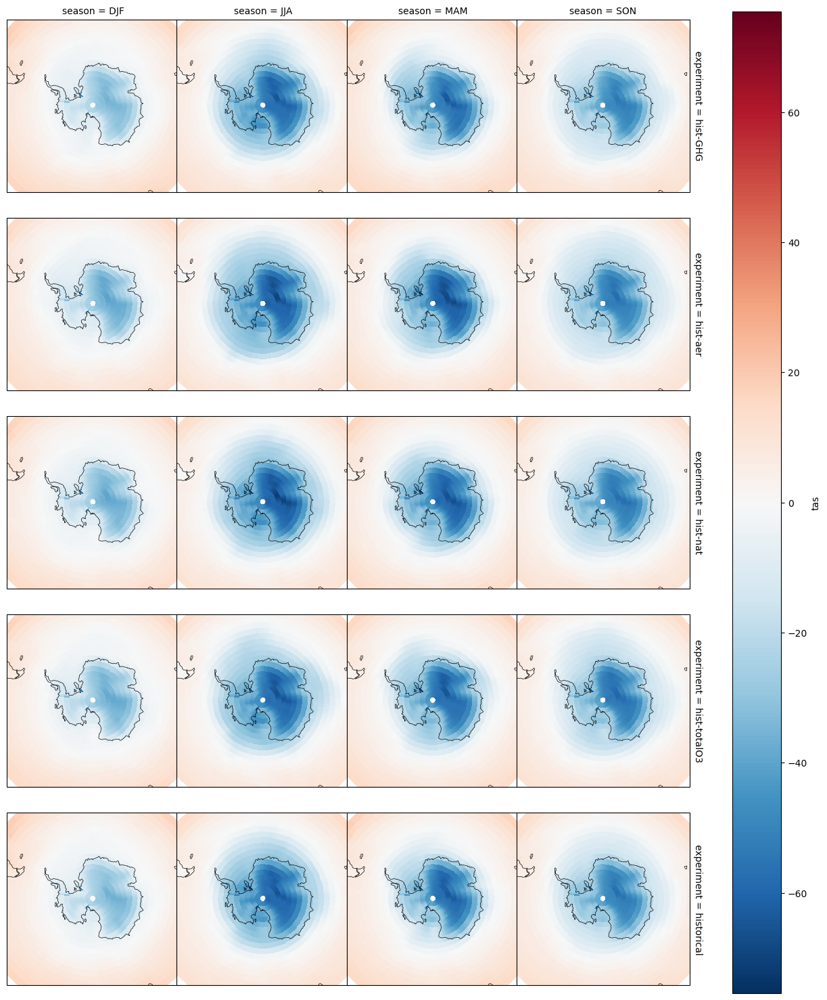

In [14]:
fg = datatree.tree_to_dataset(
    lesfmip_season_tree['CanESM5'].isel(member=0, year=-1),
    dims=['experiment'],
).tas.plot(
    col='season',
    row='experiment',
    subplot_kws={'projection': ccrs.SouthPolarStereo()},
    transform=ccrs.PlateCarree(),
)

for ax in fg.axs.flat:
    ax.set_extent([-180, 180, -90, -50], crs=ccrs.PlateCarree())
    ax.coastlines(linewidth=0.5)

In [15]:
#(t): Where this notebook saves its results
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full')

In [16]:
#(t): One node in full: a Dataset on (member, lat, lon, year, season)
lesfmip_season_tree[DEMO_MODEL][DEMO_EXPERIMENT].to_dataset()

<xarray.Dataset> Size: 491MB
Dimensions:  (member: 65, lat: 20, lon: 144, year: 164, season: 4)
Coordinates:
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
Data variables:
    tas      (member, lat, lon, year, season) float32 491MB dask.array<chunksize=(65, 4, 144, 164, 4), meta=np.ndarray>

## First Look

Every member of each experiment at the demonstration point, for one model. hist-nat (green) has only natural forcing (solar and volcanic), so its spread is what the climate does on its own; every other experiment is compared with it.

First the two ensembles every method figure below starts from: one season at the demonstration point, `DEMO_EXPERIMENT` and hist-nat, each on (member, year).

In [17]:
#(t): One model at the demonstration point, every experiment and season, loaded into memory
demo_tree = lesfmip_season_tree[DEMO_MODEL].sel(**DEMO_LATLON).load()

<xarray.DataTree 'CanESM5'>
Group: /
├── Group: /hist-GHG
│       Dimensions:  (member: 50, year: 164, season: 4)
│       Coordinates:
│         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│           lat      float64 8B -75.0
│           lon      float64 8B -180.0
│         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│       Data variables:
│           tas      (member, year, season) float32 131kB -5.347 -32.74 ... -17.87
├── Group: /hist-aer
│       Dimensions:  (member: 30, year: 164, season: 4)
│       Coordinates:
│           lon      float64 8B -180.0
│           lat      float64 8B -75.0
│         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│       Data variables:
│           tas      (member, year, season) float32 79kB -6.468 -30.91 ... -27.97 -22.45
├── Group: /hist-nat
│       Dimensions:  (member: 50, year: 164, season: 4)
│       Coordinates:
│           lon      float64 8B -180.0
│           lat      float64 8B -75.0
│         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│       Data variables:
│           tas      (member, year, season) float32 131kB -5.128 -29.54 ... -17.42
├── Group: /hist-totalO3
│       Dimensions:  (member: 10, year: 164, season: 4)
│       Coordinates:
│         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│           lon      float64 8B -180.0
│           lat      float64 8B -75.0
│         * member   (member) object 80B 'r10i1p1f1' 'r1i1p1f1' ... 'r9i1p1f1'
│         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│       Data variables:
│           tas      (member, year, season) float32 26kB -6.762 -29.19 ... -27.91 -17.75
└── Group: /historical
        Dimensions:  (member: 65, year: 164, season: 4)
        Coordinates:
            lon      float64 8B -180.0
            lat      float64 8B -75.0
          * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
          * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
          * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
        Data variables:
            tas      (member, year, season) float32 171kB -2.12 -31.11 ... -23.55 -18.04

In [18]:
#(t): The two ensembles every method figure below starts from, one season on (member, year): DEMO_EXPERIMENT
demo_experiment_da = demo_tree[DEMO_EXPERIMENT][VARIABLE.name].sel(season=DEMO_POINT['season'])

<xarray.DataArray 'tas' (member: 65, year: 164)> Size: 43kB
-2.12 -5.279 -5.385 -4.251 -5.745 -4.327 ... -2.439 -6.07 -2.589 -3.868 -4.345
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013

In [19]:
#(t): and hist-nat
demo_histnat_da = demo_tree['hist-nat'][VARIABLE.name].sel(season=DEMO_POINT['season'])

<xarray.DataArray 'tas' (member: 50, year: 164)> Size: 33kB
-5.128 -7.007 -6.779 -4.323 -6.172 -2.658 ... -7.633 -5.49 -5.762 -5.217 -4.376
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
  * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'

In [20]:
#(t): The final WINDOW years of both, on (member, year): what the tests below compare. DEMO_EXPERIMENT's
demo_experiment_final_da = demo_experiment_da.isel(year=slice(-WINDOW, None))
demo_experiment_final_da

<xarray.DataArray 'tas' (member: 65, year: 21)> Size: 5kB
-4.085 -3.57 -3.189 -3.098 -5.389 -1.828 ... -2.439 -6.07 -2.589 -3.868 -4.345
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
  * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013

In [21]:
#(t): and hist-nat's
demo_histnat_final_da = demo_histnat_da.isel(year=slice(-WINDOW, None))
demo_histnat_final_da

<xarray.DataArray 'tas' (member: 50, year: 21)> Size: 4kB
-4.043 -3.745 -3.426 -6.0 -6.079 -4.988 ... -7.633 -5.49 -5.762 -5.217 -4.376
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
  * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'

In [ ]:
#(t): Every member (thin) and the ensemble mean (thick) of each experiment at the point, in its season: one row each,
#(t): the number of members beside it
demo_experiments = [e for e in config.MAIN_EXPERIMENTS if e in demo_tree.children]
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(demo_experiments), n_cols=1, n_legends=0,
                                                  panel_width=8.5, panel_height=1.0, left_margin=1.4),
                 layout='constrained')
axes = fig.add_gridspec(len(demo_experiments), 1).subplots(sharex=True, sharey=True, squeeze=False)
for ax, experiment in zip(axes[:, 0], demo_experiments):
    experiment_members_da = demo_tree[experiment][VARIABLE.name].sel(season=DEMO_POINT['season'])
    charts.plot_lines(experiment_members_da, 'year', ax=ax, color=FORCING_COLORS[experiment], linewidth=0.4, alpha=0.35)
    charts.plot_lines(experiment_members_da.mean('member'), 'year', ax=ax, color=FORCING_COLORS[experiment],
                      linewidth=2)
    ax.set_ylabel(f"{experiment}\n({experiment_members_da.sizes['member']})", rotation=0, ha='right', va='center')
axes[-1, 0].set_xlabel('Year')
fig.suptitle(f"{DEMO_POINT['season']}, every member (thin) and the ensemble mean (thick), {VARIABLE.units}", x=0.01,
             ha='left');

## SAM Phases

Every section with a **By SAM phase** subsection (2, the width; 4, the mean; 7, the tails; 10 and 11, the probability ratios) redoes its result with the seasons of one phase of the Southern Annular Mode alone. The index is opened, and each season given its phase, here: run **one** of the next two sections, as for the data above.

**The index.** LEADER-EPESC working group 1's monthly SAM index of every LESFMIP member (notebook calc_01's `SAM_RAW_DIR`, the files `archive/draft_current_DAILY.ipynb` opened), seasonally averaged by notebook calc_01 (section 6). It is the zonal-mean index of Gong & Wang (1999): the difference between standardised zonal means at 40°S and 65°S, positive when the westerlies are strong and shifted south.

**The phases.** Each season of each member falls in one phase by its index $S$, against hist-nat's terciles $S_{1/3}$ and $S_{2/3}$ over the final $L$ years (its members and years pooled, for each model and season):

$$
\text{negative: } S < S_{1/3}, \qquad \text{neutral: } S_{1/3} \le S \le S_{2/3}, \qquad \text{positive: } S > S_{2/3}.
$$

The same thresholds serve every experiment of a model, so hist-nat has a third of its seasons in each phase, and an experiment whose SAM has shifted has more in one of them. In each phase, a result compares the experiment's seasons with hist-nat's in the same state of the SAM.

### Sample data

The sample has no SAM index, so a made-up one stands in (`sam.synthetic_index`): random noise with a summer trend in historical and hist-totalO3. It only lets the steps below run; nothing found with it means anything.

In [24]:
#(t): A synthetic index with the sample's members, years and seasons (NOT data)
sam_season_tree = sam.synthetic_index(lesfmip_season_tree, seed=0)

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (member: 50, year: 164, season: 4)
│   │       Coordinates:
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           sam      (member, year, season) float64 262kB 0.1257 -0.1321 ... -0.1916
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (member: 30, year: 164, season: 4)
│   │       Coordinates:
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           sam      (member, year, season) float64 157kB 0.6467 -0.6918 ... -0.2394
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (member: 50, year: 164, season: 4)
│   │       Coordinates:
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           sam      (member, year, season) float64 262kB 0.7715 -0.4375 ... -2.07
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (member: 10, year: 164, season: 4)
│   │       Coordinates:
│   │         * member   (member) object 80B 'r10i1p1f1' 'r1i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           sam      (member, year, season) float64 52kB 1.122 -1.1 ... 1.404 0.5487
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 65, year: 164, season: 4)
│           Coordinates:
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│           Data variables:
│               sam      (member, year, season) float64 341kB -0.1456 -0.1506 ... 1.619
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (member: 45, year: 164, season: 4)
│   │       Coordinates:
│   │         * member   (member) object 360B 'r10i1p1f2' 'r10i1p3f1' ... 'r9i1p3f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           sam      (member, year, season) float64 236kB -0.8309 0.2855 ... 0.532
│   ├── Group: /GISS-E2-1-G/hist-nat
│   │       Dimensions:  (member: 20, year: 164, season: 4)
│   │       Coordinates:
│   │         * member   (member) object 160B 'r10i1p1f3' 'r1i1p1f2' ... 'r9i1p1f3'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           sam      (member, year, season) float64 105kB 1.667 0.3983 ... 1.533 -0.3862
│   ├── Group: /GISS-E2-1-G/historical
│   │       Dimensions:  (member: 63, year: 164, season: 4)
│   │       Coordinates:
│   │         * member   (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           sam      (member, year, season) float64 331kB 0.5374 2.017 ... 1.583 1.381
│   ├── Group: /GISS-E2-1-G/hist-totalO3
│   │       Dimensions:  (memb

### Full data

The seasonal index notebook calc_01 (section 6) saved in `SCRATCH_DIR`.

In [25]:
#(t): The seasonal SAM index notebook calc_01 saved
sam_season_path = SCRATCH_DIR / 'seasonal' / 'lesfmip_sam.zarr'
sam_season_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/seasonal/lesfmip_sam.zarr')

In [26]:
sam_season_tree = xr.open_datatree(sam_season_path, engine='zarr').load()
sam_season_tree

17:36:53 INFO    extant.storage | opening /work/scratch-pw4/aborow/ExtAnt/seasonal/lesfmip_sam.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be suppor

<xarray.DataTree>
Group: /
├── Group: /NorESM2-LM
│   ├── Group: /NorESM2-LM/hist-totalO3
│   │       Dimensions:  (member: 20, year: 164, season: 4)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 160B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │       Data variables:
│   │           sam      (member, year, season) float64 105kB 1.13 0.3412 ... 0.1169 0.243
│   ├── Group: /NorESM2-LM/hist-aer
│   │       Dimensions:  (member: 23, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           sam      (member, year, season) float64 121kB -0.01399 -0.7896 ... 0.02156
│   ├── Group: /NorESM2-LM/hist-nat
│   │       Dimensions:  (member: 23, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           sam      (member, year, season) float64 121kB -0.2622 -0.94 ... -0.8976
│   ├── Group: /NorESM2-LM/historical
│   │       Dimensions:  (member: 40, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 320B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           sam      (member, year, season) float64 210kB 0.1363 -0.6822 ... 0.9998
│   └── Group: /NorESM2-LM/hist-GHG
│           Dimensions:  (member: 23, year: 164, season: 4)
│           Coordinates:
│             * member   (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│           Data variables:
│               sam      (member, year, season) float64 121kB 0.25 0.05513 ... -0.09388
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (member: 50, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           sam      (member, year, season) float64 262kB 0.9527 0.2381 ... 0.5293
│   ├── Group: /CanESM5/historical
│   │       Dimensions:  (member: 65, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           sam      (member, year, season) float64 341kB -0.1312 -0.009562 ... 0.4939
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (member: 30, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           sam      (member, year, season) float64 157kB -0.5724 -0.8401 ... 0.3812
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (member:

### Models and experiments with both

The index may not exist for every model and experiment, so every SAM subsection uses only the nodes with both (`sam_both_paths`).

In [27]:
#(t): /<model>/<experiment> of every node with the index, and with temperature
sam_paths = {node.relative_to(sam_season_tree) for node in sam_season_tree.leaves if node.data_vars}
tas_paths = {node.relative_to(lesfmip_season_tree) for node in lesfmip_season_tree.leaves if node.data_vars}
pd.DataFrame({'index': {p: p in sam_paths for p in sorted(sam_paths | tas_paths)},
              VARIABLE.name: {p: p in tas_paths for p in sorted(sam_paths | tas_paths)}})

,index,tas
CanESM5/hist-GHG,True,True
CanESM5/hist-aer,True,True
CanESM5/hist-nat,True,True
CanESM5/hist-totalO3,True,True
CanESM5/historical,True,True
GISS-E2-1-G/hist-GHG,True,True
GISS-E2-1-G/hist-aer,True,True
GISS-E2-1-G/hist-nat,True,True
GISS-E2-1-G/hist-totalO3,True,True
GISS-E2-1-G/historical,True,True


In [28]:
#(t): The ones with both
sam_both_paths = sam_paths & tas_paths
sorted(sam_both_paths)

['CanESM5/hist-GHG',
 'CanESM5/hist-aer',
 'CanESM5/hist-nat',
 'CanESM5/hist-totalO3',
 'CanESM5/historical',
 'GISS-E2-1-G/hist-GHG',
 'GISS-E2-1-G/hist-aer',
 'GISS-E2-1-G/hist-nat',
 'GISS-E2-1-G/hist-totalO3',
 'GISS-E2-1-G/historical',
 'HadGEM3-GC31-LL/hist-GHG',
 'HadGEM3-GC31-LL/hist-aer',
 'HadGEM3-GC31-LL/hist-nat',
 'HadGEM3-GC31-LL/hist-totalO3',
 'HadGEM3-GC31-LL/historical',
 'MIROC6/hist-GHG',
 'MIROC6/hist-aer',
 'MIROC6/hist-nat',
 'MIROC6/hist-totalO3',
 'MIROC6/historical',
 'MPI-ESM1-2-LR/hist-GHG',
 'MPI-ESM1-2-LR/hist-aer',
 'MPI-ESM1-2-LR/hist-nat',
 'MPI-ESM1-2-LR/hist-totalO3',
 'MPI-ESM1-2-LR/historical',
 'NorESM2-LM/hist-GHG',
 'NorESM2-LM/hist-aer',
 'NorESM2-LM/hist-nat',
 'NorESM2-LM/hist-totalO3',
 'NorESM2-LM/historical']

In [29]:
#(t): The index on those nodes only
sam_both_tree = sam_season_tree.filter(lambda node: node.relative_to(sam_season_tree) in sam_both_paths)

<xarray.DataTree>
Group: /
├── Group: /NorESM2-LM
│   ├── Group: /NorESM2-LM/hist-totalO3
│   │       Dimensions:  (member: 20, year: 164, season: 4)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 160B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │       Data variables:
│   │           sam      (member, year, season) float64 105kB 1.13 0.3412 ... 0.1169 0.243
│   ├── Group: /NorESM2-LM/hist-aer
│   │       Dimensions:  (member: 23, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           sam      (member, year, season) float64 121kB -0.01399 -0.7896 ... 0.02156
│   ├── Group: /NorESM2-LM/hist-nat
│   │       Dimensions:  (member: 23, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           sam      (member, year, season) float64 121kB -0.2622 -0.94 ... -0.8976
│   ├── Group: /NorESM2-LM/historical
│   │       Dimensions:  (member: 40, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 320B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           sam      (member, year, season) float64 210kB 0.1363 -0.6822 ... 0.9998
│   └── Group: /NorESM2-LM/hist-GHG
│           Dimensions:  (member: 23, year: 164, season: 4)
│           Coordinates:
│             * member   (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│           Data variables:
│               sam      (member, year, season) float64 121kB 0.25 0.05513 ... -0.09388
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (member: 50, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           sam      (member, year, season) float64 262kB 0.9527 0.2381 ... 0.5293
│   ├── Group: /CanESM5/historical
│   │       Dimensions:  (member: 65, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           sam      (member, year, season) float64 341kB -0.1312 -0.009562 ... 0.4939
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (member: 30, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           sam      (member, year, season) float64 157kB -0.5724 -0.8401 ... 0.3812
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (member:

### Phases

In [30]:
#(t): The index over the final WINDOW years, the years every result compares
sam_final_tree = sam_both_tree.isel(year=slice(-WINDOW, None))

<xarray.DataTree>
Group: /
├── Group: /NorESM2-LM
│   ├── Group: /NorESM2-LM/hist-totalO3
│   │       Dimensions:  (member: 20, year: 21, season: 4)
│   │       Coordinates:
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 160B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │       Data variables:
│   │           sam      (member, year, season) float64 13kB 1.349 0.04833 ... 0.1169 0.243
│   ├── Group: /NorESM2-LM/hist-aer
│   │       Dimensions:  (member: 23, year: 21, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           sam      (member, year, season) float64 15kB -1.125 0.2483 ... 0.02156
│   ├── Group: /NorESM2-LM/hist-nat
│   │       Dimensions:  (member: 23, year: 21, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           sam      (member, year, season) float64 15kB 0.3169 -0.6497 ... -0.8976
│   ├── Group: /NorESM2-LM/historical
│   │       Dimensions:  (member: 40, year: 21, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 320B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           sam      (member, year, season) float64 27kB -0.2561 -0.2155 ... 0.9998
│   └── Group: /NorESM2-LM/hist-GHG
│           Dimensions:  (member: 23, year: 21, season: 4)
│           Coordinates:
│             * member   (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│           Data variables:
│               sam      (member, year, season) float64 15kB 0.8372 0.1975 ... -0.09388
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (member: 50, year: 21, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           sam      (member, year, season) float64 34kB 0.05281 0.3509 ... 0.5293
│   ├── Group: /CanESM5/historical
│   │       Dimensions:  (member: 65, year: 21, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │         * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           sam      (member, year, season) float64 44kB 1.144 -0.3563 ... 0.4939
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (member: 30, year: 21, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           sam      (member, year, season) float64 20kB 0.2531 0.8645 ... 0.3812
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (member: 50, year: 

In [31]:
sam.TERCILES

(0.3333333333333333, 0.6666666666666666)

In [32]:
%%time
#(t): hist-nat's terciles over those years, members and years pooled, on (model, quantile, season)
sam_thresholds_ds = datatree.reduce_to_dataset(sam_final_tree.match('*/hist-nat'),
                                               partial(qc.pooled_quantiles, quantiles=sam.TERCILES))
sam_thresholds_ds = sam_thresholds_ds.sel(experiment='hist-nat', drop=True).compute()

CPU times: user 21 ms, sys: 28 μs, total: 21 ms
Wall time: 20.6 ms


<xarray.Dataset> Size: 480B
Dimensions:   (model: 6, season: 4, quantile: 2)
Coordinates:
  * model     (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * quantile  (quantile) float64 16B 0.3333 0.6667
Data variables:
    sam       (season, quantile, model) float64 384B -0.2524 nan ... 0.3778

In [33]:
#(t): The same thresholds for every experiment of a model, as a tree shaped like sam_both_tree
sam_thresholds_tree = datatree.dataset_to_tree(sam_thresholds_ds.expand_dims(experiment=config.MAIN_EXPERIMENTS),
                                               like=sam_both_tree)

In [34]:
#(t): Each season's phase: True in one of the three along 'phase', every member, year and season
sam_masks_tree = xr.map_over_datasets(sam.phase_masks, sam_both_tree, sam_thresholds_tree)

<xarray.DataTree>
Group: /
├── Group: /NorESM2-LM
│   ├── Group: /NorESM2-LM/hist-totalO3
│   │       Dimensions:   (year: 164, season: 4, member: 20, phase: 3)
│   │       Coordinates:
│   │         * year      (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member    (member) object 160B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │         * phase     (phase) <U8 96B 'negative' 'neutral' 'positive'
│   │       Data variables:
│   │           in_phase  (phase, member, year, season) bool 39kB False False ... False
│   ├── Group: /NorESM2-LM/hist-aer
│   │       Dimensions:   (season: 4, member: 23, year: 164, phase: 3)
│   │       Coordinates:
│   │         * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member    (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │         * year      (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * phase     (phase) <U8 96B 'negative' 'neutral' 'positive'
│   │       Data variables:
│   │           in_phase  (phase, member, year, season) bool 45kB False True ... True False
│   ├── Group: /NorESM2-LM/hist-nat
│   │       Dimensions:   (season: 4, member: 23, year: 164, phase: 3)
│   │       Coordinates:
│   │         * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member    (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │         * year      (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * phase     (phase) <U8 96B 'negative' 'neutral' 'positive'
│   │       Data variables:
│   │           in_phase  (phase, member, year, season) bool 45kB False True ... False False
│   ├── Group: /NorESM2-LM/historical
│   │       Dimensions:   (season: 4, member: 40, year: 164, phase: 3)
│   │       Coordinates:
│   │         * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member    (member) object 320B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │         * year      (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * phase     (phase) <U8 96B 'negative' 'neutral' 'positive'
│   │       Data variables:
│   │           in_phase  (phase, member, year, season) bool 79kB False True ... True True
│   └── Group: /NorESM2-LM/hist-GHG
│           Dimensions:   (member: 23, season: 4, year: 164, phase: 3)
│           Coordinates:
│             * member    (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year      (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│             * phase     (phase) <U8 96B 'negative' 'neutral' 'positive'
│           Data variables:
│               in_phase  (phase, member, year, season) bool 45kB False False ... False
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:   (season: 4, year: 164, member: 50, phase: 3)
│   │       Coordinates:
│   │         * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year      (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * member    (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * phase     (phase) <U8 96B 'negative' 'neutral' 'positive'
│   │       Data variables:
│   │           in_phase  (phase, member, year, season) bool 98kB False False ... False True
│   ├── Group: /CanESM5/historical
│   │       Dimensions:   (season: 4, year: 164, member: 65, phase: 3)
│   │       Coordinates:
│   │         * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year      (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * member    (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * phase     (phase) <U8 96B 'negative' 'neutral' 'positive'
│   │       Data variables:
│   │    

In [35]:
#(t): Over the final WINDOW years: the masks every SAM subsection uses
sam_final_masks_tree = sam_masks_tree.isel(year=slice(-WINDOW, None))

**How often each phase.** The share of each experiment's seasons in each phase over the final $L$ years: a third each in hist-nat, by construction, and more in the positive phase where a forcing has pushed the SAM up.

In [36]:
%%time
#(t): The share of each experiment's final-years seasons in each phase, on (model, experiment, phase, season)
sam_phase_share_ds = datatree.reduce_to_dataset(sam_final_masks_tree, lambda ds: ds.mean(['member', 'year'])).compute()
sam_phase_share_da = sam_phase_share_ds['in_phase'].rename('phase_share')
sam_phase_share_da

CPU times: user 32.3 ms, sys: 943 μs, total: 33.3 ms
Wall time: 32.8 ms


<xarray.DataArray 'phase_share' (phase: 3, season: 4, model: 6, experiment: 5)> Size: 3kB
0.2381 0.3381 0.3333 0.2429 0.1055 0.0 ... 0.3872 0.3251 0.3333 0.3714 0.4333
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'

In [37]:
#(t): DEMO_MODEL's shares, every experiment and season
sam_phase_share_da.sel(model=DEMO_MODEL).to_series().unstack('phase').round(2)

phase                negative  neutral  positive
season experiment                               
DJF    hist-GHG          0.24     0.35      0.41
       hist-aer          0.34     0.36      0.30
       hist-nat          0.33     0.33      0.33
       hist-totalO3      0.24     0.23      0.53
       historical        0.11     0.23      0.66
JJA    hist-GHG          0.29     0.29      0.42
       hist-aer          0.39     0.31      0.30
       hist-nat          0.33     0.33      0.33
       hist-totalO3      0.35     0.34      0.31
       historical        0.29     0.32      0.39
MAM    hist-GHG          0.20     0.32      0.49
       hist-aer          0.39     0.32      0.29
       hist-nat          0.33     0.33      0.33
       hist-totalO3      0.29     0.32      0.39
       historical        0.20     0.31      0.49
SON    hist-GHG          0.29     0.33      0.38
       hist-aer          0.38     0.30      0.32
       hist-nat          0.33     0.33      0.33
       hist-totalO3      0.30     0.35      0.35
       historical        0.23     0.31      0.46

**The forced change of the index.** Each experiment's ensemble-mean index over the final $L$ years minus hist-nat's, as for the mean of temperature (section 4).

In [38]:
#(t): The ensemble-mean index over the final WINDOW years, on (model, experiment, season)
sam_final_mean_ds = datatree.reduce_to_dataset(sam_final_tree, lambda ds: ds.mean(['member', 'year']))

<xarray.Dataset> Size: 1kB
Dimensions:     (model: 6, experiment: 5, season: 4)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
Data variables:
    sam         (season, model, experiment) float64 960B 0.206 ... 0.1979

In [39]:
#(t): Each experiment minus hist-nat over the same years
sam_change_ds = sam_final_mean_ds - sam_final_mean_ds.sel(experiment='hist-nat')

In [40]:
sam_change_da = sam_change_ds['sam'].drop_sel(experiment='hist-nat').rename('sam_change')
sam_change_da.to_dataframe().unstack('season').round(2)

sam_change                  
season                              DJF   JJA   MAM   SON
model           experiment                               
CanESM5         hist-GHG           0.18  0.12  0.18  0.11
                hist-aer          -0.05 -0.07 -0.07 -0.04
                hist-totalO3       0.34 -0.08  0.08  0.06
                historical         0.60  0.10  0.19  0.24
GISS-E2-1-G     hist-GHG            NaN   NaN   NaN   NaN
                hist-aer            NaN   NaN   NaN   NaN
                hist-totalO3        NaN   NaN   NaN   NaN
                historical          NaN   NaN   NaN   NaN
HadGEM3-GC31-LL hist-GHG            NaN   NaN   NaN   NaN
                hist-aer            NaN   NaN   NaN   NaN
                hist-totalO3        NaN   NaN   NaN   NaN
                historical          NaN   NaN   NaN   NaN
MIROC6          hist-GHG            NaN   NaN   NaN   NaN
                hist-aer            NaN   NaN   NaN   NaN
                hist-totalO3        NaN   NaN   NaN   NaN
                historical          NaN   NaN   NaN   NaN
MPI-ESM1-2-LR   hist-GHG           0.15  0.14  0.14  0.12
                hist-aer          -0.02 -0.12 -0.04 -0.05
                hist-totalO3       0.24 -0.00  0.03  0.09
                historical         0.43  0.07  0.13  0.18
NorESM2-LM      hist-GHG           0.12  0.12  0.04  0.09
                hist-aer          -0.01  0.07 -0.00 -0.01
                hist-totalO3       0.32  0.01  0.04  0.08
                historical         0.43  0.14  0.08  0.17

In [41]:
#(t): Saved for notebooks plot_03 to plot_06
sam_phase_share_path = RESULTS_DIR / 'sam_phase_share.zarr'
sam_phase_share_da.to_dataset(name='phase_share').to_zarr(sam_phase_share_path, mode='w')
sam_phase_share_path

17:36:54 INFO    extant.storage | writing DataArray (phase: 3, season: 4, model: 6, experiment: 5) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_phase_share.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `<U8` is currently not part in the Zarr format 3 specification. It may not be supported by

17:36:54 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_phase_share.zarr
17:36:54 INFO    extant.storage | writing DataArray (season: 4, model: 6, experiment: 4) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_change.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/api/asynchronous.py:227: UserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be suppo

17:36:55 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_change.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/api/asynchronous.py:227: UserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


In [ ]:
#(t): Saved for notebooks plot_03 to plot_06
sam_change_path = RESULTS_DIR / 'sam_change.zarr'
sam_change_da.to_dataset(name='sam_change').to_zarr(sam_change_path, mode='w')
sam_change_path

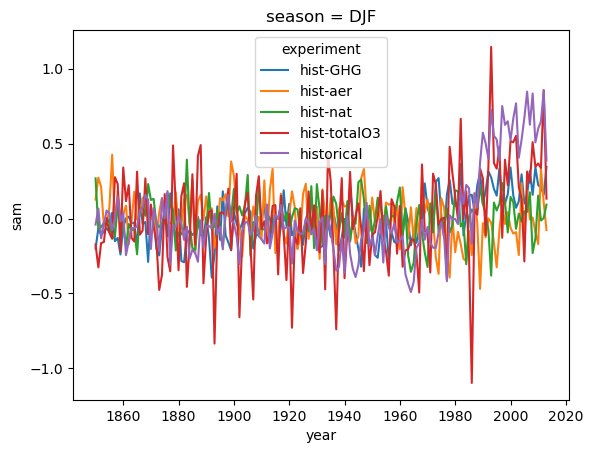

In [42]:
#(t): Quick look: DEMO_MODEL's ensemble-mean index, every experiment, DJF
datatree.tree_to_dataset(sam_both_tree[DEMO_MODEL].mean('member'), dims=['experiment'])['sam'].sel(season='DJF').plot(
    x='year', hue='experiment');

**At the demonstration point.** The index of hist-nat and `DEMO_EXPERIMENT` over the final years in `DEMO_POINT`'s season, cut at hist-nat's terciles, and the temperature of each phase's seasons.

In [43]:
#(t): hist-nat's index over the final years in DEMO_POINT's season, on (member, year)
demo_sam_histnat_da = sam_final_tree[DEMO_MODEL]['hist-nat']['sam'].sel(season=DEMO_POINT['season'])
demo_sam_histnat_da

<xarray.DataArray 'sam' (member: 50, year: 21)> Size: 8kB
0.05281 -0.002868 -0.6941 -0.232 1.204 ... 0.2346 1.216 -0.5051 0.05963 0.01566
Coordinates:
    season   <U3 12B 'DJF'
  * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
  * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
Attributes: (1)

In [44]:
#(t): DEMO_EXPERIMENT's
demo_sam_experiment_da = sam_final_tree[DEMO_MODEL][DEMO_EXPERIMENT]['sam'].sel(season=DEMO_POINT['season'])
demo_sam_experiment_da

<xarray.DataArray 'sam' (member: 65, year: 21)> Size: 11kB
1.144 0.5268 0.9212 0.6319 1.748 0.4211 ... 1.831 0.4806 0.568 -0.7177 0.5646
Coordinates:
    season   <U3 12B 'DJF'
  * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
  * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
Attributes: (1)

In [45]:
#(t): hist-nat's terciles, on (quantile,)
demo_sam_thresholds_da = sam_thresholds_ds['sam'].sel(model=DEMO_MODEL, season=DEMO_POINT['season'])
demo_sam_thresholds_da

<xarray.DataArray 'sam' (quantile: 2)> Size: 16B
-0.2524 0.4463
Coordinates:
    model     <U7 28B 'CanESM5'
    season    <U3 12B 'DJF'
  * quantile  (quantile) float64 16B 0.3333 0.6667

In [46]:
#(t): hist-nat's temperature at the point in each phase (demo_histnat_final_da: A first look), on (phase, member, year)
demo_phase_histnat_da = sam.by_phase(demo_histnat_final_da,
                                     sam_final_masks_tree[DEMO_MODEL]['hist-nat'].to_dataset().sel(season=DEMO_POINT['season']))
demo_phase_histnat_da

<xarray.DataArray 'tas' (member: 50, year: 21, phase: 3)> Size: 13kB
nan -4.043 nan nan -3.745 nan -3.426 nan ... nan nan -5.217 nan nan -4.376 nan
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
  * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
  * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'

In [47]:
#(t): DEMO_EXPERIMENT's
demo_phase_experiment_da = sam.by_phase(
    demo_experiment_final_da, sam_final_masks_tree[DEMO_MODEL][DEMO_EXPERIMENT].to_dataset().sel(season=DEMO_POINT['season']))
demo_phase_experiment_da

<xarray.DataArray 'tas' (member: 65, year: 21, phase: 3)> Size: 16kB
nan nan -4.085 nan nan -3.57 nan nan ... -2.589 -3.868 nan nan nan nan -4.345
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
  * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
  * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'

In [48]:
#(t): Quick look: the number of seasons in each phase, and their mean temperature
pd.DataFrame({'seasons, hist-nat': demo_phase_histnat_da.count(['member', 'year']).to_series(),
              f'seasons, {DEMO_EXPERIMENT}': demo_phase_experiment_da.count(['member', 'year']).to_series(),
              'mean, hist-nat': demo_phase_histnat_da.mean(['member', 'year']).to_series(),
              f'mean, {DEMO_EXPERIMENT}': demo_phase_experiment_da.mean(['member', 'year']).to_series()}).round(2)

,"seasons, hist-nat","seasons, historical","mean, hist-nat","mean, historical"
phase,,,,
negative,350,144,-4.99,-4.22
neutral,350,315,-4.90,-4.19
positive,350,906,-5.17,-4.01


In [ ]:
#(t): The SAM phases at the point: a) the index of both ensembles over the final years, cut at hist-nat's terciles
#(t): (dashed); b-d) temperature in each phase's seasons, both ensembles, with their means, on the same bins
sam_phases = list(demo_phase_histnat_da['phase'].values)
phase_edges_arr = np.linspace(float(min(demo_phase_histnat_da.min(), demo_phase_experiment_da.min())),
                              float(max(demo_phase_histnat_da.max(), demo_phase_experiment_da.max())), 21)
fig = plt.figure(figsize=(12, 7.5), layout='constrained')
#(c): The index across the top, a panel per phase under it
grid = fig.add_gridspec(2, 1)
index_ax = fig.add_subplot(grid[0])
phase_axes = grid[1].subgridspec(1, len(sam_phases)).subplots(squeeze=False)
methods.plot_sam_index(demo_sam_histnat_da, demo_sam_experiment_da, demo_sam_thresholds_da, DEMO_EXPERIMENT,
                       ax=index_ax)
index_ax.set_title("a) The SAM index over the final years, cut at hist-nat's terciles (dashed)", loc='left')
index_ax.set_xlabel('SAM index')
index_ax.set_ylabel('Density')
for ax, letter, phase in zip(phase_axes[0], 'bcd', sam_phases):
    methods.plot_phase_temperatures(demo_phase_histnat_da.sel(phase=phase), demo_phase_experiment_da.sel(phase=phase),
                                    DEMO_EXPERIMENT, units=VARIABLE.units, edges=phase_edges_arr, ax=ax)
    ax.set_title(f'{letter}) {phase.capitalize()} SAM', loc='left', color=methods.PHASE_COLORS[phase])
    ax.set_xlabel(VARIABLE.units)
phase_axes[0, 0].set_ylabel('Density')
fig.suptitle(f'The SAM phases: {DEMO_EXPERIMENT} against hist-nat at the point', x=0.01, ha='left');

## 1. Quantile Change Relative to hist-nat

**Rolling quantiles.** For each year $t$, every member's values in the $L$ years centred on $t$ are pooled and their quantiles taken:

$$
Q_p(t) = Q_p\left(\{\,x_{m,y} : m = 1,\ldots,M,\ |y - t| \le \tfrac{L-1}{2}\,\}\right),
$$

so each comes from $M \times L$ values (over a thousand for 50 members). Windows that run off either end of the record are left out.

**Smoothing.** The rolling quantiles are then smoothed with LOWESS (local linear regression, 81-year span), giving $\tilde{Q}_p(t)$.

**The change.** Each experiment's smoothed quantiles minus hist-nat's quantiles over its whole record (members and years pooled):

$$
\Delta Q_p(t) = \tilde{Q}_p^{\,\mathrm{exp}}(t) - Q_p^{\,\mathrm{nat}}.
$$

The change in the width of the distribution between two quantiles is then the difference of their changes. Taking anomalies first gives the same thing:

$$
\Delta W(t) = \Delta Q_{95}(t) - \Delta Q_{05}(t) = \left(\tilde{Q}_{95}^{\,\mathrm{exp}} - \tilde{Q}_{05}^{\,\mathrm{exp}}\right) - \left(Q_{95}^{\,\mathrm{nat}} - Q_{05}^{\,\mathrm{nat}}\right),
$$

which is the same as differencing the widths (as in Bracegirdle et al., 2024).

How one point of a rolling quantile is made, at the demonstration point:

In [50]:
#(t): The rolling quantiles of DEMO_EXPERIMENT at the point, on (quantile, year): for each year, every member's values
#(t): in the WINDOW years centred on it pooled
demo_rolling_da = qc.centred_rolling_quantiles(demo_experiment_da, window=WINDOW, quantiles=QUANTILES)
demo_rolling_da

<xarray.DataArray 'tas' (quantile: 7, year: 164)> Size: 9kB
nan nan nan nan nan nan nan nan nan nan ... nan nan nan nan nan nan nan nan nan
Coordinates:
    lon       float64 8B -180.0
    lat       float64 8B -75.0
    season    <U3 12B 'DJF'
  * year      (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
  * quantile  (quantile) float64 56B 0.01 0.05 0.1 0.5 0.9 0.95 0.99

In [51]:
#(t): Check by hand: the window centred on 1960 runs from 1960 - WINDOW // 2 to 1960 + WINDOW // 2, every member
window_arr = demo_experiment_da.sel(year=slice(1960 - WINDOW // 2, 1960 + WINDOW // 2)).values.ravel()
window_arr.shape

(1365,)

In [52]:
#(t): numpy's quantiles of those values, next to the rolling quantiles of 1960
pd.DataFrame({'np.nanquantile': np.nanquantile(window_arr, QUANTILES),
              'centred_rolling_quantiles': demo_rolling_da.sel(year=1960).values},
             index=pd.Index(QUANTILES, name='quantile'))

,np.nanquantile,centred_rolling_quantiles
quantile,,
0.01,-7.401801,-7.401801
0.05,-6.509661,-6.509661
0.10,-6.244239,-6.244239
0.50,-4.737375,-4.737375
0.90,-2.293840,-2.293840
0.95,-1.874383,-1.874383
0.99,-1.436159,-1.436159


In [53]:
#(t): Check: the years with a complete window. The first and last WINDOW // 2 years have none, so they are NaN
demo_rolling_da.dropna('year').year

<xarray.DataArray 'year' (year: 144)> Size: 1kB
1860 1861 1862 1863 1864 1865 1866 1867 ... 1997 1998 1999 2000 2001 2002 2003
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * year     (year) int64 1kB 1860 1861 1862 1863 1864 ... 2000 2001 2002 2003

In [ ]:
#(t): How one point of a rolling quantile is made: a) every member, the WINDOW years around 1960 shaded; b) their values
#(t): pooled, with Q05, Q50 and Q95; c) the rolling quantiles through time, 1960 marked. All on one y axis
fig = plt.figure(figsize=(11.5, 3.9), layout='constrained')
#(c): Three panels, the middle one narrow
members_ax, values_ax, rolling_ax = fig.add_gridspec(1, 3, width_ratios=[4.2, 1.5, 4.2]).subplots()
methods.plot_window(demo_experiment_da, 1960, WINDOW, color=FORCING_COLORS[DEMO_EXPERIMENT], ax=members_ax)
methods.plot_window_values(demo_experiment_da, 1960, WINDOW, color=FORCING_COLORS[DEMO_EXPERIMENT],
                           ax=values_ax)
methods.plot_rolling_quantiles(demo_rolling_da, 1960, ax=rolling_ax)
#(c): One y axis for the three
for ax in (values_ax, rolling_ax):
    ax.sharey(members_ax)
    ax.tick_params(axis='y', labelleft=False)
n_window_values = int(demo_experiment_da.sel(year=slice(1960 - WINDOW // 2, 1960 + WINDOW // 2)).notnull().sum())
members_ax.set_title(f'a) Every member; the {WINDOW} years around 1960', loc='left')
members_ax.set_xlabel('Year')
members_ax.set_ylabel(VARIABLE.units)
values_ax.set_title(f'b) {n_window_values} values', loc='left')
values_ax.set_xlabel('Count')
rolling_ax.set_title('c) Rolling quantiles: one window per year', loc='left')
rolling_ax.set_xlabel('Year (window centre)')
fig.suptitle(f'How a rolling quantile is made: {DEMO_EXPERIMENT} at the point', x=0.01, ha='left');

Now everywhere: hist-nat's whole-record quantiles, and the rolling quantiles of every model and experiment (numba, on the cluster), then smoothed.

In [56]:
#(t): hist-nat alone: its node in every model
lesfmip_hist_nat_tree = lesfmip_season_tree.match('*/hist-nat')

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/hist-nat
│           Dimensions:  (member: 50, lat: 20, lon: 144, year: 164, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│             * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 378MB dask.array<chunksize=(50, 4, 144, 164, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/hist-nat
│           Dimensions:  (member: 20, lat: 20, lon: 144, year: 164, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│             * member   (member) object 160B 'r10i1p1f3' 'r1i1p1f2' ... 'r9i1p1f3'
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 151MB dask.array<chunksize=(20, 4, 144, 164, 4), meta=np.ndarray>
├── Group: /NorESM2-LM
│   └── Group: /NorESM2-LM/hist-nat
│           Dimensions:  (member: 23, lat: 20, lon: 144, year: 164, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 174MB dask.array<chunksize=(23, 4, 144, 164, 4), meta=np.ndarray>
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/hist-nat
│           Dimensions:  (member: 60, lat: 20, lon: 144, year: 164, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * member   (member) object 480B 'r10i1p1f3' 'r11i1p1f3' ... 'r9i1p1f3'
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 453MB dask.array<chunksize=(60, 4, 144, 164, 4), meta=np.ndarray>
├── Group: /MIROC6
│   └── Group: /MIROC6/hist-nat
│           Dimensions:  (member: 50, lat: 20, lon: 144, year: 164, season: 4)
│           Coordinates:
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * member   (member) object 400B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 378MB dask.array<chunksize=(50, 4, 144, 164, 4), meta=np.ndarray>
└── Group: /MPI-ESM1-2-LR
    └── Group: /MPI-ESM1-2-LR/hist-nat
            Dimensions:  (member: 30, lat: 20, lon: 144, year: 164, season: 4)
            Coordinates:
              * lon      (lon) float64 1kB -180.0 -1

In [57]:
%%time
#(t): hist-nat's quantiles over its whole record, members and years pooled
q_histnat_base_ds = datatree.reduce_to_dataset(lesfmip_hist_nat_tree, partial(qc.pooled_quantiles, quantiles=QUANTILES))
q_histnat_base_ds = q_histnat_base_ds.sel(experiment='hist-nat', drop=True).compute()
q_histnat_base_ds

CPU times: user 44.3 ms, sys: 4.87 ms, total: 49.2 ms
Wall time: 5.16 s


In [58]:
WINDOW, QUANTILES

(21, array([0.01, 0.05, 0.1 , 0.5 , 0.9 , 0.95, 0.99]))

In [59]:
%%time
#(t): Centred rolling quantiles of every model and experiment: they pool the members, so one Dataset
rolling_quantiles_ds = datatree.reduce_to_dataset(
    lesfmip_season_tree,
    partial(qc.centred_rolling_quantiles, window=WINDOW, quantiles=QUANTILES),
).persist()
wait(rolling_quantiles_ds)
rolling_quantiles_ds

CPU times: user 177 ms, sys: 5.68 ms, total: 183 ms
Wall time: 24.7 s


<xarray.Dataset> Size: 3GB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144,
                 year: 164, quantile: 7)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
  * quantile    (quantile) float64 56B 0.01 0.05 0.1 0.5 0.9 0.95 0.99
Data variables:
    tas         (lat, lon, season, quantile, year, model, experiment) float64 3GB dask.array<chunksize=(4, 144, 4, 7, 164, 1, 1), meta=np.ndarray>

In [60]:
%%time
#(t): The rolling quantiles smoothed with LOWESS (81 years)
smooth_quantiles_ds = qc.lowess_matrix_xarray(rolling_quantiles_ds).compute()
smooth_quantiles_ds

CPU times: user 1.47 s, sys: 2.96 s, total: 4.43 s
Wall time: 58.8 s


In [61]:
smooth_quantiles_ds = smooth_quantiles_ds.dropna(dim='year')
smooth_quantiles_ds

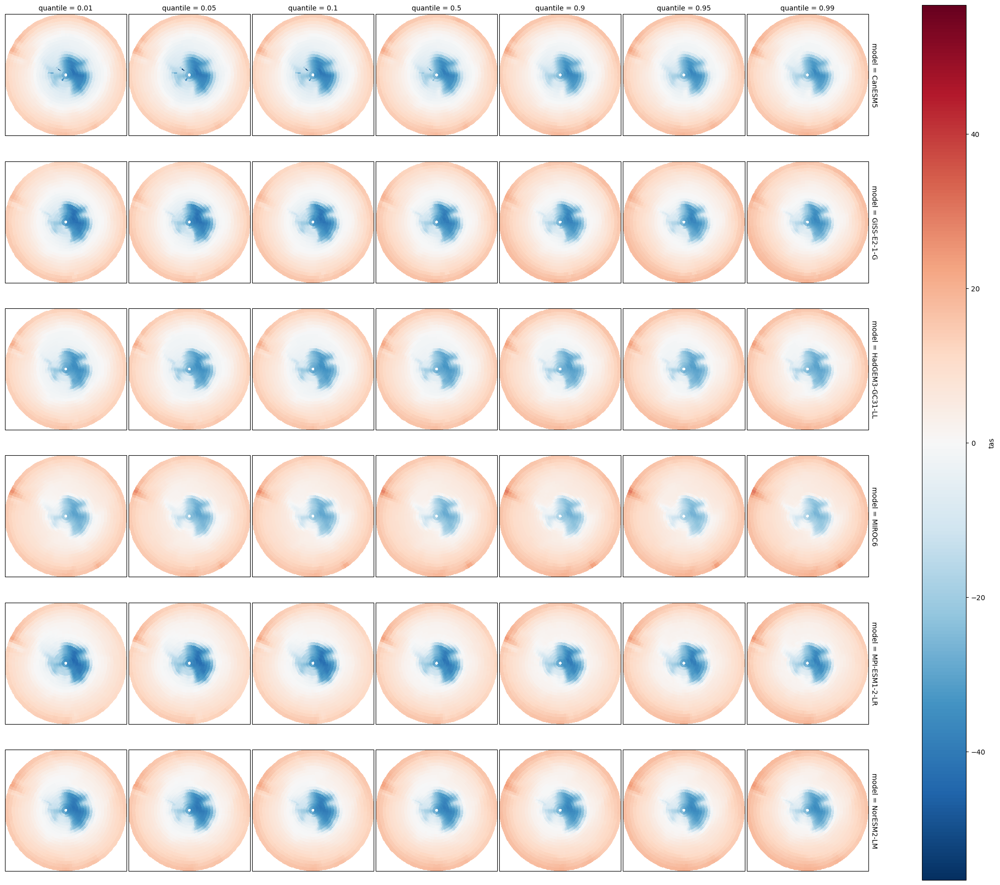

In [62]:
q_histnat_base_ds.tas.sel(season='DJF').plot(col='quantile', row='model',
                                             subplot_kws={'projection': ccrs.SouthPolarStereo()}, transform=ccrs.PlateCarree())

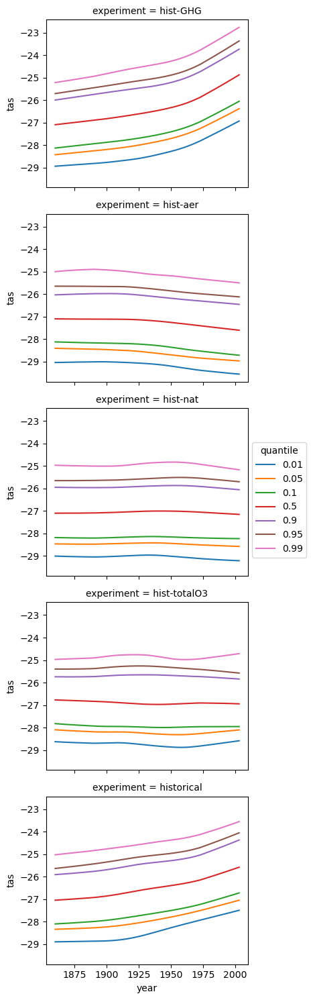

In [63]:
smooth_quantiles_ds.tas.isel(model=0, season=0, lat=0, lon=0).plot(row='experiment', hue='quantile')

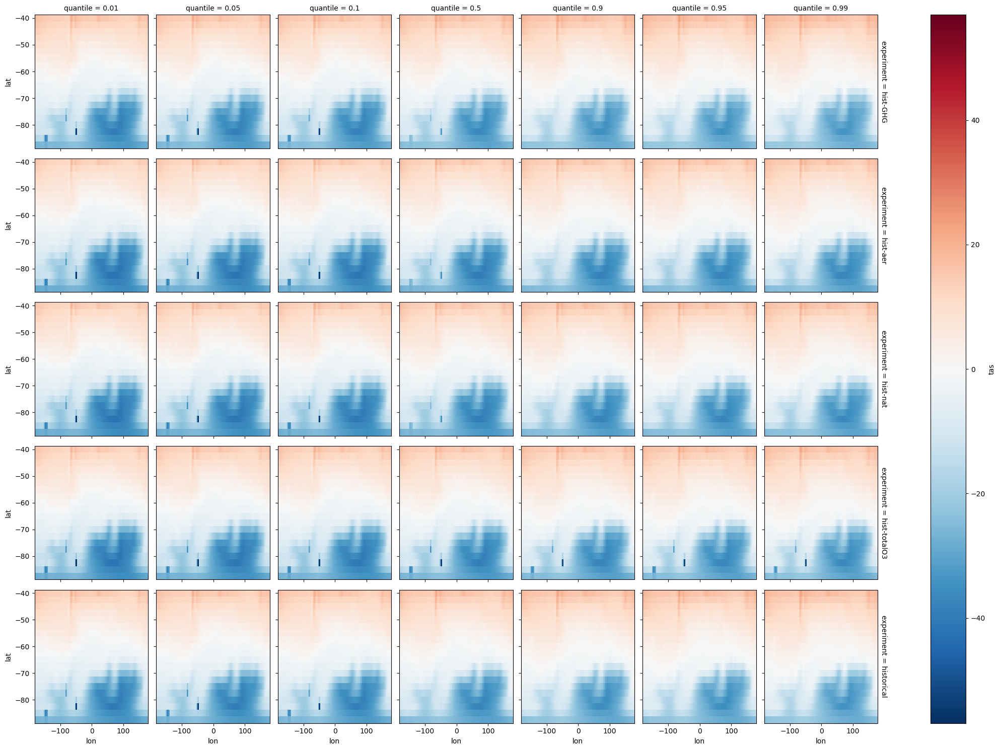

In [64]:
smooth_quantiles_ds.tas.isel(model=0, season=0, year=-1).plot(col='quantile', row='experiment')

In [65]:
q_histnat_base_ds

<xarray.Dataset> Size: 4MB
Dimensions:   (model: 6, lon: 144, lat: 20, season: 4, quantile: 7)
Coordinates:
  * model     (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon       (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat       (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * quantile  (quantile) float64 56B 0.01 0.05 0.1 0.5 0.9 0.95 0.99
Data variables:
    tas       (lat, lon, season, quantile, model) float64 4MB -29.08 ... 14.84

In [66]:
smooth_quantiles_ds

<xarray.Dataset> Size: 3GB
Dimensions:     (lat: 20, lon: 144, season: 4, quantile: 7, model: 6,
                 experiment: 5, year: 144)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1860 1861 1862 1863 ... 2000 2001 2002 2003
  * quantile    (quantile) float64 56B 0.01 0.05 0.1 0.5 0.9 0.95 0.99
Data variables:
    tas         (lat, lon, season, quantile, model, experiment, year) float64 3GB ...

In [67]:
#(t): Saved for notebooks plot_03 to plot_06
q_histnat_base_path = RESULTS_DIR / 'q_histnat_base.zarr'
q_histnat_base_ds.to_zarr(q_histnat_base_path, mode='w')
q_histnat_base_path

17:38:50 INFO    extant.storage | writing Dataset (model: 6, lon: 144, lat: 20, season: 4, quantile: 7) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/q_histnat_base.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:38:50 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/q_histnat_base.zarr
17:38:50 INFO    extant.storage | writing Dataset (model: 6, experiment: 5, season: 4, lat: 20, lon: 144, year: 164, quantile: 7) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/rolling_quantiles.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:38:54 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/rolling_quantiles.zarr
17:38:54 INFO    extant.storage | writing Dataset (lat: 20, lon: 144, season: 4, quantile: 7, model: 6, experiment: 5, year: 144) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/smooth_quantiles.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:39:05 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/smooth_quantiles.zarr
CPU times: user 15.2 s, sys: 4.49 s, total: 19.7 s
Wall time: 15.6 s


PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/smooth_quantiles.zarr')

In [ ]:
%%time
#(t): Saved for notebook plot_03; loaded from the cluster first, so it is written in one piece
rolling_quantiles_path = RESULTS_DIR / 'rolling_quantiles.zarr'
rolling_quantiles_ds.load().to_zarr(rolling_quantiles_path, mode='w')
rolling_quantiles_path

In [ ]:
#(t): Saved for notebooks plot_03 to plot_06
smooth_quantiles_path = RESULTS_DIR / 'smooth_quantiles.zarr'
smooth_quantiles_ds.to_zarr(smooth_quantiles_path, mode='w')
smooth_quantiles_path

The smoothing, and the change against hist-nat, at the demonstration point. First the point is picked out of the three results, printed and plotted plainly; then the two method figures, which are given exactly these arrays: on the left, thin lines are the rolling quantiles and thick the smoothed ones; on the right, $\Delta Q_{05}$ and $\Delta Q_{95}$, with the change in width as the gap between them.

In [68]:
#(t): The demonstration point picked out of the rolling quantiles, on (experiment, quantile, year)
point_rolling_da = rolling_quantiles_ds[VARIABLE.name].sel(**DEMO_SEL).sel(**DEMO_LATLON)
point_rolling_da

<xarray.DataArray 'tas' (quantile: 7, year: 164, experiment: 5)> Size: 46kB
dask.array<chunksize=(7, 164, 1), meta=np.ndarray>
Coordinates:
    model       <U7 28B 'CanESM5'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
    season      <U3 12B 'DJF'
    lat         float64 8B -75.0
    lon         float64 8B -180.0
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
  * quantile    (quantile) float64 56B 0.01 0.05 0.1 0.5 0.9 0.95 0.99

In [69]:
#(t): out of the smoothed ones, on (experiment, quantile, year)
point_smooth_da = smooth_quantiles_ds[VARIABLE.name].sel(**DEMO_SEL).sel(**DEMO_LATLON)

<xarray.DataArray 'tas' (quantile: 7, experiment: 5, year: 144)> Size: 40kB
-7.864 -7.862 -7.861 -7.859 -7.857 -7.856 ... -1.104 -1.096 -1.088 -1.08 -1.072
Coordinates:
    model       <U7 28B 'CanESM5'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
    season      <U3 12B 'DJF'
    lat         float64 8B -75.0
    lon         float64 8B -180.0
  * year        (year) int64 1kB 1860 1861 1862 1863 ... 2000 2001 2002 2003
  * quantile    (quantile) float64 56B 0.01 0.05 0.1 0.5 0.9 0.95 0.99

In [70]:
#(t): and out of hist-nat's whole-record quantiles, on (quantile)
point_base_da = q_histnat_base_ds[VARIABLE.name].sel(**DEMO_SEL).sel(**DEMO_LATLON)

<xarray.DataArray 'tas' (quantile: 7)> Size: 56B
-7.831 -7.097 -6.746 -5.196 -2.66 -2.166 -1.521
Coordinates:
    model     <U7 28B 'CanESM5'
    lon       float64 8B -180.0
    lat       float64 8B -75.0
    season    <U3 12B 'DJF'
  * quantile  (quantile) float64 56B 0.01 0.05 0.1 0.5 0.9 0.95 0.99

In [71]:
#(t): The change: the smoothed quantiles minus hist-nat's whole record, on (experiment, quantile, year)
point_change_da = point_smooth_da - point_base_da

<xarray.DataArray 'tas' (quantile: 7, experiment: 5, year: 144)> Size: 40kB
-0.03302 -0.03135 -0.02973 -0.02813 -0.02658 ... 0.4246 0.4328 0.441 0.4492
Coordinates:
    model       <U7 28B 'CanESM5'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
    season      <U3 12B 'DJF'
    lat         float64 8B -75.0
    lon         float64 8B -180.0
  * year        (year) int64 1kB 1860 1861 1862 1863 ... 2000 2001 2002 2003
  * quantile    (quantile) float64 56B 0.01 0.05 0.1 0.5 0.9 0.95 0.99

In [72]:
#(t): The numbers in the last year with a complete window: hist-nat's base, the smoothed quantiles, and the change
final_year = int(point_smooth_da.year[config.LAST_FULL_YEAR])
pd.DataFrame({
    'point_base_da': point_base_da.values,
    f'point_smooth_da ({DEMO_EXPERIMENT}, {final_year})': point_smooth_da.sel(experiment=DEMO_EXPERIMENT, year=final_year).values,
    'point_change_da': point_change_da.sel(experiment=DEMO_EXPERIMENT, year=final_year).values,
}, index=pd.Index(point_base_da['quantile'].values, name='quantile')).round(2)

,point_base_da,"point_smooth_da (historical, 1993)",point_change_da
quantile,,,
0.01,-7.83,-6.84,0.99
0.05,-7.10,-6.31,0.79
0.10,-6.75,-5.97,0.78
0.50,-5.20,-4.35,0.84
0.90,-2.66,-2.05,0.61
0.95,-2.17,-1.69,0.47
0.99,-1.52,-1.15,0.37


In [74]:
DEMO_EXPERIMENT, QRANGE_QUANTILES

('historical', (0.05, 0.95))

In [75]:
#(t): The change in the two quantiles of the width test, for DEMO_EXPERIMENT
low_da = point_change_da.sel(experiment=DEMO_EXPERIMENT, quantile=Q_LOW)
high_da = point_change_da.sel(experiment=DEMO_EXPERIMENT, quantile=Q_HIGH)
high_da

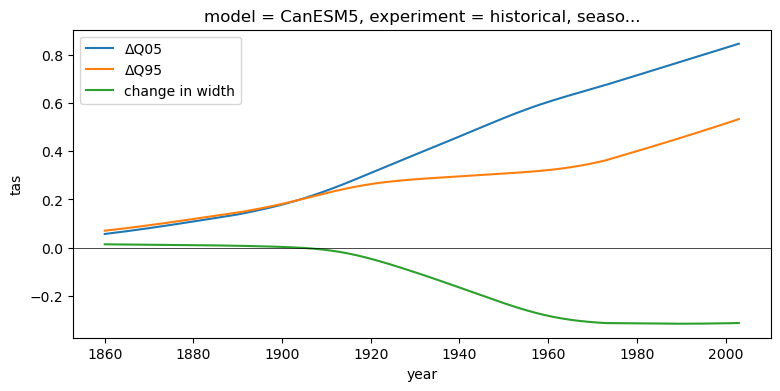

In [76]:
#(t): Quick look: the two, and the change in width between them
fig, ax = plt.subplots(figsize=(9, 4))
low_da.plot(ax=ax, label=f'ΔQ{Q_LOW * 100:02.0f}')
high_da.plot(ax=ax, label=f'ΔQ{Q_HIGH * 100:02.0f}')
(high_da - low_da).plot(ax=ax, label='change in width')
ax.axhline(0, color='k', lw=0.5)
ax.legend();

In [ ]:
#(t): The rolling quantiles before (thin) and after (thick) LOWESS smoothing, at the point
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=1, n_legends=0, panel_width=8.0, panel_height=2.8),
                 layout='constrained')
axes = fig.add_gridspec(1, 1).subplots(squeeze=False)
methods.plot_smoothing(point_rolling_da.sel(experiment=DEMO_EXPERIMENT), point_smooth_da.sel(experiment=DEMO_EXPERIMENT),
                       ax=axes[0, 0])
axes[0, 0].set_title('Rolling quantiles (thin) and LOWESS-smoothed (thick)', loc='left')
axes[0, 0].set_xlabel('Year (window centre)')
axes[0, 0].set_ylabel(VARIABLE.units)
fig.suptitle(f'The smoothing: {DEMO_EXPERIMENT} at the point', x=0.01, ha='left');

In [ ]:
#(t): The change in each quantile: a) the smoothed quantiles of DEMO_EXPERIMENT and hist-nat, hist-nat's whole-record
#(t): quantiles dotted; b) DEMO_EXPERIMENT's minus hist-nat's whole record, the gap between the two the change in width
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=2, n_legends=0, panel_width=5.0, panel_height=3.0,
                                                  column_gap=0.75), layout='constrained')
axes = fig.add_gridspec(1, 2).subplots(squeeze=False)
methods.plot_smoothed_quantiles(point_smooth_da.sel(experiment=[DEMO_EXPERIMENT, 'hist-nat']), point_base_da,
                                DEMO_EXPERIMENT, quantiles=QRANGE_QUANTILES, ax=axes[0, 0])
methods.plot_quantile_changes(point_smooth_da.sel(experiment=[DEMO_EXPERIMENT, 'hist-nat']), point_base_da,
                              DEMO_EXPERIMENT, quantiles=QRANGE_QUANTILES, ax=axes[0, 1])
axes[0, 0].set_title('a) Smoothed quantiles', loc='left')
axes[0, 0].set_ylabel(VARIABLE.units)
axes[0, 1].set_title(f"b) {DEMO_EXPERIMENT} minus hist-nat's whole record", loc='left')
for ax in axes[0]:
    ax.set_xlabel('Year (window centre)')
fig.suptitle(f'The change in each quantile: {DEMO_EXPERIMENT} at the point', x=0.01, ha='left');

## 2. Change in Width: the hist-nat Bootstrap

**The question.** Has the distribution got wider or narrower, by more than natural variability can produce? The width is $W = Q_{95} - Q_{05}$ of the pooled values (members and years), and the change is the experiment's width over the final $L$ years minus hist-nat's over the same years:

$$
\Delta W_{\mathrm{obs}} = W\left(x^{\mathrm{exp}}_{\text{final } L \text{ years}}\right) - W\left(x^{\mathrm{nat}}_{\text{final } L \text{ years}}\right).
$$

**The test** compares the experiment's width with the widths hist-nat gives on its own over the same years. Trial $k$ draws $n = 10$ different hist-nat members, pools their values over the final $L$ years ($nL = 210$ values) and takes their width:

$$
W_k = W\left(x^{\mathrm{nat}}_{m \in S_k,\ \text{final } L \text{ years}}\right), \qquad k = 1, \ldots, N.
$$

Each $W_k$ is a width that natural variability and a 10-member sample give over those years, with the same volcanoes and sun as the experiment's. The two-sided p-value counts the trials at least as wide, or at least as narrow, as the experiment:

$$
p = \min\left(1,\ \frac{2\,\min\left(1 + \#\{W_k \ge W_{\mathrm{exp}}\},\ 1 + \#\{W_k \le W_{\mathrm{exp}}\}\right)}{N + 1}\right),
$$

and the change is significant where $p < \alpha = 0.05$, i.e. where the experiment's width is outside the trials' central 95%. Nothing is subtracted for the test; $\Delta W_{\mathrm{obs}}$ is what the figures show.

**How well it holds.** The trials are 10 members of hist-nat's own ensemble, so how much they spread depends on how big that ensemble is. On synthetic data with these ensemble sizes and no change at all (where 5% should come out significant), the test called 11–16% significant where hist-nat has 20–23 members (GISS-E2-1-G, NorESM2-LM) or the experiment has 10 (MIROC6 hist-aer, the hist-totalO3 of CanESM5 and MIROC6), and 0.5–1% where both ensembles have 50 or more members (CanESM5, HadGEM3-GC31-LL and MIROC6 against their big experiments). Ten of 20 members overlap a lot from one trial to the next, which narrows the trials, and the sampling noise of hist-nat's own width is not in them. For comparison, the member-block permutation test (section 4) gave 4–6% for every model.

**One null per model.** The trials come from hist-nat alone, always with 10 members (the smallest ensemble), so they serve every experiment of a model and are drawn once.

First the test at one grid point (`DEMO_POINT`), one step per cell; the figure then shows those steps. Panel b shows real trials, each one sample of 10 hist-nat members: their widths are the ones panel c is made of.

In [79]:
#(t): hist-nat's width over the final WINDOW years, Q95 - Q05 of its values pooled
demo_hist_nat_qrange_da = qc.quantile_range(demo_histnat_final_da, QRANGE_QUANTILES)

<xarray.DataArray 'tas' ()> Size: 8B
5.111
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

In [80]:
#(t): The experiment's width over the same years
demo_experiment_qrange_da = qc.quantile_range(demo_experiment_final_da, QRANGE_QUANTILES)

<xarray.DataArray 'tas' ()> Size: 8B
4.59
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

In [81]:
#(t): The change in width
demo_qrange_change_da = demo_experiment_qrange_da - demo_hist_nat_qrange_da
demo_qrange_change_da

<xarray.DataArray 'tas' ()> Size: 8B
-0.5212
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

In [82]:
#(t): The bootstrap's draws: each trial's hist-nat members, (trial, member)
demo_selected_arr = sig.bootstrap_draws(demo_histnat_final_da.sizes['member'], n_trials=DEMO_TRIALS, seed=0)
demo_selected_arr.shape

(10000, 50)

In [83]:
%%time
#(t): Each trial's width, from the same draws (the same seed), on (trial)
demo_trial_qrange_da = sig.bootstrap_qrange(demo_histnat_final_da, quantiles=QRANGE_QUANTILES, n_trials=DEMO_TRIALS,
                                            seed=0)

CPU times: user 3.23 s, sys: 130 ms, total: 3.36 s
Wall time: 3.38 s


<xarray.DataArray 'tas' (trial: 10000)> Size: 40kB
4.549 4.862 4.783 4.89 5.066 5.126 4.846 ... 4.955 5.021 4.79 4.964 4.919 5.328
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * trial    (trial) int64 80kB 0 1 2 3 4 5 6 ... 9994 9995 9996 9997 9998 9999

In [84]:
#(t): The p-value: where the experiment's width falls among the trials'
demo_qrange_pvalue_da = sig.pvalue_two_sided(demo_trial_qrange_da, demo_experiment_qrange_da)
demo_qrange_pvalue_da

<xarray.DataArray 'tas' ()> Size: 8B
0.0118
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

In [ ]:
#(t): The hist-nat bootstrap of the width, step by step: a) the two ensembles over the same final years, centred, with
#(t): their Q05-Q95; b) example trials, each N hist-nat members over those years; c) every trial's width, and the
#(t): experiment's. The trials in b are rebuilt from demo_selected_arr and checked against demo_trial_qrange_da
n_histnat_members = demo_histnat_final_da.sizes['member']
n_drawn = int(demo_selected_arr[0].sum())
n_final_years = demo_histnat_final_da.sizes['year']
n_trials = demo_trial_qrange_da.sizes['trial']
#(c): In the slides' big text, as the schematics are shown in talks too
with plt.rc_context(fr.SLIDES.rc):
    fig = plt.figure(figsize=(11, 15))
    ax_a, flow_axes, trial_axes, ax_c = methods.schematic_axes(fig)

    methods.plot_centred_ensembles(demo_histnat_final_da, demo_experiment_final_da, DEMO_EXPERIMENT,
                                   demo_experiment_qrange_da, quantiles=QRANGE_QUANTILES, units=VARIABLE.units, ax=ax_a)
    ax_a.set_title(f'a  The final {n_final_years} years of each ensemble', pad=10)
    ax_a.set_xlabel(f'Value minus its own mean ({VARIABLE.units})')
    ax_a.set_ylabel('Density')

    methods.plot_flow(f'Draw {n_drawn} of the {n_histnat_members} hist-nat members, keep the same {n_final_years} years,\n'
                      f'pool their {n_drawn * n_final_years} values and take Q95 − Q05', flow_axes[0])
    methods.plot_width_trials(demo_histnat_final_da, demo_selected_arr, demo_trial_qrange_da, trial_axes,
                              quantiles=QRANGE_QUANTILES)
    trial_axes[0, 0].set_title('b  Example trials', loc='left', pad=10)
    methods.plot_flow(f'Repeat {n_trials:,} times: the widths {n_drawn} hist-nat members give on their own.\n'
                      f"Then where does {DEMO_EXPERIMENT}'s width fall among them?", flow_axes[1])

    methods.plot_trial_distribution(demo_trial_qrange_da, demo_experiment_qrange_da, demo_hist_nat_qrange_da,
                                    DEMO_EXPERIMENT, n_histnat_members, ax=ax_c)
    ax_c.set_title(f'c  Bootstrap distribution\n$p$ = {float(demo_qrange_pvalue_da):.3f}', pad=8)
    ax_c.set_xlabel(f'Q95 − Q05 ({VARIABLE.units})')
    ax_c.set_ylabel('Density');

In [87]:
#(t): The same change through time: DEMO_EXPERIMENT's rolling width, from its rolling quantiles
demo_rolling_qrange_da = demo_rolling_da.sel(quantile=Q_HIGH) - demo_rolling_da.sel(quantile=Q_LOW)

<xarray.DataArray 'tas' (year: 164)> Size: 1kB
nan nan nan nan nan nan nan nan nan nan ... nan nan nan nan nan nan nan nan nan
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013

In [88]:
#(t): minus hist-nat's width over the final years
demo_rolling_change_da = demo_rolling_qrange_da - demo_hist_nat_qrange_da
demo_rolling_change_da

<xarray.DataArray 'tas' (year: 164)> Size: 1kB
nan nan nan nan nan nan nan nan nan nan ... nan nan nan nan nan nan nan nan nan
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013

In [89]:
#(t): The trials as changes: each trial's width minus hist-nat's
demo_null_da = demo_trial_qrange_da - demo_hist_nat_qrange_da

<xarray.DataArray 'tas' (trial: 10000)> Size: 80kB
-0.5623 -0.2492 -0.3282 -0.2205 -0.04485 ... -0.3207 -0.1466 -0.1917 0.2167
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * trial    (trial) int64 80kB 0 1 2 3 4 5 6 ... 9994 9995 9996 9997 9998 9999

In [90]:
#(t): Their central 95% and median
demo_null_bounds_da = demo_null_da.quantile([0.025, 0.5, 0.975], dim='trial')
demo_null_bounds_da

<xarray.DataArray 'tas' (quantile: 3)> Size: 24B
-0.4095 -0.06681 0.2624
Coordinates:
  * quantile  (quantile) float64 24B 0.025 0.5 0.975

In [ ]:
#(t): The rolling WINDOW-year change in width through time, against the central 95% (grey) and median (dashed) of the
#(t): hist-nat trials
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=1, n_legends=1, panel_width=8.0, panel_height=2.6),
                 layout='constrained')
axes = fig.add_gridspec(1, 1).subplots(squeeze=False)
axes[0, 0].axhspan(float(demo_null_bounds_da[0]), float(demo_null_bounds_da[2]), color='0.88')
axes[0, 0].axhline(float(demo_null_bounds_da[1]), color='0.5', ls='--', lw=1)
charts.plot_lines(demo_rolling_change_da, 'year', ax=axes[0, 0], color='k', linewidth=2)
axes[0, 0].set_xlabel('Year (window centre)')
axes[0, 0].set_ylabel(f'Δ(Q95 − Q05) ({VARIABLE.units})')
fig.legend(handles=[Patch(color='0.88', label='central 95% of hist-nat trials'),
                    Line2D([], [], color='0.5', ls='--', lw=1, label='median of the trials'),
                    Line2D([], [], color='k', lw=2, label=DEMO_EXPERIMENT)],
           loc='outside lower center', ncols=3, frameon=False)
fig.suptitle(f'Rolling {WINDOW}-year change in width against the hist-nat trials', x=0.01, ha='left');

**The width of the internal variability.** Pooling 21 years of raw values into one width includes any forced change *within* those years: a warming trend slightly widens the pooled distribution. So each member first has its own experiment's forced response removed: the ensemble median in each year, smoothed with LOWESS (81 years),

$$
x'_{m,y} = x_{m,y} - \mathrm{LOWESS}\left(\operatorname{median}_m x_{m,y}\right),
$$

and the tests compare the width of the internal variability alone. The smoothing matters: subtracting the raw ensemble median would also strip its sampling noise from every member and shrink the spread, most for the smallest ensembles. To test the raw values instead, make `qrange_tree` from `lesfmip_season_tree` itself.

In [92]:
#(t): DEMO_EXPERIMENT's forced response at the point, on (year)
demo_forced_da = rc.forced_response(demo_experiment_da)

<xarray.DataArray 'tas' (year: 164)> Size: 1kB
-5.061 -5.06 -5.058 -5.057 -5.056 -5.055 ... -4.162 -4.151 -4.141 -4.13 -4.119
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013

In [93]:
#(t): Each member minus it: the internal variability, on (member, year)
demo_internal_da = demo_experiment_da - demo_forced_da
demo_internal_da

<xarray.DataArray 'tas' (member: 65, year: 164)> Size: 85kB
2.94 -0.2193 -0.3262 0.8061 -0.6886 0.7278 ... 1.723 -1.919 1.552 0.262 -0.2261
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013

In [ ]:
#(t): a) the members and their forced response (black); b) what is left once it is removed, the internal variability,
#(t): with its Q05 and Q95 (dashed)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=2, n_legends=0, panel_width=5.0, panel_height=2.8,
                                                  column_gap=0.75), layout='constrained')
axes = fig.add_gridspec(1, 2).subplots(squeeze=False)
charts.plot_lines(demo_experiment_da, 'year', ax=axes[0, 0], color=FORCING_COLORS[DEMO_EXPERIMENT], linewidth=0.4,
                  alpha=0.4)
charts.plot_lines(demo_forced_da, 'year', ax=axes[0, 0], color='k', linewidth=2.2)
charts.plot_lines(demo_internal_da, 'year', ax=axes[0, 1], color=FORCING_COLORS[DEMO_EXPERIMENT], linewidth=0.4,
                  alpha=0.4)
for quantile in QRANGE_QUANTILES:
    axes[0, 1].axhline(float(demo_internal_da.quantile(quantile)), color='k', lw=1.2, ls='--')
axes[0, 1].axhline(0, color='0.5', lw=0.8)
axes[0, 0].set_title('a) Members and their forced response (black)', loc='left')
axes[0, 0].set_ylabel(VARIABLE.units)
axes[0, 1].set_title(f'b) Members minus the forced response (dashed: Q{QRANGE_QUANTILES[0] * 100:02.0f} and '
                     f'Q{QRANGE_QUANTILES[1] * 100:02.0f})', loc='left')
for ax in axes[0]:
    ax.set_xlabel('Year')
fig.suptitle(f'The forced response and the internal variability: {DEMO_EXPERIMENT} at the point', x=0.01, ha='left');

In [96]:
#(t): The forced response of every model and experiment, on (year, season, lat, lon)
# (c): THis is needed, as the forced response must be remvoed to analyse the variance change,
# particulary if looking over longer periods like 21 years. 
forced_tree = lesfmip_season_tree.map_over_datasets(rc.forced_response)

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (lat: 20, lon: 144, season: 4, year: 164)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (lat, lon, season, year) float64 15MB dask.array<chunksize=(4, 144, 4, 164), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (lat: 20, lon: 144, season: 4, year: 164)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (lat, lon, season, year) float64 15MB dask.array<chunksize=(4, 144, 4, 164), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (lat: 20, lon: 144, season: 4, year: 164)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (lat, lon, season, year) float64 15MB dask.array<chunksize=(4, 144, 4, 164), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (lat: 20, lon: 144, season: 4, year: 164)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (lat, lon, season, year) float64 15MB dask.array<chunksize=(4, 144, 4, 164), meta=np.ndarray>
│   └── Group: /CanESM5/historical
│           Dimensions:  (lat: 20, lon: 144, season: 4, year: 164)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (lat, lon, season, year) float64 15MB dask.array<chunksize=(4, 144, 4, 164), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (lat: 20, lon: 144, season: 4, year: 164)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (lat, lon, season, year) float64 15MB dask.array<chunksize=(4, 144, 4, 164), meta=np.ndarray>
│   ├── Group: /GISS-E2-1-G/hist-nat
│   │       Dimensions:  (lat: 20, lon: 144, season: 4, year: 164)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │  

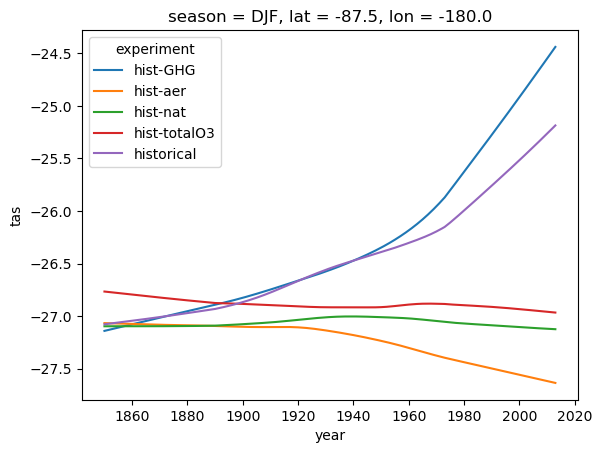

In [97]:
datatree.tree_to_dataset(forced_tree['CanESM5'], dims=['experiment']).tas.isel(lat=0, lon=0, season=0).plot(hue='experiment')

In [98]:
#(t): Every member minus its experiment's forced response: what the width test, the tails and the zonal test use
qrange_tree = lesfmip_season_tree - forced_tree

In [99]:
qrange_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (season: 4, lat: 20, lon: 144, member: 50, year: 164)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float64 756MB dask.array<chunksize=(50, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (lon: 144, lat: 20, season: 4, member: 30, year: 164)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float64 453MB dask.array<chunksize=(30, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (lon: 144, lat: 20, season: 4, year: 164, member: 50)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float64 756MB dask.array<chunksize=(50, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (season: 4, lon: 144, lat: 20, member: 10, year: 164)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * member   (member) object 80B 'r10i1p1f1' 'r1i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float64 151MB dask.array<chunksize=(10, 4, 144, 164, 4), meta=np.ndarray>
│   └── Group: /CanESM5/historical
│           Dimensions:  (lon: 144, lat: 20, season: 4, member: 65, year: 164)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, lat, lon, year, season) float64 982MB dask.array<chunksize=(65, 4, 144, 164, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (lon: 144, lat: 20, season: 4, member: 45, year: 164)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.

In [100]:
#(c): Persisted once: the width test, the tails and the zonal test all use it, and each would redo the smoothing
qrange_tree = qrange_tree.persist()
wait(qrange_tree);

Now at every grid point. Every change is measured from hist-nat over the same final years, and the bootstrap draws from hist-nat alone, so it is drawn once per model (one function mapped over the hist-nat nodes) and every experiment of that model is tested against the same trials.

In [101]:
sig.N_BOOTSTRAP_MEMBERS

10

In [102]:
#(t): The final WINDOW years of every experiment of qrange_tree
qrange_final_tree = qrange_tree.isel(year=slice(-WINDOW, None))

In [103]:
#(t): hist-nat's alone: what every change is measured from, and all the bootstrap draws from
qrange_hist_nat_final_tree = qrange_final_tree.match('*/hist-nat')

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/hist-nat
│           Dimensions:  (member: 50, lat: 20, lon: 144, year: 21, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│             * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│           Data variables:
│               tas      (member, lat, lon, year, season) float64 97MB dask.array<chunksize=(50, 4, 144, 21, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/hist-nat
│           Dimensions:  (member: 20, lat: 20, lon: 144, year: 21, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│             * member   (member) object 160B 'r10i1p1f3' 'r1i1p1f2' ... 'r9i1p1f3'
│           Data variables:
│               tas      (member, lat, lon, year, season) float64 39MB dask.array<chunksize=(20, 4, 144, 21, 4), meta=np.ndarray>
├── Group: /NorESM2-LM
│   └── Group: /NorESM2-LM/hist-nat
│           Dimensions:  (member: 23, lat: 20, lon: 144, year: 21, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, lat, lon, year, season) float64 45MB dask.array<chunksize=(23, 4, 144, 21, 4), meta=np.ndarray>
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/hist-nat
│           Dimensions:  (member: 60, lat: 20, lon: 144, year: 21, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * member   (member) object 480B 'r10i1p1f3' 'r11i1p1f3' ... 'r9i1p1f3'
│             * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, lat, lon, year, season) float64 116MB dask.array<chunksize=(60, 4, 144, 21, 4), meta=np.ndarray>
├── Group: /MIROC6
│   └── Group: /MIROC6/hist-nat
│           Dimensions:  (member: 50, lat: 20, lon: 144, year: 21, season: 4)
│           Coordinates:
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * member   (member) object 400B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│           Data variables:
│               tas      (member, lat, lon, year, season) float64 97MB dask.array<chunksize=(50, 4, 144, 21, 4), meta=np.ndarray>
└── Group: /MPI-ESM1-2-LR
    └── Group: /MPI-ESM1-2-LR/hist-nat
            Dimensions:  (member: 30, lat: 20, lon: 144, year: 21, season: 4)
            Coordinates:
              * lon      (lon) float64 1kB -180.0 -177.5 -175.

In [104]:
%%time
#(t): Q05, Q50 and Q95 of every experiment over its final years, members and years pooled (Q50 is for the tails,
#(t): section 7)
qrange_final_q_ds = datatree.reduce_to_dataset(qrange_final_tree,
                                               partial(qc.pooled_quantiles, quantiles=TAIL_QUANTILES)).compute()

CPU times: user 196 ms, sys: 68.1 ms, total: 264 ms
Wall time: 16.3 s


<xarray.Dataset> Size: 8MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144,
                 quantile: 3)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * quantile    (quantile) float64 24B 0.05 0.5 0.95
Data variables:
    tas         (lat, lon, season, quantile, model, experiment) float64 8MB -...

In [105]:
#(t): hist-nat's
qrange_hist_nat_q_da = qrange_final_q_ds[VARIABLE.name].sel(experiment='hist-nat', drop=True)

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, quantile: 3, model: 6)> Size: 2MB
-1.375 -1.944 -1.561 -1.434 -1.491 -1.419 ... 0.8521 0.8588 0.6768 0.905 0.7961
Coordinates:
  * model     (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat       (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon       (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * quantile  (quantile) float64 24B 0.05 0.5 0.95

In [106]:
#(t): every other experiment's
qrange_final_q_da = qrange_final_q_ds[VARIABLE.name].drop_sel(experiment='hist-nat')

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, quantile: 3, model: 6,
                         experiment: 4)> Size: 7MB
-1.367 -1.358 -1.396 -1.395 -2.028 -2.139 ... 1.056 0.6796 0.7036 0.6414 0.7036
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * quantile    (quantile) float64 24B 0.05 0.5 0.95

In [107]:
#(t): hist-nat's width over the final years, Q95 - Q05
hist_nat_qrange_da = qrange_hist_nat_q_da.sel(quantile=Q_HIGH, drop=True) - qrange_hist_nat_q_da.sel(quantile=Q_LOW, drop=True)

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, model: 6)> Size: 553kB
2.829 3.835 3.082 2.809 3.049 3.333 4.604 ... 1.105 1.763 1.591 1.384 1.806 1.51
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5

In [108]:
#(t): Every experiment's width over the same years
experiment_qrange_da = qrange_final_q_da.sel(quantile=Q_HIGH, drop=True) - qrange_final_q_da.sel(quantile=Q_LOW, drop=True)

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, model: 6, experiment: 4)> Size: 2MB
2.849 2.703 2.838 2.894 3.971 4.202 4.201 ... 1.98 1.995 1.399 1.399 1.336 1.452
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5

In [109]:
#(t): The change in width: the experiment's minus hist-nat's, over the same years
qrange_change_da = experiment_qrange_da - hist_nat_qrange_da

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, model: 6, experiment: 4)> Size: 2MB
0.01967 -0.1258 0.008967 0.06471 0.1361 ... -0.1115 -0.1111 -0.1742 -0.05781
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5

In [110]:
%%time
#(t): The bootstrap, from hist-nat alone: each trial's width, N_BOOTSTRAP_MEMBERS different members over the final
#(t): WINDOW years (numba, on the cluster)
qrange_trial_ds = datatree.reduce_to_dataset(
    qrange_hist_nat_final_tree,
    partial(sig.bootstrap_qrange, quantiles=QRANGE_QUANTILES, n_trials=N_TRIALS, seed=0),
)
qrange_trial_da = qrange_trial_ds[VARIABLE.name].sel(experiment='hist-nat', drop=True).persist()
wait(qrange_trial_da)

CPU times: user 54.1 ms, sys: 2.79 ms, total: 56.8 ms
Wall time: 9.15 s


<xarray.DataArray 'tas' (trial: 1000, lat: 20, lon: 144, season: 4, model: 6)> Size: 276MB
dask.array<chunksize=(1000, 4, 144, 4, 1), meta=np.ndarray>
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * trial    (trial) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999

In [111]:
%%time
#(t): The two-sided p-value: where every experiment's width falls among its model's trials
qrange_pvalue_da = sig.pvalue_two_sided(qrange_trial_da, experiment_qrange_da).compute()

CPU times: user 28 ms, sys: 3.88 ms, total: 31.9 ms
Wall time: 722 ms


<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, model: 6, experiment: 4)> Size: 2MB
0.6673 0.6513 0.7193 0.4615 0.2498 ... 0.07193 0.4456 0.4476 0.1359 0.8092
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'

In [112]:
#(t): The trials as changes: each trial's width minus hist-nat's (for the bounds, and the zonal test of section 8)
qrange_null_da = qrange_trial_da - hist_nat_qrange_da

<xarray.DataArray 'tas' (trial: 1000, lat: 20, lon: 144, season: 4, model: 6)> Size: 553MB
dask.array<chunksize=(1000, 4, 144, 4, 1), meta=np.ndarray>
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * trial    (trial) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999

In [113]:
%%time
#(t): Their central 1 - ALPHA: a change outside it is significant
null_bounds_da = nan_quantile(qrange_null_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial').compute()

CPU times: user 9.55 ms, sys: 848 μs, total: 10.4 ms
Wall time: 322 ms


<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, model: 6, quantile: 2)> Size: 1MB
-0.3474 0.2492 -0.2261 0.2453 -0.3208 ... 0.1352 -0.2323 0.2018 -0.2195 0.1459
Coordinates:
  * model     (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon       (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat       (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * quantile  (quantile) float64 16B 0.025 0.975

In [114]:
#(t): The width test in one Dataset, laid out as notebook plot_03 opens it
qrange_change_ds = xr.Dataset({
    'hist_nat_qrange': hist_nat_qrange_da,
    'experiment_qrange': experiment_qrange_da,
    'qrange_change': qrange_change_da,
    'null_lower': null_bounds_da.isel(quantile=0, drop=True),
    'null_upper': null_bounds_da.isel(quantile=1, drop=True),
    'qrange_pvalue': qrange_pvalue_da,
    'qrange_significant': qrange_pvalue_da < ALPHA,
})
qrange_change_ds

<xarray.Dataset> Size: 9MB
Dimensions:             (model: 6, season: 4, lat: 20, lon: 144, experiment: 4)
Coordinates:
  * model               (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * season              (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat                 (lat) float64 160B -87.5 -85.0 -82.5 ... -42.5 -40.0
  * lon                 (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * experiment          (experiment) object 32B 'hist-GHG' ... 'historical'
Data variables:
    hist_nat_qrange     (lat, lon, season, model) float64 553kB 2.829 ... 1.51
    experiment_qrange   (lat, lon, season, model, experiment) float64 2MB 2.8...
    qrange_change       (lat, lon, season, model, experiment) float64 2MB 0.0...
    null_lower          (lat, lon, season, model) float64 553kB -0.3474 ... -...
    null_upper          (lat, lon, season, model) float64 553kB 0.2492 ... 0....
    qrange_pvalue       (lat, lon, season, model, experiment) float64 2MB 0.6...
    qrange_significant  (lat, lon, season, model, experiment) bool 276kB Fals...

In [115]:
#(t): Saved for notebooks plot_03 to plot_06
qrange_change_path = RESULTS_DIR / 'qrange_change.zarr'
qrange_change_ds.to_zarr(qrange_change_path, mode='w')
qrange_change_path

17:39:48 INFO    extant.storage | writing Dataset (model: 6, season: 4, lat: 20, lon: 144, experiment: 4) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/qrange_change.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:39:49 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/qrange_change.zarr


PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/qrange_change.zarr')

In [116]:
#(t): The quantiles the width test is made from, laid out as notebook plot_03 opens them: hist-nat's and every
#(t): experiment's over the final WINDOW years (both of qrange_tree)
width_quantiles_ds = xr.Dataset({'hist_nat': qrange_hist_nat_q_da, 'final': qrange_final_q_da})
width_quantiles_ds

<xarray.Dataset> Size: 8MB
Dimensions:     (model: 6, season: 4, lat: 20, lon: 144, quantile: 3,
                 experiment: 4)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * quantile    (quantile) float64 24B 0.05 0.5 0.95
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
Data variables:
    hist_nat    (lat, lon, season, quantile, model) float64 2MB -1.375 ... 0....
    final       (lat, lon, season, quantile, model, experiment) float64 7MB -...

In [117]:
#(t): Saved for notebooks plot_03 to plot_06
width_quantiles_path = RESULTS_DIR / 'width_quantiles.zarr'
width_quantiles_ds.to_zarr(width_quantiles_path, mode='w')
width_quantiles_path

17:39:49 INFO    extant.storage | writing Dataset (model: 6, season: 4, lat: 20, lon: 144, quantile: 3, experiment: 4) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/width_quantiles.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:39:50 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/width_quantiles.zarr


PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/width_quantiles.zarr')

In [118]:
#(t): The result at the demonstration point (of qrange_tree, so with the forced response removed)
qrange_change_ds.sel(**DEMO_SEL, experiment=DEMO_EXPERIMENT).sel(**DEMO_LATLON)

<xarray.Dataset> Size: 145B
Dimensions:             ()
Coordinates:
    model               <U7 28B 'CanESM5'
    season              <U3 12B 'DJF'
    lat                 float64 8B -75.0
    lon                 float64 8B -180.0
    experiment          <U10 40B 'historical'
Data variables:
    hist_nat_qrange     float64 8B 5.11
    experiment_qrange   float64 8B 4.559
    qrange_change       float64 8B -0.551
    null_lower          float64 8B -0.3988
    null_upper          float64 8B 0.2531
    qrange_pvalue       float64 8B 0.007992
    qrange_significant  bool 1B True

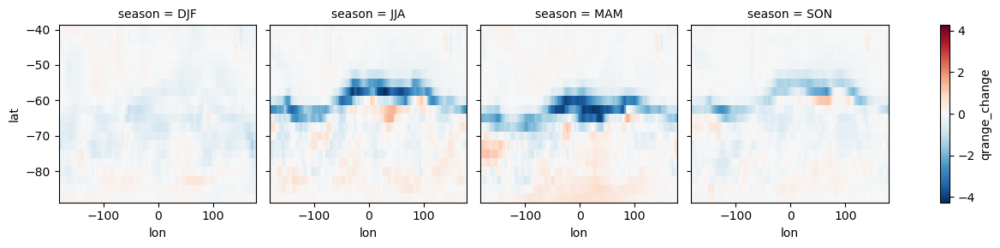

In [119]:
#(t): Quick look: the change in width for DEMO_MODEL and DEMO_EXPERIMENT, every season, on the plain lat-lon grid
qrange_change_ds['qrange_change'].sel(model=DEMO_MODEL, experiment=DEMO_EXPERIMENT).plot(
    x='lon', y='lat', col='season', cmap='RdBu_r', center=0);

### By SAM phase

The same test in the seasons of each SAM phase alone (*SAM Phases*, above): each experiment's width in a phase against hist-nat's in the same phase, and against trials of the same 10 hist-nat members, each pooling only its seasons in that phase (about 70 of its 210). Fewer seasons make every width noisier, so less comes out significant than over all seasons.

In [120]:
#(t): The internal variability over the final WINDOW years (qrange_final_tree), of the nodes with an index
qrange_sam_final_tree = qrange_final_tree.filter(lambda node: node.relative_to(qrange_final_tree) in sam_both_paths)

In [121]:
#(t): Split into the three phases: NaN outside each phase's seasons, on (phase, member, year, season, lat, lon)
qrange_phase_tree = xr.map_over_datasets(sam.by_phase, qrange_sam_final_tree, sam_final_masks_tree)

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 21, season: 4, phase: 3)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │         * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season, phase) float64 290MB dask.array<chunksize=(50, 4, 144, 21, 4, 3), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (member: 30, lat: 20, lon: 144, year: 21, season: 4, phase: 3)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │         * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season, phase) float64 174MB dask.array<chunksize=(30, 4, 144, 21, 4, 3), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 21, season: 4, phase: 3)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season, phase) float64 290MB dask.array<chunksize=(50, 4, 144, 21, 4, 3), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (member: 10, lat: 20, lon: 144, year: 21, season: 4, phase: 3)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * member   (member) object 80B 'r10i1p1f1' 'r1i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │         * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season, phase) float64 58MB dask.array<chunksize=(10, 4, 144, 21, 4, 3), meta=np.ndarray>
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 65, lat: 20, lon: 144, year: 21, season: 4, phase: 3)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│             * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'
│           Data variables:
│     

In [122]:
%%time
#(t): Q05, Q50 and Q95 in each phase, members and years pooled, every experiment (Q50 is for the tails, section 7)
phase_qrange_q_ds = datatree.reduce_to_dataset(qrange_phase_tree,
                                               partial(qc.pooled_quantiles, quantiles=TAIL_QUANTILES)).compute()

CPU times: user 179 ms, sys: 29.9 ms, total: 209 ms
Wall time: 2.11 s


<xarray.Dataset> Size: 25MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144,
                 phase: 3, quantile: 3)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
  * quantile    (quantile) float64 24B 0.05 0.5 0.95
Data variables:
    tas         (lat, lon, season, phase, quantile, model, experiment) float64 25MB ...

In [123]:
#(t): hist-nat's
phase_hist_nat_q_da = phase_qrange_q_ds[VARIABLE.name].sel(experiment='hist-nat', drop=True)

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, phase: 3, quantile: 3,
                         model: 6)> Size: 5MB
-0.9901 nan nan nan -0.6881 -1.032 0.3662 ... 0.655 nan nan nan 1.117 0.8752
Coordinates:
  * model     (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat       (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon       (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * phase     (phase) <U8 96B 'negative' 'neutral' 'positive'
  * quantile  (quantile) float64 24B 0.05 0.5 0.95

In [124]:
#(t): every other experiment's
phase_final_q_da = phase_qrange_q_ds[VARIABLE.name].drop_sel(experiment='hist-nat')

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, phase: 3, quantile: 3,
                         model: 6, experiment: 4)> Size: 20MB
-0.7238 -0.9594 -0.7382 -0.9418 nan nan ... 1.211 0.8483 0.7931 0.8401 0.7508
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
  * quantile    (quantile) float64 24B 0.05 0.5 0.95

In [125]:
#(t): hist-nat's width in each phase, Q95 - Q05
phase_hist_nat_qrange_da = phase_hist_nat_q_da.sel(quantile=Q_HIGH, drop=True) - phase_hist_nat_q_da.sel(quantile=Q_LOW, drop=True)

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, phase: 3, model: 6)> Size: 2MB
2.732 nan nan nan 2.543 3.35 2.452 nan ... 1.492 1.041 nan nan nan 1.599 1.508
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'

In [126]:
#(t): every experiment's
phase_experiment_qrange_da = phase_final_q_da.sel(quantile=Q_HIGH, drop=True) - phase_final_q_da.sel(quantile=Q_LOW, drop=True)

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, phase: 3, model: 6,
                         experiment: 4)> Size: 7MB
2.631 2.653 2.718 2.866 nan nan nan ... 1.706 1.739 1.353 1.215 1.403 1.341
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'

In [127]:
#(t): The change in width in each phase
phase_qrange_change_da = phase_experiment_qrange_da - phase_hist_nat_qrange_da

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, phase: 3, model: 6,
                         experiment: 4)> Size: 7MB
-0.1011 -0.07885 -0.01367 0.1344 nan ... 0.14 -0.1557 -0.2932 -0.1049 -0.1674
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'

In [128]:
%%time
#(t): The bootstrap in each phase: the same draws (the same seed), each trial pooling its members' seasons in the phase
phase_qrange_trial_ds = datatree.reduce_to_dataset(
    qrange_phase_tree.match('*/hist-nat'),
    partial(sig.bootstrap_qrange, quantiles=QRANGE_QUANTILES, n_trials=N_TRIALS, seed=0),
)
phase_qrange_trial_da = phase_qrange_trial_ds[VARIABLE.name].sel(experiment='hist-nat', drop=True).persist()
wait(phase_qrange_trial_da)

CPU times: user 60.3 ms, sys: 1.95 ms, total: 62.2 ms
Wall time: 2.98 s


<xarray.DataArray 'tas' (trial: 1000, lat: 20, lon: 144, season: 4, phase: 3,
                         model: 6)> Size: 829MB
dask.array<chunksize=(1000, 4, 144, 4, 3, 1), meta=np.ndarray>
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'
  * trial    (trial) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999

In [129]:
%%time
#(t): The p-value of every experiment's width in each phase against its model's trials in that phase
phase_qrange_pvalue_da = sig.pvalue_two_sided(phase_qrange_trial_da, phase_experiment_qrange_da).compute()

CPU times: user 38.8 ms, sys: 14 ms, total: 52.8 ms
Wall time: 1.67 s


<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, phase: 3, model: 6,
                         experiment: 4)> Size: 7MB
0.8871 0.8212 0.6094 0.2937 nan nan ... 0.1379 0.2458 0.001998 0.4815 0.1998
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'

In [130]:
#(t): The trials as changes: each trial's width minus hist-nat's, in each phase
phase_qrange_null_da = phase_qrange_trial_da - phase_hist_nat_qrange_da

In [131]:
%%time
#(t): Their central 1 - ALPHA
phase_null_bounds_da = nan_quantile(phase_qrange_null_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial').compute()

CPU times: user 13.5 ms, sys: 4.08 ms, total: 17.6 ms
Wall time: 2.03 s


<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, phase: 3, model: 6,
                         quantile: 2)> Size: 3MB
-0.6219 0.35 nan nan nan nan nan ... nan nan nan -0.3124 0.1948 -0.2199 0.1161
Coordinates:
  * model     (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon       (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat       (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * phase     (phase) <U8 96B 'negative' 'neutral' 'positive'
  * quantile  (quantile) float64 16B 0.025 0.975

In [132]:
#(t): The width test by SAM phase in one Dataset, laid out as qrange_change_ds with a phase dim
sam_qrange_change_ds = xr.Dataset({
    'hist_nat_qrange': phase_hist_nat_qrange_da,
    'experiment_qrange': phase_experiment_qrange_da,
    'qrange_change': phase_qrange_change_da,
    'null_lower': phase_null_bounds_da.isel(quantile=0, drop=True),
    'null_upper': phase_null_bounds_da.isel(quantile=1, drop=True),
    'qrange_pvalue': phase_qrange_pvalue_da,
    'qrange_significant': phase_qrange_pvalue_da < ALPHA,
})
sam_qrange_change_ds

<xarray.Dataset> Size: 26MB
Dimensions:             (model: 6, season: 4, lat: 20, lon: 144, phase: 3,
                         experiment: 4)
Coordinates:
  * model               (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * season              (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat                 (lat) float64 160B -87.5 -85.0 -82.5 ... -42.5 -40.0
  * lon                 (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * phase               (phase) <U8 96B 'negative' 'neutral' 'positive'
  * experiment          (experiment) object 32B 'hist-GHG' ... 'historical'
Data variables:
    hist_nat_qrange     (lat, lon, season, phase, model) float64 2MB 2.732 .....
    experiment_qrange   (lat, lon, season, phase, model, experiment) float64 7MB ...
    qrange_change       (lat, lon, season, phase, model, experiment) float64 7MB ...
    null_lower          (lat, lon, season, phase, model) float64 2MB -0.6219 ...
    null_upper          (lat, lon, season, phase, model) float64 2MB 0.35 ......
    qrange_pvalue       (lat, lon, season, phase, model, experiment) float64 7MB ...
    qrange_significant  (lat, lon, season, phase, model, experiment) bool 829kB ...

In [133]:
#(t): Saved for notebooks plot_03 to plot_06
sam_qrange_change_path = RESULTS_DIR / 'sam_qrange_change.zarr'
sam_qrange_change_ds.to_zarr(sam_qrange_change_path, mode='w')
sam_qrange_change_path

17:40:01 INFO    extant.storage | writing Dataset (model: 6, season: 4, lat: 20, lon: 144, phase: 3, experiment: 4) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_qrange_change.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:40:02 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_qrange_change.zarr


PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_qrange_change.zarr')

In [134]:
#(t): The quantiles it is made from, laid out as width_quantiles_ds with a phase dim
sam_width_quantiles_ds = xr.Dataset({'hist_nat': phase_hist_nat_q_da, 'final': phase_final_q_da})
sam_width_quantiles_ds

<xarray.Dataset> Size: 25MB
Dimensions:     (model: 6, season: 4, lat: 20, lon: 144, phase: 3, quantile: 3,
                 experiment: 4)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
  * quantile    (quantile) float64 24B 0.05 0.5 0.95
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
Data variables:
    hist_nat    (lat, lon, season, phase, quantile, model) float64 5MB -0.990...
    final       (lat, lon, season, phase, quantile, model, experiment) float64 20MB ...

In [135]:
#(t): Saved for notebooks plot_03 to plot_06
sam_width_quantiles_path = RESULTS_DIR / 'sam_width_quantiles.zarr'
sam_width_quantiles_ds.to_zarr(sam_width_quantiles_path, mode='w')
sam_width_quantiles_path

17:40:02 INFO    extant.storage | writing Dataset (model: 6, season: 4, lat: 20, lon: 144, phase: 3, quantile: 3, experiment: 4) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_width_quantiles.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `<U8` is currently not part in the Zarr format 3 specification. It may not be supported by

17:40:03 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_width_quantiles.zarr


PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_width_quantiles.zarr')

In [136]:
#(t): The result at the demonstration point, every phase
sam_qrange_change_ds.sel(**DEMO_SEL, experiment=DEMO_EXPERIMENT).sel(**DEMO_LATLON).to_dataframe().round(3)

,model,season,lat,lon,hist_nat_qrange,experiment,experiment_qrange,qrange_change,null_lower,null_upper,qrange_pvalue,qrange_significant
phase,,,,,,,,,,,,
negative,CanESM5,DJF,-75.0,-180.0,5.056,historical,4.093,-0.963,-0.809,0.496,0.024,True
neutral,CanESM5,DJF,-75.0,-180.0,5.007,historical,4.623,-0.385,-0.736,0.280,0.418,False
positive,CanESM5,DJF,-75.0,-180.0,5.228,historical,4.537,-0.691,-0.671,0.441,0.048,True


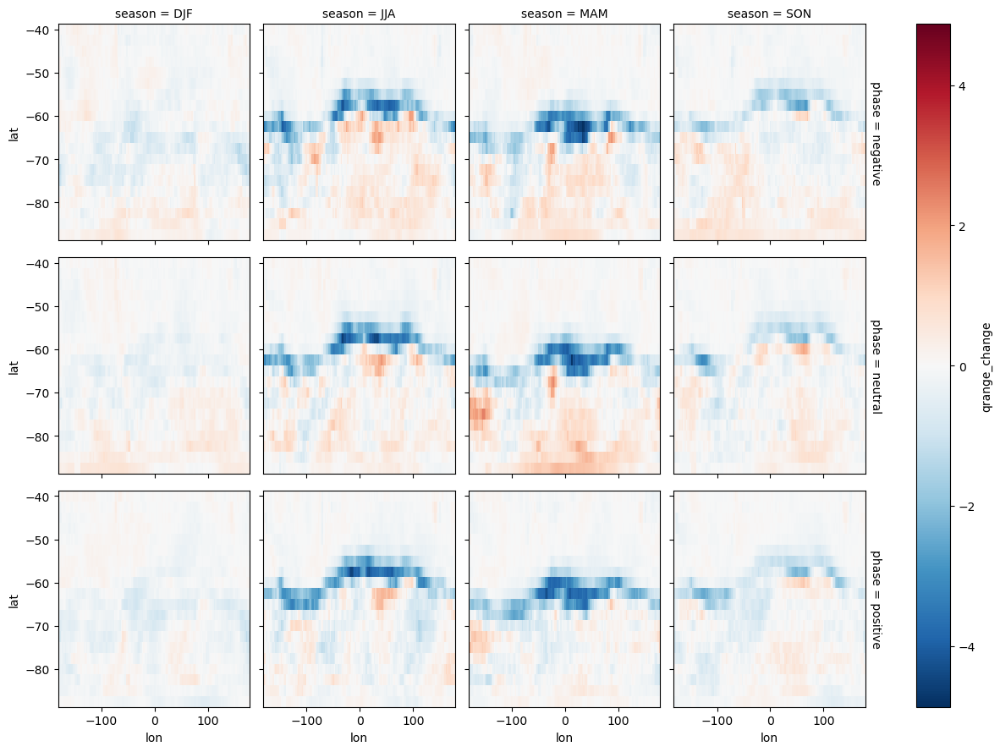

In [137]:
#(t): Quick look: DEMO_MODEL's change in width in each phase, DEMO_EXPERIMENT
sam_qrange_change_ds['qrange_change'].sel(model=DEMO_MODEL, experiment=DEMO_EXPERIMENT).plot(
    x='lon', y='lat', row='phase', col='season', cmap='RdBu_r', center=0);

## 3. Quantile Response

The change in every 5th percentile, the final $L$ years of each experiment against hist-nat's over the same years (members and years pooled), as for the mean and the width:

$$
\Delta Q_p = Q_p\left(x^{\mathrm{exp}}_{\text{final } L \text{ years}}\right) - Q_p\left(x^{\mathrm{nat}}_{\text{final } L \text{ years}}\right), \qquad p = 0.05,\ 0.10,\ \ldots,\ 0.95.
$$

The maps keep $p = 0.05,\ 0.5,\ 0.95$; the curve is every $p$ as an Antarctic (area-weighted) mean. A flat curve of $\Delta Q_p$ against $p$ is a pure shift of the distribution; a rising curve means the warm tail moves more than the cold one.

In [138]:
#(t): The quantile levels: every 5th percentile, Q05 to Q95
curve_quantiles_arr = np.round(np.arange(0.05, 1.00, 0.05), 2)

array([0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 , 0.55,
       0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95])

In [139]:
#(t): The final WINDOW years of every experiment (the seasonal means themselves, not qrange_tree)
lesfmip_final_tree = lesfmip_season_tree.isel(year=slice(-WINDOW, None))

In [140]:
%%time
#(t): Every experiment's quantiles over its final years, members and years pooled (hist-nat's too)
final_q_ds = datatree.reduce_to_dataset(lesfmip_final_tree,
                                        partial(qc.pooled_quantiles, quantiles=curve_quantiles_arr)).compute()
final_q_da = final_q_ds[VARIABLE.name].drop_sel(experiment='hist-nat')
final_q_da

CPU times: user 185 ms, sys: 56.8 ms, total: 242 ms
Wall time: 2.1 s


<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, quantile: 19, model: 6,
                         experiment: 4)> Size: 42MB
-26.2 -28.94 -28.34 -26.92 -30.93 -33.21 ... 12.41 13.08 15.06 14.51 14.4 14.93
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * quantile    (quantile) float64 152B 0.05 0.1 0.15 0.2 ... 0.8 0.85 0.9 0.95

In [141]:
#(t): hist-nat's quantiles over the same years
hist_nat_q_da = final_q_ds[VARIABLE.name].sel(experiment='hist-nat', drop=True)
hist_nat_q_da

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, quantile: 19, model: 6)> Size: 11MB
-28.49 -32.84 -30.05 -20.71 -30.58 -30.87 ... 12.92 13.49 14.98 12.22 14.62
Coordinates:
  * model     (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat       (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon       (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * quantile  (quantile) float64 152B 0.05 0.1 0.15 0.2 ... 0.8 0.85 0.9 0.95

In [142]:
#(t): The change in every quantile: final years minus hist-nat's over the same years
quantile_change_da = final_q_da - hist_nat_q_da

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, quantile: 19, model: 6,
                         experiment: 4)> Size: 42MB
2.291 -0.4499 0.1507 1.576 1.903 -0.3701 ... 0.8635 0.4323 -0.1161 -0.2198 0.307
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * quantile    (quantile) float64 152B 0.05 0.1 0.15 0.2 ... 0.8 0.85 0.9 0.95

In [143]:
#(t): The maps: Q05, Q50 and Q95
quantile_response_da = quantile_change_da.sel(quantile=[0.05, 0.50, 0.95])
quantile_response_da = quantile_response_da.rename('quantile_response')
quantile_response_da

<xarray.DataArray 'quantile_response' (lat: 20, lon: 144, season: 4,
                                       quantile: 3, model: 6, experiment: 4)> Size: 7MB
2.291 -0.4499 0.1507 1.576 1.903 -0.3701 ... 0.8635 0.4323 -0.1161 -0.2198 0.307
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * quantile    (quantile) float64 24B 0.05 0.5 0.95

In [144]:
#(t): The curve: every quantile's change as an Antarctic (area-weighted) mean
quantile_curve_da = sig.area_mean(quantile_change_da)
quantile_curve_da = quantile_curve_da.rename('quantile_curve')
quantile_curve_da

<xarray.DataArray 'quantile_curve' (season: 4, quantile: 19, model: 6,
                                    experiment: 4)> Size: 15kB
1.201 -0.3003 0.2516 0.9591 0.7101 ... 0.6549 0.3432 -0.2387 -0.06973 0.2687
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * quantile    (quantile) float64 152B 0.05 0.1 0.15 0.2 ... 0.8 0.85 0.9 0.95

In [145]:
#(t): Saved for notebooks plot_03 to plot_06
quantile_response_path = RESULTS_DIR / 'quantile_response.zarr'
quantile_response_da.to_dataset(name='quantile_response').to_zarr(quantile_response_path, mode='w')
quantile_response_path

17:40:07 INFO    extant.storage | writing DataArray (lat: 20, lon: 144, season: 4, quantile: 3, model: 6, experiment: 4) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/quantile_response.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:40:08 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/quantile_response.zarr
17:40:08 INFO    extant.storage | writing DataArray (season: 4, quantile: 19, model: 6, experiment: 4) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/quantile_curve.zarr
17:40:08 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/quantile_curve.zarr
17:40:08 INFO    extant.storage | writing DataArray (lat: 20, lon: 144, season: 4, quantile: 19, model: 6, experiment: 4) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/final_quantiles.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:40:09 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/final_quantiles.zarr
17:40:09 INFO    extant.storage | writing DataArray (lat: 20, lon: 144, season: 4, quantile: 19, model: 6) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/hist_nat_final_quantiles.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:40:10 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/hist_nat_final_quantiles.zarr


In [ ]:
#(t): Saved for notebooks plot_03 to plot_06
quantile_curve_path = RESULTS_DIR / 'quantile_curve.zarr'
quantile_curve_da.to_dataset(name='quantile_curve').to_zarr(quantile_curve_path, mode='w')
quantile_curve_path

In [ ]:
#(t): Saved for notebooks plot_03 to plot_06
final_quantiles_path = RESULTS_DIR / 'final_quantiles.zarr'
final_q_da.to_dataset(name=VARIABLE.name).to_zarr(final_quantiles_path, mode='w')
final_quantiles_path

In [ ]:
#(t): Saved for notebooks plot_03 to plot_06
hist_nat_final_quantiles_path = RESULTS_DIR / 'hist_nat_final_quantiles.zarr'
hist_nat_q_da.to_dataset(name=VARIABLE.name).to_zarr(hist_nat_final_quantiles_path, mode='w')
hist_nat_final_quantiles_path

In [146]:
#(t): The change in the three quantiles at the demonstration point, DEMO_MODEL
quantile_response_da.sel(**DEMO_SEL).sel(**DEMO_LATLON).to_pandas().round(2)

experiment,hist-GHG,hist-aer,hist-totalO3,historical
quantile,,,,
0.05,1.04,0.20,0.42,1.08
0.50,0.62,0.10,0.32,1.00
0.95,0.33,0.21,0.14,0.56


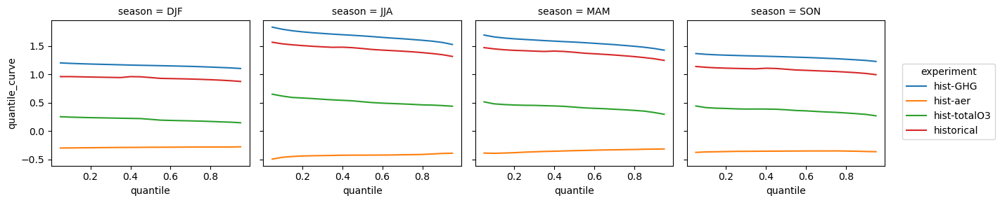

In [147]:
#(t): Quick look: DEMO_MODEL's Antarctic-mean change in every 5th percentile, one panel per season
quantile_curve_da.sel(model=DEMO_MODEL).plot.line(x='quantile', hue='experiment', col='season');

## 4. Mean Change: Four Tests

Has the mean changed by more than natural variability can give? Four tests of each experiment's final $L$ years against hist-nat:

| Test | What is compared | The null | Saved as |
|---|---|---|---|
| Welch t-test, years pooled | every member-year of the final $L$ years, against hist-nat's | Student's t | `ttest` |
| Welch t-test on the rolling medians | the last $L$ complete rolling medians of section 1, against hist-nat's | Student's t | `ttest_rolling_median` |
| Member-block permutation test | the member means of the final $L$ years, against hist-nat's | whole members relabelled | `mean_block` |
| **hist-nat bootstrap** | the final $L$ years, against 10 hist-nat members over the same years | the hist-nat bootstrap trials of section 2 | `mean_bootstrap` |

The two Welch tests count every value as independent, which they are not: a member's years are correlated, and neighbouring rolling medians share all but one of their years. So they call too much significant; they are here to compare. **The figures (notebooks plot_03 to plot_06) use the hist-nat bootstrap**, which judges the mean as section 2 judges the width, against the same trials. Each test also has a *By SAM phase* version for the bootstrap, at the end of the section.

### Welch t-test, years pooled

The final $L$ years of each experiment against hist-nat's final $L$ years, members and years pooled, with sample means $\bar{x}$, variances $s^2$ and sizes $n = ML$:

$$
t = \frac{\bar{x}_{\mathrm{exp}} - \bar{x}_{\mathrm{nat}}}{\sqrt{s^2_{\mathrm{exp}}/n_{\mathrm{exp}} + s^2_{\mathrm{nat}}/n_{\mathrm{nat}}}},
\qquad
\nu = \frac{\left(s^2_{\mathrm{exp}}/n_{\mathrm{exp}} + s^2_{\mathrm{nat}}/n_{\mathrm{nat}}\right)^2}{\dfrac{(s^2_{\mathrm{exp}}/n_{\mathrm{exp}})^2}{n_{\mathrm{exp}}-1} + \dfrac{(s^2_{\mathrm{nat}}/n_{\mathrm{nat}})^2}{n_{\mathrm{nat}}-1}},
$$

with a two-sided p-value from Student's t distribution with $\nu$ degrees of freedom. The two samples at the demonstration point are `demo_experiment_final_da` and `demo_histnat_final_da` (*A first look*):

In [148]:
#(t): The Welch t-test of the two, members and years pooled
demo_t_ds = sig.ttest_welch(demo_experiment_final_da, demo_histnat_final_da)
demo_t_ds

<xarray.Dataset> Size: 44B
Dimensions:  ()
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
Data variables:
    t        float64 8B 15.47
    p        float64 8B 2.777e-51

In [ ]:
#(t): The two samples the t-test compares: the final WINDOW years of each ensemble, members and years pooled, with
#(t): their means
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=1, n_legends=0, panel_width=6.0, panel_height=2.8),
                 layout='constrained')
axes = fig.add_gridspec(1, 1).subplots(squeeze=False)
methods.plot_two_samples(demo_experiment_final_da, demo_histnat_final_da, DEMO_EXPERIMENT, t=float(demo_t_ds.t),
                         p=float(demo_t_ds.p), ax=axes[0, 0])
axes[0, 0].set_title(f'Final {WINDOW} years, members and years pooled (lines: the means)', loc='left')
axes[0, 0].set_xlabel(VARIABLE.units)
axes[0, 0].set_ylabel('Density')
fig.suptitle(f'The two samples of the t-test: {DEMO_EXPERIMENT} and hist-nat at the point', x=0.01, ha='left');

In [151]:
#(t): Every experiment's model's hist-nat over the same final years, in a tree shaped like lesfmip_final_tree
hist_nat_final_tree = datatree.hist_nat_like(lesfmip_final_tree)

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 21, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 48MB dask.array<chunksize=(50, 4, 144, 21, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 21, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 48MB dask.array<chunksize=(50, 4, 144, 21, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 21, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 48MB dask.array<chunksize=(50, 4, 144, 21, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 21, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 48MB dask.array<chunksize=(50, 4, 144, 21, 4), meta=np.ndarray>
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 50, lat: 20, lon: 144, year: 21, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│             * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 48MB dask.array<chunksize=(50, 4, 144, 21, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (member: 20, lat: 20, lon: 144, year: 21, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │ 

In [152]:
#(t): The Welch t-test, mapped over every experiment and its model's hist-nat
ttest_tree = xr.map_over_datasets(partial(sig.ttest_welch, variable=VARIABLE.name), lesfmip_final_tree,
                                  hist_nat_final_tree)

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (season: 4, lat: 20, lon: 144)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │       Data variables:
│   │           t        (lat, lon, season) float64 92kB dask.array<chunksize=(4, 144, 4), meta=np.ndarray>
│   │           p        (lat, lon, season) float64 92kB dask.array<chunksize=(4, 144, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (lon: 144, lat: 20, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           t        (lat, lon, season) float64 92kB dask.array<chunksize=(4, 144, 4), meta=np.ndarray>
│   │           p        (lat, lon, season) float64 92kB dask.array<chunksize=(4, 144, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (lon: 144, lat: 20, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           t        (lat, lon, season) float64 92kB dask.array<chunksize=(4, 144, 4), meta=np.ndarray>
│   │           p        (lat, lon, season) float64 92kB dask.array<chunksize=(4, 144, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (season: 4, lon: 144, lat: 20)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │       Data variables:
│   │           t        (lat, lon, season) float64 92kB dask.array<chunksize=(4, 144, 4), meta=np.ndarray>
│   │           p        (lat, lon, season) float64 92kB dask.array<chunksize=(4, 144, 4), meta=np.ndarray>
│   └── Group: /CanESM5/historical
│           Dimensions:  (lon: 144, lat: 20, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│           Data variables:
│               t        (lat, lon, season) float64 92kB dask.array<chunksize=(4, 144, 4), meta=np.ndarray>
│               p        (lat, lon, season) float64 92kB dask.array<chunksize=(4, 144, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (lon: 144, lat: 20, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           t        (lat, lon, season) float64 92kB dask.array<chunksize=(4, 144, 4), meta=np.ndarray>
│   │           p        (lat, lon, season) float64 92kB dask.array<chunksize=(4, 144, 4), meta=np.ndarray>
│   ├── Group: /GISS-E2-1-G/hist-nat
│   │       Dimensions:  (lon: 144, season: 4, lat: 20)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * season   (season) object 32B 'DJ

In [153]:
%%time
#(t): No member dim left, so one Dataset (hist-nat against itself is t = 0)
ttest_ds = datatree.tree_to_dataset(ttest_tree, dims=['model', 'experiment']).compute()
ttest_ds

CPU times: user 75.3 ms, sys: 8.25 ms, total: 83.6 ms
Wall time: 2.62 s


<xarray.Dataset> Size: 6MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
Data variables:
    t           (lat, lon, season, model, experiment) float64 3MB 61.06 ... 1...
    p           (lat, lon, season, model, experiment) float64 3MB 0.0 ... 2.3...

In [154]:
#(t): Saved for notebooks plot_03 to plot_06
ttest_path = RESULTS_DIR / 'ttest.zarr'
ttest_ds.to_zarr(ttest_path, mode='w')
ttest_path

17:40:14 INFO    extant.storage | writing Dataset (model: 6, experiment: 5, season: 4, lat: 20, lon: 144) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/ttest.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(


17:40:15 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/ttest.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/api/asynchronous.py:227: UserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be suppo

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/ttest.zarr')

In [155]:
#(t): Its value at the demonstration point: the same t as above
ttest_ds.sel(**DEMO_SEL, experiment=DEMO_EXPERIMENT).sel(**DEMO_LATLON)

<xarray.Dataset> Size: 112B
Dimensions:     ()
Coordinates:
    model       <U7 28B 'CanESM5'
    experiment  <U10 40B 'historical'
    season      <U3 12B 'DJF'
    lat         float64 8B -75.0
    lon         float64 8B -180.0
Data variables:
    t           float64 8B 15.47
    p           float64 8B 2.776e-51

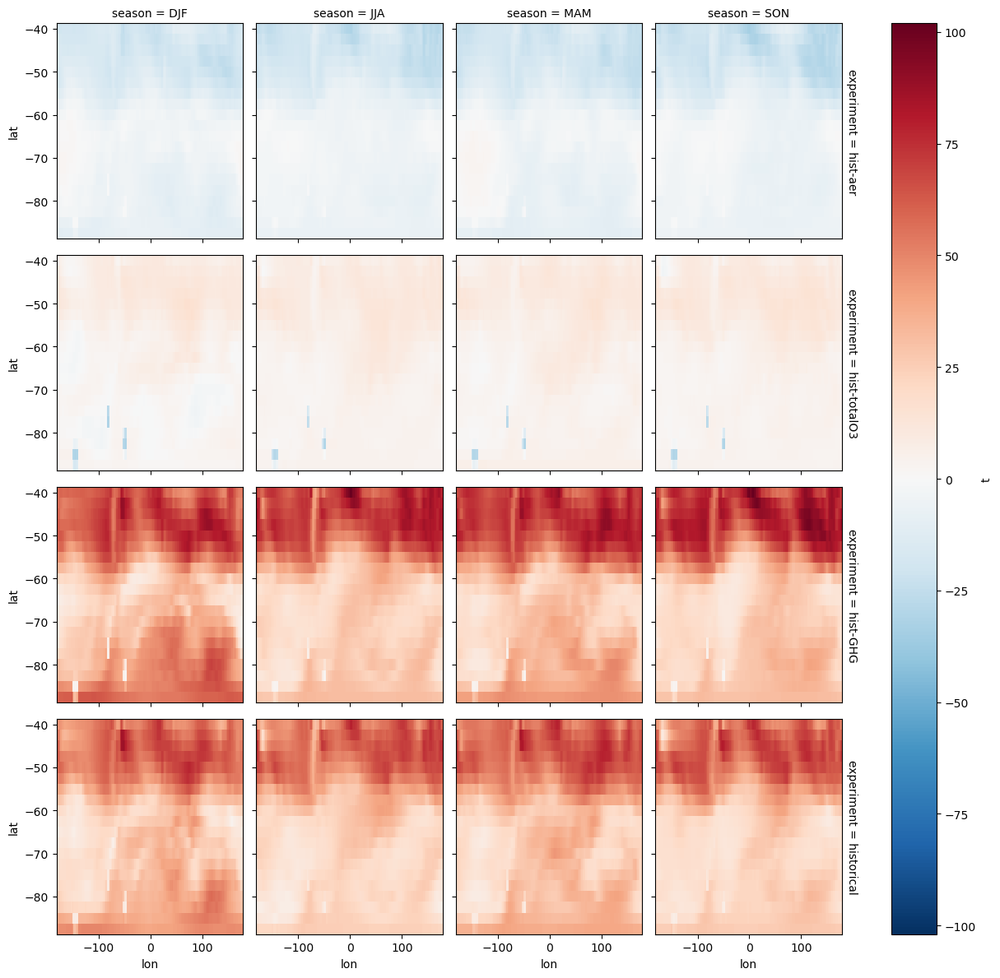

In [156]:
#(t): Quick look: t for DEMO_MODEL, experiments down and seasons across, on the plain lat-lon grid
ttest_ds['t'].sel(model=DEMO_MODEL, experiment=config.FORCED_EXPERIMENTS).plot(
    x='lon', y='lat', row='experiment', col='season', cmap='RdBu_r', center=0);

### Welch t-test on the rolling medians

The same test on section 1's rolling medians $Q_{50}(t)$, each of which pools every member's values in the $L$ years centred on $t$. It takes the last $L$ years that have a complete window (centres 1983–2003, whose windows cover 1973–2013): $L$ values for the experiment and $L$ for hist-nat, and $\nu$ comes from those. Neighbouring medians share $L - 1$ of their $L$ years, so the values are far from independent and the test is overconfident: it is here to see by how much.

In [157]:
#(t): The last WINDOW years with a complete window: up to LAST_FULL_YEAR, the centre of the final WINDOW years
ROLLING_FINAL_YEARS = slice(config.LAST_FULL_YEAR - WINDOW + 1, config.LAST_FULL_YEAR + 1)

slice(-31, -10, None)

In [158]:
#(t): The rolling medians at the demonstration point, every experiment, on (experiment, year): from section 1's
#(t): point_rolling_da
demo_rolling_median_da = point_rolling_da.sel(quantile=0.5, drop=True)

<xarray.DataArray 'tas' (year: 164, experiment: 5)> Size: 7kB
dask.array<chunksize=(164, 1), meta=np.ndarray>
Coordinates:
    model       <U7 28B 'CanESM5'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
    season      <U3 12B 'DJF'
    lat         float64 8B -75.0
    lon         float64 8B -180.0
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013

In [159]:
#(t): Over those years
demo_rolling_median_final_da = demo_rolling_median_da.isel(year=ROLLING_FINAL_YEARS)

<xarray.DataArray 'tas' (year: 21, experiment: 5)> Size: 840B
dask.array<chunksize=(21, 1), meta=np.ndarray>
Coordinates:
    model       <U7 28B 'CanESM5'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
    season      <U3 12B 'DJF'
    lat         float64 8B -75.0
    lon         float64 8B -180.0
  * year        (year) int64 168B 1983 1984 1985 1986 ... 2000 2001 2002 2003

In [160]:
#(t): DEMO_EXPERIMENT's, and hist-nat's
demo_experiment_rolling_median_da = demo_rolling_median_final_da.sel(experiment=DEMO_EXPERIMENT)
demo_histnat_rolling_median_da = demo_rolling_median_final_da.sel(experiment='hist-nat')

In [161]:
#(t): The Welch t-test of the two, over the years alone
demo_t_rolling_median_ds = sig.ttest_welch(demo_experiment_rolling_median_da, demo_histnat_rolling_median_da,
                                           dims=('year',))
demo_t_rolling_median_ds

<xarray.Dataset> Size: 72B
Dimensions:  ()
Coordinates:
    model    <U7 28B 'CanESM5'
    season   <U3 12B 'DJF'
    lat      float64 8B -75.0
    lon      float64 8B -180.0
Data variables:
    t        float64 8B dask.array<chunksize=(), meta=np.ndarray>
    p        float64 8B dask.array<chunksize=(), meta=np.ndarray>

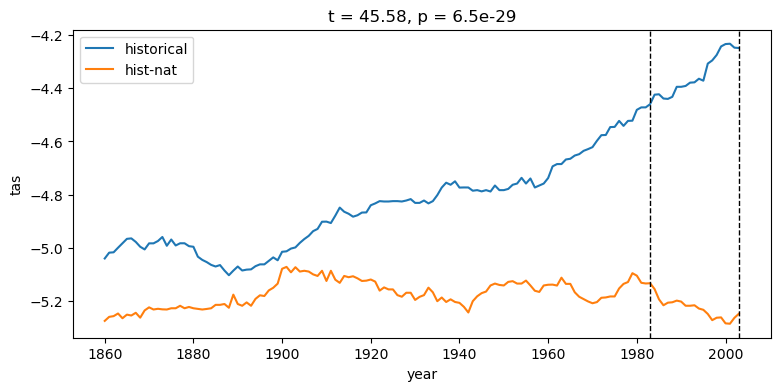

In [162]:
#(t): Quick look: the two rolling medians through time; the years tested are between the dashed lines
fig, ax = plt.subplots(figsize=(9, 4))
demo_rolling_median_da.sel(experiment=DEMO_EXPERIMENT).plot(ax=ax, label=DEMO_EXPERIMENT)
demo_rolling_median_da.sel(experiment='hist-nat').plot(ax=ax, label='hist-nat')
ax.axvline(int(demo_rolling_median_final_da.year[0]), color='k', ls='--', lw=1)
ax.axvline(int(demo_rolling_median_final_da.year[-1]), color='k', ls='--', lw=1)
ax.set_title(f"t = {float(demo_t_rolling_median_ds['t']):.2f}, p = {float(demo_t_rolling_median_ds['p']):.3g}")
ax.legend();

Now everywhere, from section 1's `rolling_quantiles_ds`.

In [163]:
#(t): The rolling medians of every model and experiment (section 1)
rolling_median_da = rolling_quantiles_ds[VARIABLE.name].sel(quantile=0.5, drop=True)

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, year: 164, model: 6,
                         experiment: 5)> Size: 453MB
dask.array<chunksize=(4, 144, 4, 164, 1, 1), meta=np.ndarray>
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013

In [164]:
#(t): Over the last WINDOW years with a complete window
rolling_median_final_da = rolling_median_da.isel(year=ROLLING_FINAL_YEARS)

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, year: 21, model: 6,
                         experiment: 5)> Size: 58MB
dask.array<chunksize=(4, 144, 4, 21, 1, 1), meta=np.ndarray>
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 168B 1983 1984 1985 1986 ... 2000 2001 2002 2003

In [165]:
#(t): hist-nat's, and every other experiment's
hist_nat_rolling_median_da = rolling_median_final_da.sel(experiment='hist-nat', drop=True)
experiment_rolling_median_da = rolling_median_final_da.drop_sel(experiment='hist-nat')

In [166]:
%%time
#(t): The Welch t-test over the years alone, every experiment against its model's hist-nat
ttest_rolling_median_ds = sig.ttest_welch(experiment_rolling_median_da, hist_nat_rolling_median_da,
                                          dims=('year',)).compute()
ttest_rolling_median_ds

CPU times: user 39.2 ms, sys: 6.79 ms, total: 46 ms
Wall time: 472 ms


<xarray.Dataset> Size: 4MB
Dimensions:     (model: 6, experiment: 4, season: 4, lat: 20, lon: 144)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
Data variables:
    t           (lat, lon, season, model, experiment) float64 2MB 33.32 ... 7...
    p           (lat, lon, season, model, experiment) float64 2MB 4.229e-19 ....

In [167]:
#(t): Saved for notebooks plot_03 to plot_06
ttest_rolling_median_path = RESULTS_DIR / 'ttest_rolling_median.zarr'
ttest_rolling_median_ds.to_zarr(ttest_rolling_median_path, mode='w')
ttest_rolling_median_path

17:40:17 INFO    extant.storage | writing Dataset (model: 6, experiment: 4, season: 4, lat: 20, lon: 144) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/ttest_rolling_median.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(


17:40:18 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/ttest_rolling_median.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/api/asynchronous.py:227: UserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be suppo

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/ttest_rolling_median.zarr')

In [168]:
#(t): Its value at the demonstration point: the same t as above
ttest_rolling_median_ds.sel(**DEMO_SEL, experiment=DEMO_EXPERIMENT).sel(**DEMO_LATLON)

<xarray.Dataset> Size: 112B
Dimensions:     ()
Coordinates:
    model       <U7 28B 'CanESM5'
    experiment  <U10 40B 'historical'
    season      <U3 12B 'DJF'
    lat         float64 8B -75.0
    lon         float64 8B -180.0
Data variables:
    t           float64 8B 45.58
    p           float64 8B 6.504e-29

### Member-block permutation test

The Welch t-test above pools `WINDOW` years × N members as if every value were independent. But a member's years are serially correlated, so the pooled test is overconfident: in synthetic data with a lag-1 autocorrelation of 0.6, it rejects a true null 29% of the time at p < 0.05, against 5% for this test. (Antarctic seasonal means are usually less correlated than that, so the effect here is smaller, but it is there.)

Members, however, are independent realisations. So this test permutes **whole members** between the experiment and hist-nat, keeping each member's years together as a block. Because every member covers the same years, permuting whole members is the same as permuting member means, so the test runs as one matrix product per batch of permutations.

The test statistic is the difference in means, $\Delta = \bar{x}_{\mathrm{exp}} - \bar{x}_{\mathrm{nat}}$. Each permutation relabels $M_{\mathrm{exp}}$ of the pooled members as the experiment and the other $M_{\mathrm{nat}}$ as hist-nat, keeping each member's years together, and computes the same $\Delta$; the p-value counts the permutations at least as extreme, as for the bootstrap. Step by step, at the demonstration point:

In [169]:
#(t): Each member's mean over the final WINDOW years at the point: the experiment's
demo_experiment_member_mean_da = demo_experiment_final_da.mean('year')

<xarray.DataArray 'tas' (member: 65)> Size: 260B
-4.099 -3.849 -4.19 -3.539 -3.974 -4.072 ... -3.56 -3.727 -4.345 -4.096 -4.039
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'

In [170]:
#(t): and hist-nat's
demo_histnat_member_mean_da = demo_histnat_final_da.mean('year')

<xarray.DataArray 'tas' (member: 50)> Size: 200B
-4.406 -4.742 -5.144 -4.718 -4.592 -4.401 ... -5.213 -4.99 -4.652 -4.913 -5.253
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'

In [171]:
#(t): The observed difference in means
demo_mean_change_da = demo_experiment_member_mean_da.mean('member') - demo_histnat_member_mean_da.mean('member')

<xarray.DataArray 'tas' ()> Size: 4B
0.9505
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

In [172]:
#(t): The relabellings: each row has +1/M_exp on the members it calls the experiment and -1/M_nat on the rest
#(c): The same draws as the full test below: rc.member_block_pvalue draws from default_rng(0) too
demo_n_exp = demo_experiment_member_mean_da.sizes['member']
demo_n_nat = demo_histnat_member_mean_da.sizes['member']
demo_weights_arr = rc.permutation_weights(N_PERMUTATIONS, demo_n_exp, demo_n_nat, np.random.default_rng(0))
demo_weights_arr.shape

(5000, 115)

In [173]:
#(t): The pooled member means, the experiment's first
demo_pooled_arr = np.concatenate([demo_experiment_member_mean_da.values, demo_histnat_member_mean_da.values])

array([-4.098667 , -3.848673 , -4.190141 , -3.5388649, -3.974269 ,
       -4.0722985, -3.8591447, -4.107021 , -4.2539268, -4.0054984,
       -4.221137 , -3.5707986, -3.5410542, -3.738819 , -3.9299865,
       -3.2755718, -3.6963584, -4.314213 , -4.3552356, -4.404978 ,
       -4.1901827, -4.121517 , -4.196407 , -4.4167314, -4.5026255,
       -4.251916 , -4.1210456, -4.297178 , -4.546543 , -4.2895303,
       -3.7215123, -4.1842375, -3.3958519, -4.3438416, -4.3188195,
       -4.293985 , -4.042475 , -4.7635455, -4.016822 , -4.6596036,
       -3.5640926, -4.4172463, -4.3412147, -3.9404554, -3.6991162,
       -4.0804167, -3.674352 , -3.8539457, -3.9076967, -4.406562 ,
       -4.6009984, -3.6874154, -4.426136 , -4.367814 , -4.0069084,
       -3.9231324, -4.0861297, -4.0166664, -4.3757977, -3.7968667,
       -3.5595317, -3.7271264, -4.344546 , -4.0962973, -4.03916  ,
       -4.4059176, -4.741545 , -5.143931 , -4.7177715, -4.5922937,
       -4.4007287, -5.389773 , -5.299661 , -4.769404 , -5.0648

In [174]:
#(t): Each relabelling's difference in means: the null
demo_permutations_da = xr.DataArray(demo_weights_arr @ demo_pooled_arr, dims='trial')

<xarray.DataArray (trial: 5000)> Size: 40kB
0.2014 -0.07513 -0.1623 -0.0436 0.01312 ... -0.09168 0.00195 0.05814 0.1163
Dimensions without coordinates: trial

In [175]:
#(t): The p-value: where the observed difference falls among the relabellings'
demo_mean_pvalue_da = sig.pvalue_two_sided(demo_permutations_da, demo_mean_change_da)
demo_mean_pvalue_da

<xarray.DataArray ()> Size: 8B
0.0003999
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

In [ ]:
#(t): The member-block permutation test of the mean change, step by step: a) the two ensembles' final years and their
#(t): means; b) example relabellings, whole members shuffled between the labels; c) every relabelling's difference in
#(t): means, and the observed one. The relabellings in b are rebuilt and checked against demo_permutations_da
n_experiment_members = demo_experiment_final_da.sizes['member']
n_histnat_members = demo_histnat_final_da.sizes['member']
n_final_years = demo_experiment_final_da.sizes['year']
n_permutations = demo_permutations_da.sizes['trial']
#(c): In the slides' big text, as the schematics are shown in talks too
with plt.rc_context(fr.SLIDES.rc):
    fig = plt.figure(figsize=(11, 15))
    ax_a, flow_axes, trial_axes, ax_c = methods.schematic_axes(fig)

    methods.plot_two_ensembles(demo_histnat_final_da, demo_experiment_final_da, DEMO_EXPERIMENT, units=VARIABLE.units,
                               ax=ax_a)
    ax_a.set_title(f'a  The final {n_final_years} years of each ensemble', pad=10)
    ax_a.set_xlabel(VARIABLE.units)
    ax_a.set_ylabel('Density')

    methods.plot_flow(f'Pool all {n_experiment_members + n_histnat_members} members, each keeping its {n_final_years} '
                      f'years together,\nthen randomly relabel {n_experiment_members} of them {DEMO_EXPERIMENT} and '
                      f'{n_histnat_members} hist-nat', flow_axes[0])
    methods.plot_relabellings(demo_experiment_final_da, demo_histnat_final_da, demo_weights_arr > 0, demo_permutations_da,
                              DEMO_EXPERIMENT, trial_axes)
    trial_axes[0, 0].set_title('b  Example relabellings', loc='left', pad=10)
    methods.plot_flow(f'Repeat {n_permutations:,} times and calculate $\\Delta$ for each relabelling,\n'
                      'then compare the observed $\\Delta$ with the permutation distribution', flow_axes[1])

    methods.plot_permutation_distribution(demo_permutations_da, demo_mean_change_da, DEMO_EXPERIMENT, ax=ax_c)
    ax_c.set_title(f'c  Permutation distribution\n$p$ = {float(demo_mean_pvalue_da):.3f}', pad=8)
    ax_c.set_xlabel(f'Difference in means ({VARIABLE.units})')
    ax_c.set_ylabel('Density');

In [178]:
#(t): Each member's mean over the final WINDOW years, everywhere
member_mean_tree = lesfmip_final_tree.mean('year')

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, season) float32 2MB dask.array<chunksize=(50, 4, 144, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (member: 30, lat: 20, lon: 144, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, season) float32 1MB dask.array<chunksize=(30, 4, 144, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, season) float32 2MB dask.array<chunksize=(50, 4, 144, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (member: 10, lat: 20, lon: 144, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * member   (member) object 80B 'r10i1p1f1' 'r1i1p1f1' ... 'r9i1p1f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, season) float32 461kB dask.array<chunksize=(10, 4, 144, 4), meta=np.ndarray>
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 65, lat: 20, lon: 144, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│           Data variables:
│               tas      (member, lat, lon, season) float32 3MB dask.array<chunksize=(65, 4, 144, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (member: 45, lat: 20, lon: 144, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 360B 'r10i1p1f2' 'r10i1p3f1' ... 'r9i1p3f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, season) float32 2MB dask.array<chunksize=(45, 4, 144, 4), meta=np.ndarray>
│   ├── Group: /GISS-E2-1-G/hist-nat
│   │       Dimensions:  (member: 20, lat: 20, lon: 144, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * season   (season) ob

In [179]:
#(t): Its model's hist-nat member means alongside every experiment
hist_nat_member_mean_tree = datatree.hist_nat_like(member_mean_tree)

In [180]:
#(t): The member-block test, mapped over every experiment and its model's hist-nat
mean_block_pvalue_tree = xr.map_over_datasets(partial(rc.member_block_pvalue, n_permutations=N_PERMUTATIONS),
                                              member_mean_tree, hist_nat_member_mean_tree)

In [181]:
%%time
#(t): Its p-values in one Dataset (hist-nat against itself left out)
mean_block_pvalue_ds = datatree.tree_to_dataset(mean_block_pvalue_tree, dims=['model', 'experiment']).compute()
mean_block_pvalue_da = mean_block_pvalue_ds[VARIABLE.name].drop_sel(experiment='hist-nat')

CPU times: user 45.9 ms, sys: 6.04 ms, total: 52 ms
Wall time: 2.27 s


<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, model: 6, experiment: 4)> Size: 2MB
0.0003999 0.0003999 0.04039 0.0003999 ... 0.0003999 0.4135 0.04279 0.0003999
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5

In [182]:
%%time
#(t): Every experiment's ensemble mean over its final years
final_mean_tree = member_mean_tree.mean('member')
final_mean_ds = datatree.tree_to_dataset(final_mean_tree, dims=['model', 'experiment']).compute()
final_mean_ds

CPU times: user 80.4 ms, sys: 4.89 ms, total: 85.3 ms
Wall time: 438 ms


<xarray.Dataset> Size: 1MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
Data variables:
    tas         (lat, lon, season, model, experiment) float32 1MB -24.78 ... ...

In [183]:
#(t): The mean response: each experiment minus hist-nat over the same final years, members pooled
mean_response_ds = final_mean_ds - final_mean_ds.sel(experiment='hist-nat')
mean_response_ds = mean_response_ds.drop_sel(experiment='hist-nat')
mean_response_da = mean_response_ds[VARIABLE.name].rename('mean_response')

<xarray.DataArray 'mean_response' (lat: 20, lon: 144, season: 4, model: 6,
                                   experiment: 4)> Size: 1MB
2.339 -0.4519 0.1746 1.726 1.955 ... 0.7147 0.5428 -0.02937 -0.08779 0.3585
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5

In [184]:
#(t): The member-block test in one Dataset, laid out as notebook plot_03 opens it
mean_block_ds = xr.Dataset({'mean_change': mean_response_da, 'pvalue': mean_block_pvalue_da})
mean_block_ds

<xarray.Dataset> Size: 3MB
Dimensions:      (model: 6, experiment: 4, season: 4, lat: 20, lon: 144)
Coordinates:
  * model        (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment   (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season       (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat          (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
  * lon          (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
Data variables:
    mean_change  (lat, lon, season, model, experiment) float32 1MB 2.339 ... ...
    pvalue       (lat, lon, season, model, experiment) float64 2MB 0.0003999 ...

In [185]:
#(t): Saved for notebooks plot_03 to plot_06
final_mean_path = RESULTS_DIR / 'final_mean.zarr'
final_mean_ds.to_zarr(final_mean_path, mode='w')
final_mean_path

17:40:23 INFO    extant.storage | writing Dataset (model: 6, experiment: 5, season: 4, lat: 20, lon: 144) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/final_mean.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:40:23 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/final_mean.zarr
17:40:23 INFO    extant.storage | writing Dataset (model: 6, experiment: 4, season: 4, lat: 20, lon: 144) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/mean_block.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:40:24 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/mean_block.zarr


In [ ]:
#(t): Saved for notebooks plot_03 to plot_06
mean_block_path = RESULTS_DIR / 'mean_block.zarr'
mean_block_ds.to_zarr(mean_block_path, mode='w')
mean_block_path

In [186]:
#(t): Its value at the demonstration point: the same change and p-value as the step-by-step test above
mean_block_ds.sel(**DEMO_SEL, experiment=DEMO_EXPERIMENT).sel(**DEMO_LATLON)

<xarray.Dataset> Size: 108B
Dimensions:      ()
Coordinates:
    model        <U7 28B 'CanESM5'
    experiment   <U10 40B 'historical'
    season       <U3 12B 'DJF'
    lat          float64 8B -75.0
    lon          float64 8B -180.0
Data variables:
    mean_change  float32 4B 0.9505
    pvalue       float64 8B 0.0003999

### hist-nat bootstrap of the mean (the figures' test)

The width test of section 2, with the mean in place of the width. **The change** is each experiment's mean over the final $L$ years minus hist-nat's over the same years, members and years pooled, the same change as the member-block test's:

$$
\Delta\bar{x} = \bar{x}^{\,\mathrm{exp}}_{\text{final } L \text{ years}} - \bar{x}^{\,\mathrm{nat}}_{\text{final } L \text{ years}}.
$$

**Its null** comes from the trials of section 2, the very same draws: trial $k$ pools the values of 10 different hist-nat members over the final $L$ years and takes their mean,

$$
\bar{x}_k = \frac{1}{nL} \sum_{m \in S_k} \sum_{y} x^{\mathrm{nat}}_{m,y}, \qquad k = 1, \ldots, N,
$$

and the p-value counts the trials at least as far out as the experiment's mean $\bar{x}^{\,\mathrm{exp}}$, on either side, as for the width. The trials are whole members, so the correlation between a member's years, which makes the pooled Welch test overconfident, is in them too. How well the test holds for each ensemble size is in section 2.

Step by step at the demonstration point, with the draws of section 2 (`demo_selected_arr`):

In [187]:
#(t): hist-nat's mean over the final WINDOW years at the point, members and years pooled
demo_hist_nat_mean_da = demo_histnat_final_da.mean(['member', 'year'])

<xarray.DataArray 'tas' ()> Size: 4B
-5.021
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

In [188]:
#(t): The experiment's over the same years
demo_experiment_mean_da = demo_experiment_final_da.mean(['member', 'year'])

<xarray.DataArray 'tas' ()> Size: 4B
-4.071
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

In [189]:
#(t): The change being tested
demo_bootstrap_change_da = demo_experiment_mean_da - demo_hist_nat_mean_da
demo_bootstrap_change_da

<xarray.DataArray 'tas' ()> Size: 4B
0.9505
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

In [190]:
%%time
#(t): Each trial's mean, from the same draws as the width test (the same seed), on (trial)
demo_trial_mean_da = sig.bootstrap_mean(demo_histnat_final_da, n_trials=DEMO_TRIALS, seed=0)

CPU times: user 2.14 s, sys: 0 ns, total: 2.14 s
Wall time: 81.5 ms


<xarray.DataArray 'tas' (trial: 10000)> Size: 80kB
-5.074 -4.773 -5.022 -5.067 -5.035 -5.158 ... -5.3 -4.999 -4.948 -5.163 -5.087
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * trial    (trial) int64 80kB 0 1 2 3 4 5 6 ... 9994 9995 9996 9997 9998 9999

In [191]:
#(t): The p-value: where the experiment's mean falls among the trials'
demo_bootstrap_pvalue_da = sig.pvalue_two_sided(demo_trial_mean_da, demo_experiment_mean_da)
demo_bootstrap_pvalue_da

<xarray.DataArray 'tas' ()> Size: 8B
0.0002
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

In [ ]:
#(t): The hist-nat bootstrap of the mean, step by step, on the width test's draws: a) the two ensembles over the same
#(t): final years, with their means; b) example trials, each N hist-nat members over those years; c) every trial's
#(t): mean, and the experiment's. The trials in b are rebuilt from demo_selected_arr and checked against
#(t): demo_trial_mean_da
n_histnat_members = demo_histnat_final_da.sizes['member']
n_drawn = int(demo_selected_arr[0].sum())
n_final_years = demo_histnat_final_da.sizes['year']
n_trials = demo_trial_mean_da.sizes['trial']
#(c): In the slides' big text, as the schematics are shown in talks too
with plt.rc_context(fr.SLIDES.rc):
    fig = plt.figure(figsize=(11, 15))
    ax_a, flow_axes, trial_axes, ax_c = methods.schematic_axes(fig)

    methods.plot_two_ensembles(demo_histnat_final_da, demo_experiment_final_da, DEMO_EXPERIMENT, units=VARIABLE.units,
                               ax=ax_a)
    ax_a.set_title(f'a  The final {n_final_years} years of each ensemble', pad=10)
    ax_a.set_xlabel(VARIABLE.units)
    ax_a.set_ylabel('Density')

    methods.plot_flow(f'Draw {n_drawn} of the {n_histnat_members} hist-nat members, keep the same {n_final_years} years,\n'
                      f'pool their {n_drawn * n_final_years} values and take their mean', flow_axes[0])
    methods.plot_mean_trials(demo_histnat_final_da, demo_selected_arr, demo_trial_mean_da, trial_axes)
    trial_axes[0, 0].set_title('b  Example trials', loc='left', pad=10)
    methods.plot_flow(f'Repeat {n_trials:,} times: the means {n_drawn} hist-nat members give on their own.\n'
                      f"Then where does {DEMO_EXPERIMENT}'s mean fall among them?", flow_axes[1])

    methods.plot_trial_distribution(demo_trial_mean_da, demo_experiment_mean_da, demo_hist_nat_mean_da, DEMO_EXPERIMENT,
                                    n_histnat_members, ax=ax_c)
    ax_c.set_title(f'c  Bootstrap distribution\n$p$ = {float(demo_bootstrap_pvalue_da):.3f}', pad=8)
    ax_c.set_xlabel(f'Mean ({VARIABLE.units})')
    ax_c.set_ylabel('Density');

Now at every grid point. As for the width, the trials come from hist-nat alone, so they are drawn once per model (one function mapped over the hist-nat nodes), and every experiment of that model is tested against the same trials.

In [194]:
#(t): hist-nat's mean over the final WINDOW years, from final_mean_ds (above)
hist_nat_mean_da = final_mean_ds[VARIABLE.name].sel(experiment='hist-nat', drop=True)

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, model: 6)> Size: 276kB
-27.12 -30.91 -28.52 -19.28 -29.08 -29.36 ... 13.22 12.03 12.65 14.3 11.32 13.83
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5

In [195]:
#(t): every other experiment's
experiment_mean_da = final_mean_ds[VARIABLE.name].drop_sel(experiment='hist-nat')

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, model: 6, experiment: 4)> Size: 1MB
-24.78 -27.57 -26.95 -25.39 -28.96 -31.07 ... 11.43 12.04 14.38 13.8 13.75 14.19
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5

In [196]:
#(t): The change being tested (the same numbers as mean_response_da)
mean_bootstrap_change_da = experiment_mean_da - hist_nat_mean_da

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, model: 6, experiment: 4)> Size: 1MB
2.339 -0.4519 0.1746 1.726 1.955 ... 0.7147 0.5428 -0.02937 -0.08779 0.3585
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5

In [197]:
%%time
#(t): Each trial's mean, from hist-nat's final WINDOW years alone: the draws of the width test (section 2), the same seed
trial_mean_ds = datatree.reduce_to_dataset(
    lesfmip_final_tree.match('*/hist-nat'), partial(sig.bootstrap_mean, n_trials=N_TRIALS, seed=0),
)
trial_mean_da = trial_mean_ds[VARIABLE.name].sel(experiment='hist-nat', drop=True).persist()
wait(trial_mean_da)

CPU times: user 111 ms, sys: 3.92 ms, total: 115 ms
Wall time: 500 ms


<xarray.DataArray 'tas' (trial: 1000, lat: 20, lon: 144, season: 4, model: 6)> Size: 553MB
dask.array<chunksize=(1000, 4, 144, 4, 1), meta=np.ndarray>
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * trial    (trial) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999

In [198]:
%%time
#(t): The two-sided p-value of every experiment's mean against its model's trials
mean_bootstrap_pvalue_da = sig.pvalue_two_sided(trial_mean_da, experiment_mean_da).compute()

CPU times: user 23.9 ms, sys: 7.13 ms, total: 31.1 ms
Wall time: 575 ms


<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, model: 6, experiment: 4)> Size: 2MB
0.001998 0.001998 0.01199 0.001998 ... 0.001998 0.3956 0.007992 0.001998
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'

In [199]:
#(t): The trials as changes: each trial's mean minus hist-nat's (for the bounds, and the zonal test of section 8)
null_mean_da = trial_mean_da - hist_nat_mean_da

<xarray.DataArray 'tas' (trial: 1000, lat: 20, lon: 144, season: 4, model: 6)> Size: 553MB
dask.array<chunksize=(1000, 4, 144, 4, 1), meta=np.ndarray>
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * trial    (trial) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999

In [200]:
%%time
#(t): Their central 1 - ALPHA: a change outside it is significant
null_mean_bounds_da = nan_quantile(null_mean_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial').compute()

CPU times: user 7.23 ms, sys: 2.75 ms, total: 9.98 ms
Wall time: 309 ms


<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, model: 6, quantile: 2)> Size: 1MB
-0.142 0.1417 -0.1107 0.1129 -0.1574 ... -0.06331 0.06275 -0.06187 0.06617
Coordinates:
  * model     (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon       (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat       (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * quantile  (quantile) float64 16B 0.025 0.975

In [201]:
#(t): The hist-nat bootstrap of the mean in one Dataset, laid out as notebooks plot_03 to plot_06 open it (mean_change and pvalue
#(t): as in mean_block)
mean_bootstrap_ds = xr.Dataset({
    'hist_nat_mean': hist_nat_mean_da,
    'experiment_mean': experiment_mean_da,
    'mean_change': mean_bootstrap_change_da,
    'null_lower': null_mean_bounds_da.isel(quantile=0, drop=True),
    'null_upper': null_mean_bounds_da.isel(quantile=1, drop=True),
    'pvalue': mean_bootstrap_pvalue_da,
})
mean_bootstrap_ds

<xarray.Dataset> Size: 6MB
Dimensions:          (model: 6, season: 4, lat: 20, lon: 144, experiment: 4)
Coordinates:
  * model            (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * season           (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat              (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
  * lon              (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * experiment       (experiment) object 32B 'hist-GHG' ... 'historical'
Data variables:
    hist_nat_mean    (lat, lon, season, model) float32 276kB -27.12 ... 13.83
    experiment_mean  (lat, lon, season, model, experiment) float32 1MB -24.78...
    mean_change      (lat, lon, season, model, experiment) float32 1MB 2.339 ...
    null_lower       (lat, lon, season, model) float64 553kB -0.142 ... -0.06187
    null_upper       (lat, lon, season, model) float64 553kB 0.1417 ... 0.06617
    pvalue           (lat, lon, season, model, experiment) float64 2MB 0.0019...

In [202]:
#(t): Saved for notebooks plot_03 to plot_06
mean_bootstrap_path = RESULTS_DIR / 'mean_bootstrap.zarr'
mean_bootstrap_ds.to_zarr(mean_bootstrap_path, mode='w')
mean_bootstrap_path

17:40:27 INFO    extant.storage | writing Dataset (model: 6, season: 4, lat: 20, lon: 144, experiment: 4) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/mean_bootstrap.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:40:28 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/mean_bootstrap.zarr


PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/mean_bootstrap.zarr')

In [203]:
#(t): Its value at the demonstration point: the same change and mean as step by step above (the p-value comes from
#(t): N_TRIALS trials there, DEMO_TRIALS here, so it differs a little)
mean_bootstrap_ds.sel(**DEMO_SEL, experiment=DEMO_EXPERIMENT).sel(**DEMO_LATLON)

<xarray.Dataset> Size: 132B
Dimensions:          ()
Coordinates:
    model            <U7 28B 'CanESM5'
    season           <U3 12B 'DJF'
    lat              float64 8B -75.0
    lon              float64 8B -180.0
    experiment       <U10 40B 'historical'
Data variables:
    hist_nat_mean    float32 4B -5.021
    experiment_mean  float32 4B -4.071
    mean_change      float32 4B 0.9505
    null_lower       float64 8B -0.2079
    null_upper       float64 8B 0.2088
    pvalue           float64 8B 0.001998

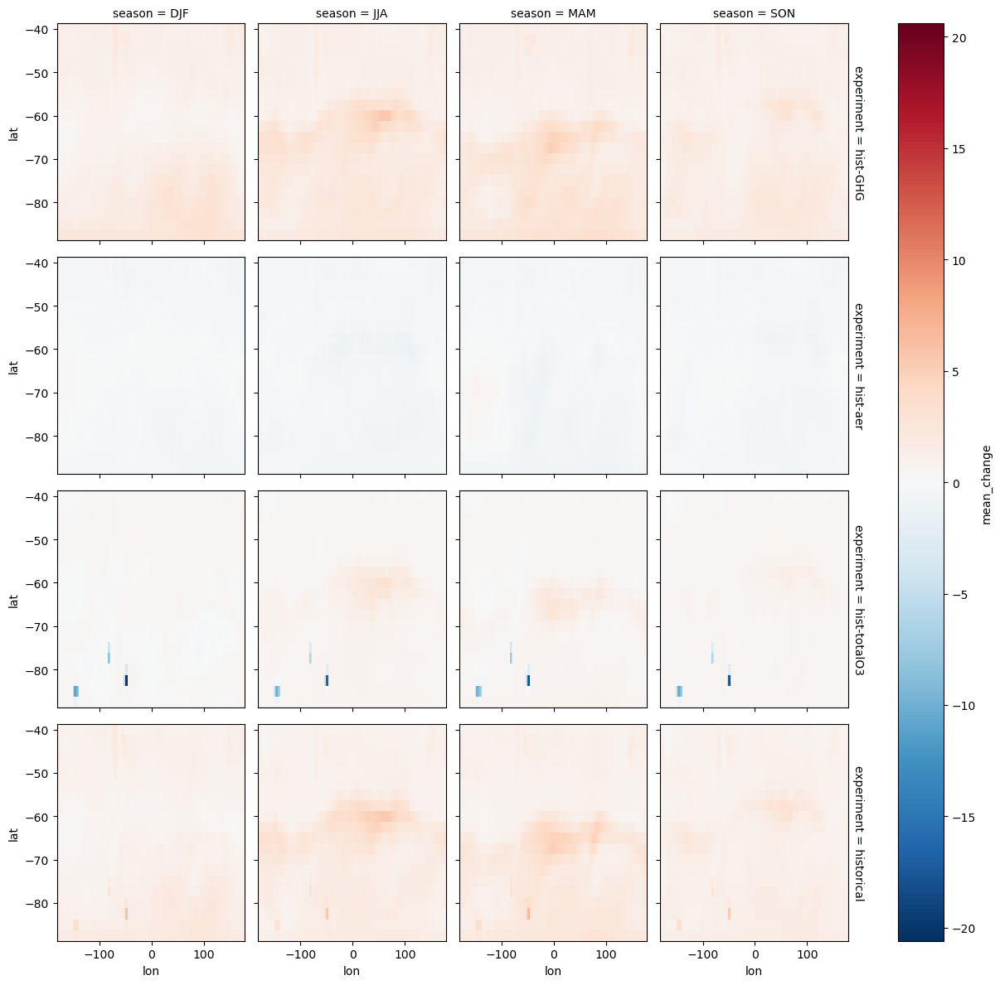

In [204]:
#(t): Quick look: the change in the mean for DEMO_MODEL, experiments down and seasons across, on the plain lat-lon grid
mean_bootstrap_ds['mean_change'].sel(model=DEMO_MODEL).plot(
    x='lon', y='lat', row='experiment', col='season', cmap='RdBu_r', center=0);

### Four tests side by side

The share of the area each test calls significant ($p < 0.05$), averaged over models and seasons. The two Welch tests count correlated values as independent, so they call too much; the member-block test and the hist-nat bootstrap both compare with hist-nat's final $L$ years.

In [205]:
#(t): Where each test calls the change significant (p < ALPHA), NaN where there is no data
ttest_significant_da = (ttest_ds['p'] < ALPHA).where(ttest_ds['p'].notnull())
ttest_rolling_median_significant_da = (ttest_rolling_median_ds['p'] < ALPHA).where(
    ttest_rolling_median_ds['p'].notnull())
mean_block_significant_da = (mean_block_ds['pvalue'] < ALPHA).where(mean_block_ds['pvalue'].notnull())
mean_bootstrap_significant_da = (mean_bootstrap_ds['pvalue'] < ALPHA).where(mean_bootstrap_ds['pvalue'].notnull())

In [206]:
#(t): % of the area each test calls significant, averaged over models and seasons
ttest_area_da = 100 * sig.area_mean(ttest_significant_da.sel(experiment=config.FORCED_EXPERIMENTS)).mean(['model', 'season'])
ttest_rolling_median_area_da = 100 * sig.area_mean(ttest_rolling_median_significant_da).mean(['model', 'season'])
mean_block_area_da = 100 * sig.area_mean(mean_block_significant_da).mean(['model', 'season'])
mean_bootstrap_area_da = 100 * sig.area_mean(mean_bootstrap_significant_da).mean(['model', 'season'])
pd.DataFrame({'Welch t-test (years pooled)': ttest_area_da.to_series(),
              'Welch t-test (rolling medians)': ttest_rolling_median_area_da.to_series(),
              'member-block test': mean_block_area_da.to_series(),
              'hist-nat bootstrap': mean_bootstrap_area_da.to_series()}).round(0)

,Welch t-test (years pooled),Welch t-test (rolling medians),member-block test,hist-nat bootstrap
experiment,,,,
hist-GHG,97.0,99.0,96.0,95.0
hist-aer,72.0,93.0,62.0,67.0
hist-totalO3,74.0,92.0,64.0,66.0
historical,96.0,98.0,95.0,94.0


### By SAM phase

The hist-nat bootstrap of the mean in the seasons of each SAM phase alone (*SAM Phases*, above): each experiment's mean in a phase against hist-nat's in the same phase, and against the same trials, each pooling only its members' seasons in that phase (about 70 of its 210). The change in a phase is how much a forcing has changed the seasons with that state of the SAM. So it leaves out most of the change that comes from the SAM spending more time in one phase; not all of it, since in the positive phase, say, a shifted SAM can also sit further above the threshold.

In [207]:
#(t): The final WINDOW years (lesfmip_final_tree: section 3) of the nodes with an index
lesfmip_sam_final_tree = lesfmip_final_tree.filter(lambda node: node.relative_to(lesfmip_final_tree) in sam_both_paths)

In [208]:
#(t): Split into the three phases: NaN outside each phase's seasons, on (phase, member, year, season, lat, lon)
lesfmip_phase_tree = xr.map_over_datasets(sam.by_phase, lesfmip_sam_final_tree, sam_final_masks_tree)

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 21, season: 4, phase: 3)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │         * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season, phase) float32 145MB dask.array<chunksize=(50, 4, 144, 21, 4, 3), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (member: 30, lat: 20, lon: 144, year: 21, season: 4, phase: 3)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │         * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season, phase) float32 87MB dask.array<chunksize=(30, 4, 144, 21, 4, 3), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 21, season: 4, phase: 3)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season, phase) float32 145MB dask.array<chunksize=(50, 4, 144, 21, 4, 3), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (member: 10, lat: 20, lon: 144, year: 21, season: 4, phase: 3)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * member   (member) object 80B 'r10i1p1f1' 'r1i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│   │         * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season, phase) float32 29MB dask.array<chunksize=(10, 4, 144, 21, 4, 3), meta=np.ndarray>
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 65, lat: 20, lon: 144, year: 21, season: 4, phase: 3)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│             * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'
│           Data variables:
│      

In [209]:
%%time
#(t): The mean in each phase, members and years pooled, every experiment, on (model, experiment, phase, season, lat, lon)
phase_mean_ds = datatree.reduce_to_dataset(lesfmip_phase_tree, lambda ds: ds.mean(['member', 'year'])).compute()

CPU times: user 91.1 ms, sys: 9.93 ms, total: 101 ms
Wall time: 990 ms


<xarray.Dataset> Size: 4MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144, phase: 3)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
Data variables:
    tas         (lat, lon, season, phase, model, experiment) float32 4MB -24....

In [210]:
#(t): hist-nat's
phase_hist_nat_mean_da = phase_mean_ds[VARIABLE.name].sel(experiment='hist-nat', drop=True)

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, phase: 3, model: 6)> Size: 829kB
-26.7 nan nan nan -28.58 -28.69 -27.16 ... 13.83 13.32 nan nan nan 11.62 13.91
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'

In [211]:
#(t): every other experiment's
phase_experiment_mean_da = phase_mean_ds[VARIABLE.name].drop_sel(experiment='hist-nat')

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, phase: 3, model: 6,
                         experiment: 4)> Size: 3MB
-24.28 -27.13 -26.43 -24.81 nan nan nan ... 11.74 12.33 14.5 13.9 13.84 14.27
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'

In [212]:
#(t): The change in the mean in each phase
phase_mean_change_da = phase_experiment_mean_da - phase_hist_nat_mean_da

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, phase: 3, model: 6,
                         experiment: 4)> Size: 3MB
2.429 -0.4275 0.2798 1.894 nan nan ... 0.7141 0.5819 -0.01446 -0.07739 0.3607
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'

In [213]:
%%time
#(t): The bootstrap in each phase: the same draws (the same seed), each trial pooling its members' seasons in the phase
phase_trial_mean_ds = datatree.reduce_to_dataset(
    lesfmip_phase_tree.match('*/hist-nat'), partial(sig.bootstrap_mean, n_trials=N_TRIALS, seed=0),
)
phase_trial_mean_da = phase_trial_mean_ds[VARIABLE.name].sel(experiment='hist-nat', drop=True).persist()
wait(phase_trial_mean_da)

CPU times: user 123 ms, sys: 4.1 ms, total: 127 ms
Wall time: 1.15 s


<xarray.DataArray 'tas' (trial: 1000, lat: 20, lon: 144, season: 4, phase: 3,
                         model: 6)> Size: 2GB
dask.array<chunksize=(1000, 4, 144, 4, 3, 1), meta=np.ndarray>
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'
  * trial    (trial) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999

In [214]:
%%time
#(t): The p-value of every experiment's mean in each phase against its model's trials in that phase
phase_mean_pvalue_da = sig.pvalue_two_sided(phase_trial_mean_da, phase_experiment_mean_da).compute()

CPU times: user 37.4 ms, sys: 13.3 ms, total: 50.7 ms
Wall time: 1.48 s


<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, phase: 3, model: 6,
                         experiment: 4)> Size: 7MB
0.001998 0.001998 0.005994 0.001998 nan ... 0.001998 0.7433 0.07792 0.001998
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'

In [215]:
#(t): The trials as changes: each trial's mean minus hist-nat's, in each phase
phase_null_mean_da = phase_trial_mean_da - phase_hist_nat_mean_da

In [216]:
%%time
#(t): Their central 1 - ALPHA
phase_null_mean_bounds_da = nan_quantile(phase_null_mean_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial').compute()

CPU times: user 8.4 ms, sys: 7.65 ms, total: 16.1 ms
Wall time: 1.12 s


<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, phase: 3, model: 6,
                         quantile: 2)> Size: 3MB
-0.2018 0.1851 nan nan nan nan nan ... nan nan -0.06572 0.07738 -0.08439 0.09194
Coordinates:
  * model     (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon       (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat       (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * phase     (phase) <U8 96B 'negative' 'neutral' 'positive'
  * quantile  (quantile) float64 16B 0.025 0.975

In [217]:
#(t): The mean test by SAM phase in one Dataset, laid out as mean_bootstrap_ds with a phase dim
sam_mean_bootstrap_ds = xr.Dataset({
    'hist_nat_mean': phase_hist_nat_mean_da,
    'experiment_mean': phase_experiment_mean_da,
    'mean_change': phase_mean_change_da,
    'null_lower': phase_null_mean_bounds_da.isel(quantile=0, drop=True),
    'null_upper': phase_null_mean_bounds_da.isel(quantile=1, drop=True),
    'pvalue': phase_mean_pvalue_da,
})
sam_mean_bootstrap_ds

<xarray.Dataset> Size: 17MB
Dimensions:          (model: 6, season: 4, lat: 20, lon: 144, phase: 3,
                      experiment: 4)
Coordinates:
  * model            (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * season           (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat              (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
  * lon              (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * phase            (phase) <U8 96B 'negative' 'neutral' 'positive'
  * experiment       (experiment) object 32B 'hist-GHG' ... 'historical'
Data variables:
    hist_nat_mean    (lat, lon, season, phase, model) float32 829kB -26.7 ......
    experiment_mean  (lat, lon, season, phase, model, experiment) float32 3MB ...
    mean_change      (lat, lon, season, phase, model, experiment) float32 3MB ...
    null_lower       (lat, lon, season, phase, model) float64 2MB -0.2018 ......
    null_upper       (lat, lon, season, phase, model) float64 2MB 0.1851 ... ...
    pvalue           (lat, lon, season, phase, model, experiment) float64 7MB ...

In [218]:
#(t): Saved for notebooks plot_03 to plot_06
sam_mean_bootstrap_path = RESULTS_DIR / 'sam_mean_bootstrap.zarr'
sam_mean_bootstrap_ds.to_zarr(sam_mean_bootstrap_path, mode='w')
sam_mean_bootstrap_path

17:40:35 INFO    extant.storage | writing Dataset (model: 6, season: 4, lat: 20, lon: 144, phase: 3, experiment: 4) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_mean_bootstrap.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `<U8` is currently not part in the Zarr format 3 specification. It may not be supported by

17:40:36 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_mean_bootstrap.zarr


PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_mean_bootstrap.zarr')

In [219]:
#(t): Its value at the demonstration point, every phase
sam_mean_bootstrap_ds.sel(**DEMO_SEL, experiment=DEMO_EXPERIMENT).sel(**DEMO_LATLON).to_dataframe().round(3)

,model,season,lat,lon,hist_nat_mean,experiment,experiment_mean,mean_change,null_lower,null_upper,pvalue
phase,,,,,,,,,,,
negative,CanESM5,DJF,-75.0,-180.0,-4.992,historical,-4.218,0.774,-0.341,0.322,0.002
neutral,CanESM5,DJF,-75.0,-180.0,-4.900,historical,-4.186,0.714,-0.301,0.323,0.002
positive,CanESM5,DJF,-75.0,-180.0,-5.172,historical,-4.008,1.164,-0.312,0.349,0.002


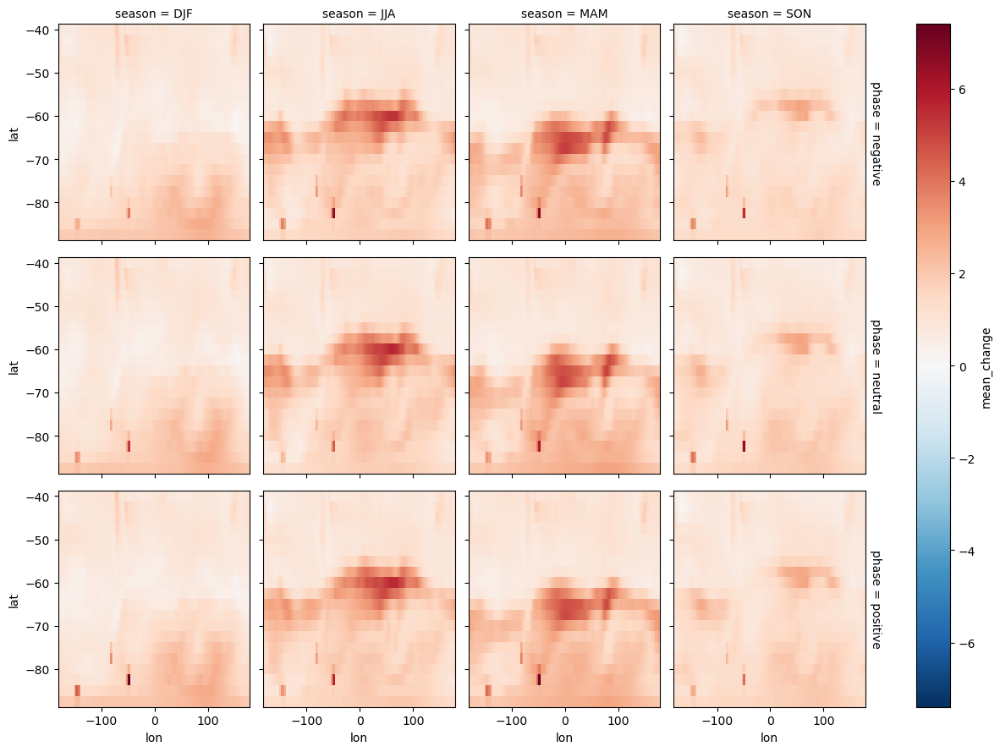

In [220]:
#(t): Quick look: DEMO_MODEL's change in the mean in each phase, DEMO_EXPERIMENT
sam_mean_bootstrap_ds['mean_change'].sel(model=DEMO_MODEL, experiment=DEMO_EXPERIMENT).plot(
    x='lon', y='lat', row='phase', col='season', cmap='RdBu_r', center=0);

## 5. Signal to Noise

**Signal.** The forced response of each experiment is its ensemble mean, smoothed with LOWESS (81 years); the signal is the experiment's minus hist-nat's:

$$
S(t) = F_{\mathrm{exp}}(t) - F_{\mathrm{nat}}(t), \qquad F(t) = \mathrm{LOWESS}\left(\tfrac{1}{M}\textstyle\sum_m x_{m,t}\right).
$$

(The ensemble means are smoothed as anomalies from their own whole-record mean, which is then added back; LOWESS commutes with adding a constant, so this changes nothing but the numerics.)

**Noise.** Each member's deviation from its own experiment's forced response, $x_{m,y} - F(y)$, pooled over members and a rolling $L$-year window, gives a standard deviation $\sigma(t)$ for each experiment; the noise pools the experiment's and hist-nat's:

$$
N(t) = \sqrt{\tfrac{1}{2}\left(\sigma^2_{\mathrm{exp}}(t) + \sigma^2_{\mathrm{nat}}(t)\right)}, \qquad \mathrm{S/N}(t) = \frac{S(t)}{N(t)}.
$$

$|\mathrm{S/N}| \ge 2$ counts as emerged. This asks a stricter question than the tests in section 4: whether the shift stands out from year-to-year noise, i.e. whether a single realisation, like the real world, would show it.

In [221]:
#(t): Each experiment's whole-record mean (no member dim, so a Dataset)
base_mean_ds = datatree.reduce_to_dataset(lesfmip_season_tree, lambda ds: ds.mean(dim=['year', 'member']))

<xarray.Dataset> Size: 1MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
Data variables:
    tas         (lat, lon, season, model, experiment) float32 1MB dask.array<chunksize=(4, 144, 4, 1, 1), meta=np.ndarray>

In [222]:
#(t): Every member's anomaly from it (a tree)
base_mean_tree = datatree.dataset_to_tree(base_mean_ds, like=lesfmip_season_tree)
lesfmip_season_anom_tree = lesfmip_season_tree - base_mean_tree

In [223]:
#(t): Each experiment's ensemble-mean anomaly
lesfmip_mm_anom_ds = datatree.reduce_to_dataset(lesfmip_season_anom_tree, lambda ds: ds.mean(dim='member'))

<xarray.Dataset> Size: 227MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144,
                 year: 164)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
Data variables:
    tas         (lat, lon, year, season, model, experiment) float32 227MB dask.array<chunksize=(4, 144, 164, 4, 1, 1), meta=np.ndarray>

In [224]:
#(t): smoothed with LOWESS (81 years): each experiment's forced response, as an anomaly
lesfmip_mm_signal_ds = qc.lowess_xarray(lesfmip_mm_anom_ds, core_dims='year').persist()
wait(lesfmip_mm_signal_ds)

<xarray.Dataset> Size: 453MB
Dimensions:     (lat: 20, lon: 144, season: 4, model: 6, experiment: 5,
                 year: 164)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
Data variables:
    tas         (model, experiment, season, lat, lon, year) float64 453MB dask.array<chunksize=(1, 1, 4, 4, 144, 164), meta=np.ndarray>

In [225]:
#(t): Each member's deviation from its experiment's forced response
lesfmip_mm_signal_tree = datatree.dataset_to_tree(lesfmip_mm_signal_ds, like=lesfmip_season_anom_tree)
lesfmip_detrend_tree = (lesfmip_season_anom_tree - lesfmip_mm_signal_tree).persist()
wait(lesfmip_detrend_tree)

DoneAndNotDoneFutures(done=set(), not_done=set())

In [226]:
#(t): Its standard deviation, every member's values pooled in the WINDOW years centred on each year
#(c): Persisted: the noise below is made from it, and it is saved too
lesfmip_experiment_noise_ds = datatree.reduce_to_dataset(lesfmip_detrend_tree, partial(qc.rolling_std, window=WINDOW))
lesfmip_experiment_noise_ds = lesfmip_experiment_noise_ds.persist()
wait(lesfmip_experiment_noise_ds)
lesfmip_experiment_noise_ds

<xarray.Dataset> Size: 453MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144,
                 year: 164)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
Data variables:
    tas         (year, lat, lon, season, model, experiment) float64 453MB dask.array<chunksize=(164, 4, 144, 4, 1, 1), meta=np.ndarray>

In [227]:
%%time
#(t): The noise: each experiment's and hist-nat's pooled (slow)
lesfmip_noise_ds = np.sqrt(0.5 * (lesfmip_experiment_noise_ds.sel(experiment='hist-nat') ** 2
                                  + lesfmip_experiment_noise_ds ** 2)).compute()
lesfmip_noise_ds

CPU times: user 198 ms, sys: 417 ms, total: 615 ms
Wall time: 6.85 s


<xarray.Dataset> Size: 453MB
Dimensions:     (year: 164, lat: 20, lon: 144, season: 4, model: 6,
                 experiment: 5)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
Data variables:
    tas         (year, lat, lon, season, model, experiment) float64 453MB 0.8...

In [228]:
%%time
#(t): Each experiment's forced response: the smoothed anomaly plus the whole-record mean
lesfmip_forced_ds = (lesfmip_mm_signal_ds + base_mean_ds).compute()
lesfmip_forced_ds

CPU times: user 221 ms, sys: 405 ms, total: 626 ms
Wall time: 6.7 s


<xarray.Dataset> Size: 453MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144,
                 year: 164)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
Data variables:
    tas         (model, experiment, season, lat, lon, year) float64 453MB -27...

In [229]:
#(t): The signal: each experiment's forced response minus hist-nat's
lesfmip_signal_ds = lesfmip_forced_ds - lesfmip_forced_ds.sel(experiment='hist-nat')
lesfmip_signal_ds

<xarray.Dataset> Size: 453MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144,
                 year: 164)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
Data variables:
    tas         (model, experiment, season, lat, lon, year) float64 453MB -0....

In [230]:
%%time
#(t): S/N
lesfmip_seasonal_sn_ds = (lesfmip_signal_ds / lesfmip_noise_ds).compute()
lesfmip_seasonal_sn_ds

CPU times: user 464 ms, sys: 42.8 ms, total: 506 ms
Wall time: 506 ms


<xarray.Dataset> Size: 453MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144,
                 year: 164)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
Data variables:
    tas         (model, experiment, season, lat, lon, year) float64 453MB -0....

In [231]:
#(t): Saved for notebooks plot_03 to plot_06
signal_path = RESULTS_DIR / 'signal.zarr'
lesfmip_signal_ds.to_zarr(signal_path, mode='w')
signal_path

17:41:15 INFO    extant.storage | writing Dataset (model: 6, experiment: 5, season: 4, lat: 20, lon: 144, year: 164) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/signal.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:41:21 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/signal.zarr
17:41:21 INFO    extant.storage | writing Dataset (year: 164, lat: 20, lon: 144, season: 4, model: 6, experiment: 5) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/noise.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:41:24 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/noise.zarr
17:41:24 INFO    extant.storage | writing Dataset (model: 6, experiment: 5, season: 4, lat: 20, lon: 144, year: 164) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/sn.zarr


...

17:41:28 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/sn.zarr
17:41:28 INFO    extant.storage | writing Dataset (model: 6, experiment: 5, season: 4, lat: 20, lon: 144, year: 164) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/forced.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:41:30 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/forced.zarr
17:41:30 INFO    extant.storage | writing Dataset (model: 6, experiment: 5, season: 4, lat: 20, lon: 144, year: 164) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/experiment_noise.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:41:33 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/experiment_noise.zarr


In [ ]:
#(t): Saved for notebooks plot_03 to plot_06
noise_path = RESULTS_DIR / 'noise.zarr'
lesfmip_noise_ds.to_zarr(noise_path, mode='w')
noise_path

In [ ]:
#(t): Saved for notebooks plot_03 to plot_06
sn_path = RESULTS_DIR / 'sn.zarr'
lesfmip_seasonal_sn_ds.to_zarr(sn_path, mode='w')
sn_path

In [ ]:
#(t): Saved for notebooks plot_03 to plot_06
forced_path = RESULTS_DIR / 'forced.zarr'
lesfmip_forced_ds.to_zarr(forced_path, mode='w')
forced_path

In [ ]:
%%time
#(t): Saved for notebook plot_03; loaded from the cluster first, so it is written in one piece
experiment_noise_path = RESULTS_DIR / 'experiment_noise.zarr'
lesfmip_experiment_noise_ds.load().to_zarr(experiment_noise_path, mode='w')
experiment_noise_path

The three parts at the demonstration point, picked out of the results, plotted plainly, then the method figure:

In [232]:
#(t): The demonstration point picked out of the forced responses, on (experiment, year)
point_forced_da = lesfmip_forced_ds[VARIABLE.name].sel(**DEMO_SEL).sel(**DEMO_LATLON)
point_forced_da

<xarray.DataArray 'tas' (experiment: 5, year: 164)> Size: 7kB
-4.992 -4.99 -4.988 -4.985 -4.983 -4.981 ... -4.03 -4.02 -4.011 -4.002 -3.993
Coordinates:
    model       <U7 28B 'CanESM5'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
    season      <U3 12B 'DJF'
    lat         float64 8B -75.0
    lon         float64 8B -180.0
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013

In [233]:
#(t): of the noise
point_noise_da = lesfmip_noise_ds[VARIABLE.name].sel(**DEMO_SEL).sel(**DEMO_LATLON)
point_noise_da

<xarray.DataArray 'tas' (year: 164, experiment: 5)> Size: 7kB
1.541 1.522 1.527 1.516 1.52 1.539 1.525 ... 1.467 1.391 1.563 1.527 1.561 1.47
Coordinates:
    model       <U7 28B 'CanESM5'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
    season      <U3 12B 'DJF'
    lat         float64 8B -75.0
    lon         float64 8B -180.0
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013

In [234]:
#(t): and of S/N
point_sn_da = lesfmip_seasonal_sn_ds[VARIABLE.name].sel(**DEMO_SEL).sel(**DEMO_LATLON)
point_sn_da

<xarray.DataArray 'tas' (experiment: 5, year: 164)> Size: 7kB
-0.0004351 -0.0004179 -0.0004021 -0.000386 ... 0.6813 0.6904 0.6935 0.6995
Coordinates:
    model       <U7 28B 'CanESM5'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
    season      <U3 12B 'DJF'
    lat         float64 8B -75.0
    lon         float64 8B -180.0
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013

In [235]:
#(t): The ensemble means at the point: one per experiment, as a Dataset on (experiment, year, season)
demo_ensemble_mean_tree = demo_tree.mean('member')
demo_ensemble_mean_ds = datatree.tree_to_dataset(demo_ensemble_mean_tree, dims=['experiment'])

<xarray.Dataset> Size: 15kB
Dimensions:     (experiment: 5, year: 164, season: 4)
Coordinates:
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
    lat         float64 8B -75.0
    lon         float64 8B -180.0
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
Data variables:
    tas         (year, season, experiment) float32 13kB -4.718 -4.69 ... -17.88

In [236]:
#(t): DEMO_EXPERIMENT's and hist-nat's, in the demonstration season
demo_ensemble_mean_da = demo_ensemble_mean_ds[VARIABLE.name].sel(experiment=[DEMO_EXPERIMENT, 'hist-nat'],
                                                            season=DEMO_POINT['season'])
demo_ensemble_mean_da

<xarray.DataArray 'tas' (year: 164, experiment: 2)> Size: 1kB
-4.928 -4.92 -4.961 -5.05 -4.906 -4.879 ... -4.945 -4.011 -4.883 -4.175 -4.586
Coordinates:
  * experiment  (experiment) object 16B 'historical' 'hist-nat'
    season      <U3 12B 'DJF'
    lat         float64 8B -75.0
    lon         float64 8B -180.0
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013

In [ ]:
#(t): Signal, noise and their ratio at the point: a) each ensemble's mean (thin) and its smoothed forced response
#(t): (thick), the gap between the thick lines the signal; b) the noise, the pooled rolling standard deviation; c) S/N,
#(t): grey where |S/N| < 2 (not emerged)
sn_experiments = [DEMO_EXPERIMENT, 'hist-nat']
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=3, n_legends=1, panel_width=4.3, panel_height=2.8,
                                                  column_gap=0.75), layout='constrained')
axes = fig.add_gridspec(1, 3).subplots(sharex=True, squeeze=False)
for experiment in sn_experiments:
    charts.plot_lines(demo_ensemble_mean_da.sel(experiment=experiment), 'year', ax=axes[0, 0],
                      color=FORCING_COLORS[experiment], linewidth=0.6, alpha=0.5)
    charts.plot_lines(point_forced_da.sel(experiment=experiment), 'year', ax=axes[0, 0],
                      color=FORCING_COLORS[experiment], linewidth=2.2)
charts.plot_lines(point_noise_da.sel(experiment=DEMO_EXPERIMENT), 'year', ax=axes[0, 1], color='0.25', linewidth=1.8)
axes[0, 2].axhspan(-2, 2, color='0.92', zorder=0)
charts.plot_lines(point_sn_da.sel(experiment=DEMO_EXPERIMENT), 'year', ax=axes[0, 2],
                  color=FORCING_COLORS[DEMO_EXPERIMENT], linewidth=1.8)
axes[0, 2].axhline(0, color='0.5', lw=0.8)

axes[0, 0].set_title('a) Ensemble means and forced response', loc='left')
axes[0, 1].set_title('b) Noise: pooled rolling std', loc='left')
axes[0, 2].set_title(f'c) S/N: ({DEMO_EXPERIMENT} − hist-nat) / noise', loc='left')
for ax in axes[0, :2]:
    ax.set_ylabel(VARIABLE.units)
for ax in axes[0]:
    ax.set_xlabel('Year')
fig.legend(handles=charts.forcing_legend_handles(sn_experiments) + [Patch(color='0.92', label='|S/N| < 2')],
           loc='outside lower center', ncols=3, frameon=False)
fig.suptitle(f'Signal and noise: {DEMO_EXPERIMENT} at the point', x=0.01, ha='left');

## 6. Additivity: Each Forcing's Change from Its Own Baseline

Single-forcing experiments contain *only* their forcing, so each one's response is best measured from its own pre-industrial baseline (1850–1900), not from hist-nat's full record. Measuring everything from hist-nat's full-record mean subtracts hist-nat's average volcanic cooling from every single forcing, so a sum of four forcings would subtract it four times while historical subtracts it once.

The **residual**, historical − (nat + GHG + aer + O3), holds everything the parts leave out: land use (hist-lu, which should be very small over Antarctica), any other forcing, and non-additive interaction between forcings. Fractions of historical are only given where |historical| ≥ 0.25 °C; elsewhere they blow up.

$$
\Delta_e = \bar{x}^{\,e}_{\text{final } L \text{ years}} - \bar{x}^{\,e}_{1850\text{–}1900},
\qquad
\text{residual} = \Delta_{\mathrm{historical}} - \left(\Delta_{\mathrm{nat}} + \Delta_{\mathrm{GHG}} + \Delta_{\mathrm{aer}} + \Delta_{\mathrm{O_3}}\right).
$$

In [239]:
#(t): Every experiment's 1850-1900 baseline
lesfmip_baseline_tree = lesfmip_season_tree.sel(year=slice(1850, 1900))

In [240]:
%%time
#(t): Its ensemble mean over those years
baseline_mean_ds = datatree.reduce_to_dataset(lesfmip_baseline_tree, lambda ds: ds.mean(['year', 'member'])).compute()

CPU times: user 82.7 ms, sys: 1.85 ms, total: 84.6 ms
Wall time: 926 ms


<xarray.Dataset> Size: 1MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
Data variables:
    tas         (lat, lon, season, model, experiment) float32 1MB -26.97 ... ...

In [241]:
#(t): Each experiment's change from its own baseline: the final WINDOW years (section 4) minus 1850-1900, ensemble means
own_changes_ds = final_mean_ds - baseline_mean_ds
own_changes_da = own_changes_ds[VARIABLE.name].rename('own_change')
own_changes_da

<xarray.DataArray 'own_change' (lat: 20, lon: 144, season: 4, model: 6,
                                experiment: 5)> Size: 1MB
2.187 -0.493 -0.03037 -0.1338 1.566 ... 0.5115 0.02814 -0.01114 -0.09152 0.337
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5

In [242]:
#(t): Saved for notebooks plot_03 to plot_06
own_changes_path = RESULTS_DIR / 'own_changes.zarr'
own_changes_da.to_dataset(name='own_change').to_zarr(own_changes_path, mode='w')
own_changes_path

17:41:35 INFO    extant.storage | writing DataArray (lat: 20, lon: 144, season: 4, model: 6, experiment: 5) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/own_changes.zarr
17:41:35 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/own_changes.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/own_changes.zarr')

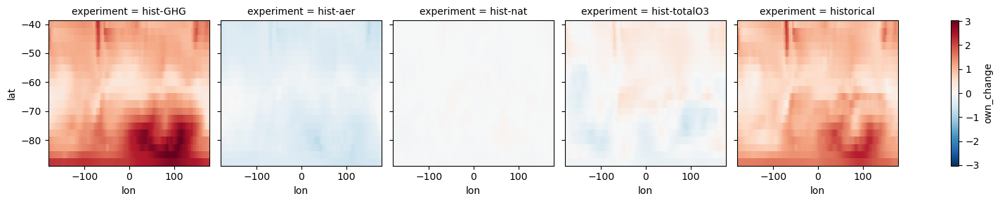

In [243]:
#(t): Quick look: DEMO_MODEL's change from its own 1850-1900 baseline in one season
own_changes_da.sel(**DEMO_SEL).plot(x='lon', y='lat', col='experiment', cmap='RdBu_r', center=0);

## 7. Mean and Variability Change: the Inputs

The combined figures in notebook plot_03 put the mean response next to the change in width and in each tail:

- the **mean response**, `mean_response_da` from section 4: the final $L$ years of each experiment minus hist-nat over the same years, members pooled, exactly the difference the t-test and the member-block test test;
- the **tails**: the warm tail's length $Q_{95} - Q_{50}$ and the cold tail's $Q_{50} - Q_{05}$, each experiment's final years against hist-nat's over the same years, from the quantiles of section 2 (on `qrange_tree`), so that

$$
\Delta(Q_{95} - Q_{50}) + \Delta(Q_{50} - Q_{05}) = \Delta(Q_{95} - Q_{05}).
$$

In [244]:
#(t): The change in Q05, Q50 and Q95 of qrange_tree (section 2): final years minus hist-nat's over the same years
tail_q_change_da = qrange_final_q_da - qrange_hist_nat_q_da

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, quantile: 3, model: 6,
                         experiment: 4)> Size: 7MB
0.00755 0.01652 -0.02147 -0.0197 -0.08383 ... -0.1165 -0.09249 -0.1547 -0.09254
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * quantile    (quantile) float64 24B 0.05 0.5 0.95

In [245]:
#(t): Each of the three
q05_change_da = tail_q_change_da.sel(quantile=Q_LOW, drop=True)
q50_change_da = tail_q_change_da.sel(quantile=0.50, drop=True)
q95_change_da = tail_q_change_da.sel(quantile=Q_HIGH, drop=True)

In [246]:
#(t): The change in the warm tail's length, Q95 - Q50, and in the cold tail's, Q50 - Q05
upper_tail_change_da = q95_change_da - q50_change_da
lower_tail_change_da = q50_change_da - q05_change_da

In [247]:
#(t): The tails in one Dataset, laid out as notebook plot_03 opens it: their sum is the change in width, their difference
#(t): the asymmetry (> 0 when the warm tail stretches more)
tails_ds = xr.Dataset({
    'upper_tail_change': upper_tail_change_da,
    'lower_tail_change': lower_tail_change_da,
    'width_change': upper_tail_change_da + lower_tail_change_da,
    'tail_asymmetry': upper_tail_change_da - lower_tail_change_da,
    'q05_change': q05_change_da,
    'q50_change': q50_change_da,
    'q95_change': q95_change_da,
})
tails_ds

<xarray.Dataset> Size: 15MB
Dimensions:            (model: 6, experiment: 4, season: 4, lat: 20, lon: 144)
Coordinates:
  * model              (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * experiment         (experiment) object 32B 'hist-GHG' ... 'historical'
  * season             (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat                (lat) float64 160B -87.5 -85.0 -82.5 ... -42.5 -40.0
  * lon                (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
Data variables:
    upper_tail_change  (lat, lon, season, model, experiment) float64 2MB -0.0...
    lower_tail_change  (lat, lon, season, model, experiment) float64 2MB 0.03...
    width_change       (lat, lon, season, model, experiment) float64 2MB 0.01...
    tail_asymmetry     (lat, lon, season, model, experiment) float64 2MB -0.0...
    q05_change         (lat, lon, season, model, experiment) float64 2MB 0.00...
    q50_change         (lat, lon, season, model, experiment) float64 2MB 0.03...
    q95_change         (lat, lon, season, model, experiment) float64 2MB 0.02...

In [248]:
#(t): Saved for notebooks plot_03 to plot_06
mean_response_path = RESULTS_DIR / 'mean_response.zarr'
mean_response_da.to_dataset(name='mean_response').to_zarr(mean_response_path, mode='w')
mean_response_path

17:41:36 INFO    extant.storage | writing DataArray (lat: 20, lon: 144, season: 4, model: 6, experiment: 4) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/mean_response.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:41:36 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/mean_response.zarr
17:41:36 INFO    extant.storage | writing Dataset (model: 6, experiment: 4, season: 4, lat: 20, lon: 144) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/tails.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:41:38 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/tails.zarr


In [ ]:
#(t): Saved for notebooks plot_03 to plot_06
tails_path = RESULTS_DIR / 'tails.zarr'
tails_ds.to_zarr(tails_path, mode='w')
tails_path

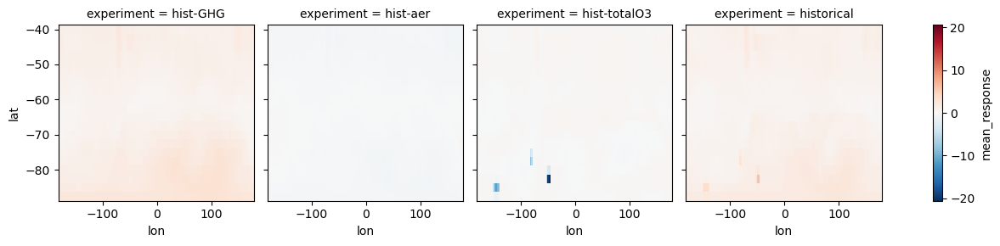

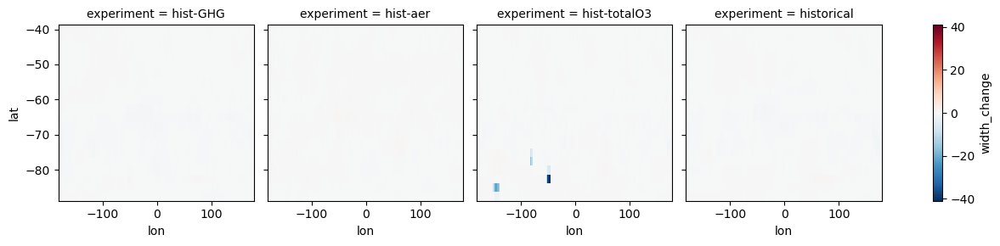

In [249]:
#(t): Quick look: DEMO_MODEL's mean response and change in width in one season
mean_response_da.sel(**DEMO_SEL).plot(x='lon', y='lat', col='experiment', cmap='RdBu_r', center=0)
tails_ds['width_change'].sel(**DEMO_SEL).plot(x='lon', y='lat', col='experiment', cmap='RdBu_r', center=0);

### By SAM phase

The tails in each SAM phase, from the quantiles of section 2's SAM subsection (`phase_final_q_da`, `phase_hist_nat_q_da`), so they add up to its change in width in each phase.

In [250]:
#(t): The change in Q05, Q50 and Q95 in each phase: the final years minus hist-nat's in the same phase
phase_tail_q_change_da = phase_final_q_da - phase_hist_nat_q_da

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, phase: 3, quantile: 3,
                         model: 6, experiment: 4)> Size: 20MB
0.2664 0.0307 0.252 0.04834 nan ... 0.09385 -0.02687 -0.0821 -0.03515 -0.1244
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
  * quantile    (quantile) float64 24B 0.05 0.5 0.95

In [251]:
#(t): Each of the three
phase_q05_change_da = phase_tail_q_change_da.sel(quantile=Q_LOW, drop=True)
phase_q50_change_da = phase_tail_q_change_da.sel(quantile=0.50, drop=True)
phase_q95_change_da = phase_tail_q_change_da.sel(quantile=Q_HIGH, drop=True)

In [252]:
#(t): The change in the warm tail's length, Q95 - Q50, and in the cold tail's, Q50 - Q05
phase_upper_tail_change_da = phase_q95_change_da - phase_q50_change_da
phase_lower_tail_change_da = phase_q50_change_da - phase_q05_change_da

In [253]:
#(t): The tails by SAM phase in one Dataset, laid out as tails_ds with a phase dim
sam_tails_ds = xr.Dataset({
    'upper_tail_change': phase_upper_tail_change_da,
    'lower_tail_change': phase_lower_tail_change_da,
    'width_change': phase_upper_tail_change_da + phase_lower_tail_change_da,
    'tail_asymmetry': phase_upper_tail_change_da - phase_lower_tail_change_da,
    'q05_change': phase_q05_change_da,
    'q50_change': phase_q50_change_da,
    'q95_change': phase_q95_change_da,
})
sam_tails_ds

<xarray.Dataset> Size: 46MB
Dimensions:            (model: 6, experiment: 4, season: 4, lat: 20, lon: 144,
                        phase: 3)
Coordinates:
  * model              (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * experiment         (experiment) object 32B 'hist-GHG' ... 'historical'
  * season             (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat                (lat) float64 160B -87.5 -85.0 -82.5 ... -42.5 -40.0
  * lon                (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * phase              (phase) <U8 96B 'negative' 'neutral' 'positive'
Data variables:
    upper_tail_change  (lat, lon, season, phase, model, experiment) float64 7MB ...
    lower_tail_change  (lat, lon, season, phase, model, experiment) float64 7MB ...
    width_change       (lat, lon, season, phase, model, experiment) float64 7MB ...
    tail_asymmetry     (lat, lon, season, phase, model, experiment) float64 7MB ...
    q05_change         (lat, lon, season, phase, model, experiment) float64 7MB ...
    q50_change         (lat, lon, season, phase, model, experiment) float64 7MB ...
    q95_change         (lat, lon, season, phase, model, experiment) float64 7MB ...

In [254]:
#(t): Saved for notebooks plot_03 to plot_06
sam_tails_path = RESULTS_DIR / 'sam_tails.zarr'
sam_tails_ds.to_zarr(sam_tails_path, mode='w')
sam_tails_path

17:41:39 INFO    extant.storage | writing Dataset (model: 6, experiment: 4, season: 4, lat: 20, lon: 144, phase: 3) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_tails.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:41:41 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_tails.zarr


PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_tails.zarr')

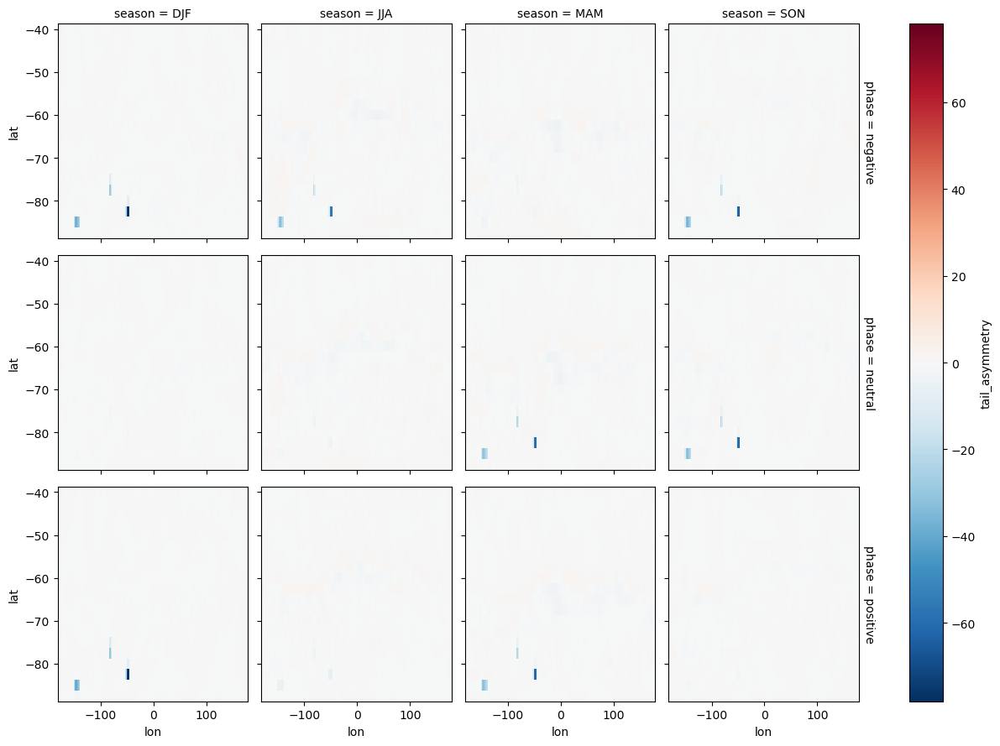

In [255]:
#(t): Quick look: DEMO_MODEL's tail asymmetry in each phase, DEMO_EXPERIMENT
sam_tails_ds['tail_asymmetry'].sel(model=DEMO_MODEL, experiment=DEMO_EXPERIMENT).plot(
    x='lon', y='lat', row='phase', col='season', cmap='RdBu_r', center=0);

## 8. Zonal Means: the Change at Each Latitude

Bracegirdle et al. (2024, *npj Clim. Atmos. Sci.* 7, 276) show the change in the low extremes, the mean, the high extremes and the width between them against latitude, averaged round the pole, with the sea-ice edge marked. Notebook plot_03 (section 7) draws the same from the changes above, for every model on its own. This section tests the zonal means themselves, with the tests used for the maps, from what sections 2 and 4 already made:

- **the mean**: the hist-nat bootstrap of section 4. A trial draws the same 10 hist-nat members at every grid point, so its changes (its mean minus hist-nat's) averaged over longitude are one draw of what natural variability alone does to the zonal mean. A mean is linear, so the change in the zonal mean is the zonal mean of the change at each point: the test is of exactly the plotted line.
- **the width**: the hist-nat bootstrap trials of section 2, in the same way. Trial $k$'s change at each point is its width minus hist-nat's over the same years, and averaged over longitude $\lambda$ it is one draw of what natural variability alone does to the zonal-mean width:

$$
\overline{\Delta W}_k(\varphi) = \frac{1}{N_\lambda} \sum_{\lambda} \left(W_k(\varphi, \lambda) - W^{\mathrm{nat}}(\varphi, \lambda)\right), \qquad k = 1, \ldots, N,
$$

and the observed $\overline{\Delta W}_{\mathrm{obs}}(\varphi)$ is compared with these trials as before. Averaging over longitude cancels much of the noise, so a zonal-mean change can be significant where few single points are.

The zonal-mean width is the average of the *local* widths (how much a season varies at each point), not the width of the zonal-mean series, in which anomalies at different longitudes would cancel. The low and high extremes have no test of their own.

In [256]:
#(t): The zonal-mean change in the mean (section 4)
zonal_mean_change_da = zonal.zonal_mean(mean_bootstrap_change_da)

<xarray.DataArray 'tas' (lat: 20, season: 4, model: 6, experiment: 4)> Size: 8kB
2.494 -0.4453 0.1086 1.911 2.082 ... 0.567 0.3812 -0.1742 -0.09633 0.2899
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0

In [257]:
#(t): The zonal mean of every bootstrap trial's change (section 4): the zonal-mean null
zonal_null_mean_da = zonal.zonal_mean(null_mean_da)

<xarray.DataArray 'tas' (trial: 1000, lat: 20, season: 4, model: 6)> Size: 4MB
dask.array<chunksize=(1000, 4, 4, 1), meta=np.ndarray>
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * trial    (trial) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999

In [258]:
%%time
#(t): The two-sided p-value of every experiment's zonal-mean change against its model's trials
zonal_mean_pvalue_da = sig.pvalue_two_sided(zonal_null_mean_da, zonal_mean_change_da).compute()

CPU times: user 20.7 ms, sys: 982 μs, total: 21.7 ms
Wall time: 461 ms


<xarray.DataArray 'tas' (lat: 20, season: 4, model: 6, experiment: 4)> Size: 15kB
0.001998 0.001998 0.1399 0.001998 ... 0.001998 0.001998 0.001998 0.001998
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'

In [259]:
#(t): The zonal mean test in one Dataset, laid out as notebook plot_03 opens it
zonal_mean_ds = xr.Dataset({'mean_change': zonal_mean_change_da, 'pvalue': zonal_mean_pvalue_da})
zonal_mean_ds

<xarray.Dataset> Size: 23kB
Dimensions:      (model: 6, experiment: 4, season: 4, lat: 20)
Coordinates:
  * model        (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment   (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season       (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat          (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
Data variables:
    mean_change  (lat, season, model, experiment) float32 8kB 2.494 ... 0.2899
    pvalue       (lat, season, model, experiment) float64 15kB 0.001998 ... 0...

In [260]:
#(t): The zonal-mean change in width (section 2)
zonal_width_change_da = zonal.zonal_mean(qrange_change_da)

<xarray.DataArray 'tas' (lat: 20, season: 4, model: 6, experiment: 4)> Size: 15kB
-0.1202 -0.09157 -0.02232 0.00791 0.1773 ... 0.008247 -0.04722 -0.0331 -0.007168
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0

In [261]:
#(t): The zonal mean of every bootstrap trial's change (section 2): the zonal-mean null
zonal_null_da = zonal.zonal_mean(qrange_null_da)

<xarray.DataArray 'tas' (trial: 1000, lat: 20, season: 4, model: 6)> Size: 4MB
dask.array<chunksize=(1000, 4, 4, 1), meta=np.ndarray>
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * trial    (trial) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999

In [262]:
%%time
#(t): The two-sided p-value of every experiment's zonal-mean change against its model's trials
zonal_width_pvalue_da = sig.pvalue_two_sided(zonal_null_da, zonal_width_change_da).compute()

CPU times: user 19.7 ms, sys: 2.22 ms, total: 21.9 ms
Wall time: 522 ms


<xarray.DataArray 'tas' (lat: 20, season: 4, model: 6, experiment: 4)> Size: 15kB
0.6394 0.7772 0.8691 0.7053 0.1079 ... 0.001998 0.2817 0.02597 0.1998 0.8332
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'

In [263]:
%%time
#(t): The central 1 - ALPHA of the zonal-mean trials
zonal_null_bounds_da = nan_quantile(zonal_null_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial').compute()

CPU times: user 4.96 ms, sys: 3.45 ms, total: 8.41 ms
Wall time: 532 ms


<xarray.DataArray 'tas' (lat: 20, season: 4, model: 6, quantile: 2)> Size: 8kB
-0.3022 0.2413 -0.2836 0.2274 -0.2768 ... -0.04818 0.02686 -0.04367 0.02441
Coordinates:
  * model     (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lat       (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * quantile  (quantile) float64 16B 0.025 0.975

In [264]:
#(t): hist-nat's zonal-mean width over the final years
zonal_hist_nat_width_da = zonal.zonal_mean(hist_nat_qrange_da)

<xarray.DataArray 'tas' (lat: 20, season: 4, model: 6)> Size: 4kB
3.305 4.164 3.288 2.993 3.171 3.702 ... 1.104 1.438 1.367 1.144 1.346 1.212
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0

In [265]:
#(t): The zonal width test in one Dataset, laid out as notebook plot_03 opens it
zonal_width_ds = xr.Dataset({
    'width_change': zonal_width_change_da,
    'width_pvalue': zonal_width_pvalue_da,
    'hist_nat_width': zonal_hist_nat_width_da,
    'null_lower': zonal_null_bounds_da.isel(quantile=0, drop=True),
    'null_upper': zonal_null_bounds_da.isel(quantile=1, drop=True),
})
zonal_width_ds

<xarray.Dataset> Size: 43kB
Dimensions:         (model: 6, experiment: 4, season: 4, lat: 20)
Coordinates:
  * model           (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment      (experiment) object 32B 'hist-GHG' ... 'historical'
  * season          (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat             (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
Data variables:
    width_change    (lat, season, model, experiment) float64 15kB -0.1202 ......
    width_pvalue    (lat, season, model, experiment) float64 15kB 0.6394 ... ...
    hist_nat_width  (lat, season, model) float64 4kB 3.305 4.164 ... 1.346 1.212
    null_lower      (lat, season, model) float64 4kB -0.3022 ... -0.04367
    null_upper      (lat, season, model) float64 4kB 0.2413 0.2274 ... 0.02441

In [266]:
#(t): Saved for notebooks plot_03 to plot_06
zonal_mean_test_path = RESULTS_DIR / 'zonal_mean_test.zarr'
zonal_mean_ds.to_zarr(zonal_mean_test_path, mode='w')
zonal_mean_test_path

17:41:44 INFO    extant.storage | writing Dataset (model: 6, experiment: 4, season: 4, lat: 20) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/zonal_mean_test.zarr
17:41:44 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/zonal_mean_test.zarr
17:41:44 INFO    extant.storage | writing Dataset (model: 6, experiment: 4, season: 4, lat: 20) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/zonal_width_test.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:41:45 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/zonal_width_test.zarr


In [ ]:
#(t): Saved for notebooks plot_03 to plot_06
zonal_width_test_path = RESULTS_DIR / 'zonal_width_test.zarr'
zonal_width_ds.to_zarr(zonal_width_test_path, mode='w')
zonal_width_test_path

For the demonstration model and season: the zonal-mean change in the mean and in the width for each experiment, with dots where it is significant. The grey band in the width panel is the central 95% of the hist-nat trials, the changes natural variability gives on its own; a line outside it is significant.

In [ ]:
#(t): The zonal tests together, for DEMO_MODEL in its season, on (experiment, lat)
zonal_demo_ds = xr.merge([zonal_mean_ds.rename(pvalue='mean_pvalue'), zonal_width_ds], join='outer').sel(
    model=DEMO_MODEL, season=DEMO_POINT['season'])
zonal_demo_ds

In [ ]:
#(t): The zonal-mean tests: the change in the mean and in the width at each latitude, one line per experiment, a dot
#(t): where it is significant (p < ALPHA); grey, the central 95% of hist-nat's own width changes
zonal_demo_experiments = [e for e in FORCING_COLORS if e in zonal_demo_ds['experiment'].values]
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=2, n_legends=1), layout='constrained')
axes = fig.add_gridspec(1, 2).subplots(sharex=True, squeeze=False)
for ax in axes[0]:
    ax.axhline(0, color='0.64', linewidth=0.8, zorder=1)
charts.plot_band(zonal_demo_ds['null_lower'], zonal_demo_ds['null_upper'], 'lat', ax=axes[0, 1], color=zp.NULL_COLOR)
for experiment in zonal_demo_experiments:
    experiment_zonal_ds = zonal_demo_ds.sel(experiment=experiment)
    for ax, change, pvalue in zip(axes[0], ['mean_change', 'width_change'], ['mean_pvalue', 'width_pvalue']):
        charts.plot_lines(experiment_zonal_ds[change], 'lat', ax=ax, color=FORCING_COLORS[experiment], linewidth=1.6)
        charts.plot_significant_dots(experiment_zonal_ds[change], experiment_zonal_ds[pvalue] < ALPHA, 'lat', ax=ax,
                                     color=FORCING_COLORS[experiment])
axes[0, 0].set_title('Mean\nΔ mean', loc='left')
axes[0, 1].set_title('Width (high − low)\nΔ(Q95 − Q05)', loc='left')
axes[0, 0].set_ylabel(f'{DEMO_MODEL}\n({VARIABLE.units})')
for ax in axes[0]:
    ax.set_xlabel('Latitude')
axes[0, 0].xaxis.set_major_formatter(zp.latitude_label)
axes[0, 0].set_xlim(float(zonal_demo_ds['lat'].min()), float(zonal_demo_ds['lat'].max()))
fig.legend(handles=charts.forcing_legend_handles(zonal_demo_experiments) + [
Line2D([], [], linestyle='none', marker='o', markersize=5, color='k', markeredgecolor='white',
label=f'Significant (p < {ALPHA:g})'),
Patch(color=zp.NULL_COLOR, label='hist-nat variability alone (95%)')],
loc='outside lower center', ncols=len(zonal_demo_experiments) + 2, frameon=False)
fig.suptitle(f"The zonal-mean tests: {DEMO_MODEL}, {DEMO_POINT['season']}", x=0.01, ha='left');

## 9. Regional Means

The regional figures of notebook plot_06, and the regional probability ratios of sections 10 and 11, use area means over regions (`REGIONS`, the boxes notebook calc_03a uses), weighted by the cosine of latitude:

$$
\bar{x}^{R}_{m,y} = \frac{\sum_{(\varphi, \lambda) \in R} \cos\varphi \; x_{m,y}(\varphi, \lambda)}{\sum_{(\varphi, \lambda) \in R} \cos\varphi}.
$$

A region with no grid points in the data is NaN (the sample has only its 3×3 block, in East Antarctica). The quantile curves are the regional means of each grid point's change in every 5th percentile (section 3), as the Antarctic-mean curve is.

In [269]:
#(t): The regions: name -> the box selected on the grid
REGIONS

{'Antarctica (90–65°S)': {'lat': slice(-90, -65, None)},
 'Antarctic Peninsula': {'lat': slice(-75, -62.5, None),
  'lon': slice(-75, -55, None)},
 'Southern Ocean (65–50°S)': {'lat': slice(-65, -50, None)}}

In [270]:
#(t): Every member's regional means, every year: a tree like lesfmip_season_tree, with region in place of lat and lon
regional_season_tree = oc.regional_means(lesfmip_season_tree, REGIONS)
regional_season_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (region: 3, member: 50, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│   │       Data variables:
│   │           tas      (region, member, year, season) float64 787kB dask.array<chunksize=(1, 50, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (region: 3, member: 30, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│   │       Data variables:
│   │           tas      (region, member, year, season) float64 472kB dask.array<chunksize=(1, 30, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (region: 3, member: 50, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│   │       Data variables:
│   │           tas      (region, member, year, season) float64 787kB dask.array<chunksize=(1, 50, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (region: 3, member: 10, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 80B 'r10i1p1f1' 'r1i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│   │       Data variables:
│   │           tas      (region, member, year, season) float64 157kB dask.array<chunksize=(1, 10, 164, 4), meta=np.ndarray>
│   └── Group: /CanESM5/historical
│           Dimensions:  (region: 3, member: 65, year: 164, season: 4)
│           Coordinates:
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│             * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│           Data variables:
│               tas      (region, member, year, season) float64 1MB dask.array<chunksize=(1, 65, 164, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (region: 3, member: 45, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 360B 'r10i1p1f2' 'r10i1p3f1' ... 'r9i1p3f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
│   │       Data variables:
│   │           tas      (region, member, year, season) float64 708kB dask.array<chunksize=(1, 45, 164, 4), meta=np.ndarray>
│   ├── Group: /GISS-E2-1-G/hist-nat
│   │       Dimensions:  (region: 3, member: 20, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│

In [271]:
%%time
#(t): Computed once: sections 10 and 11 use it, and notebook plot_06 opens it
regional_season_tree = regional_season_tree.compute()
regional_season_tree

CPU times: user 84 ms, sys: 29 ms, total: 113 ms
Wall time: 2.45 s


In [272]:
#(t): Saved for notebooks plot_03 to plot_06
regional_seasonal_path = RESULTS_DIR / 'regional_seasonal.zarr'
regional_season_tree.to_zarr(regional_seasonal_path, mode='w')
regional_seasonal_path

17:41:49 INFO    extant.storage | writing DataTree of 30 nodes to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/regional_seasonal.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `<U24` is currently not part in the Zarr format 3 specification. It may not be supported b

17:41:57 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/regional_seasonal.zarr


PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/regional_seasonal.zarr')

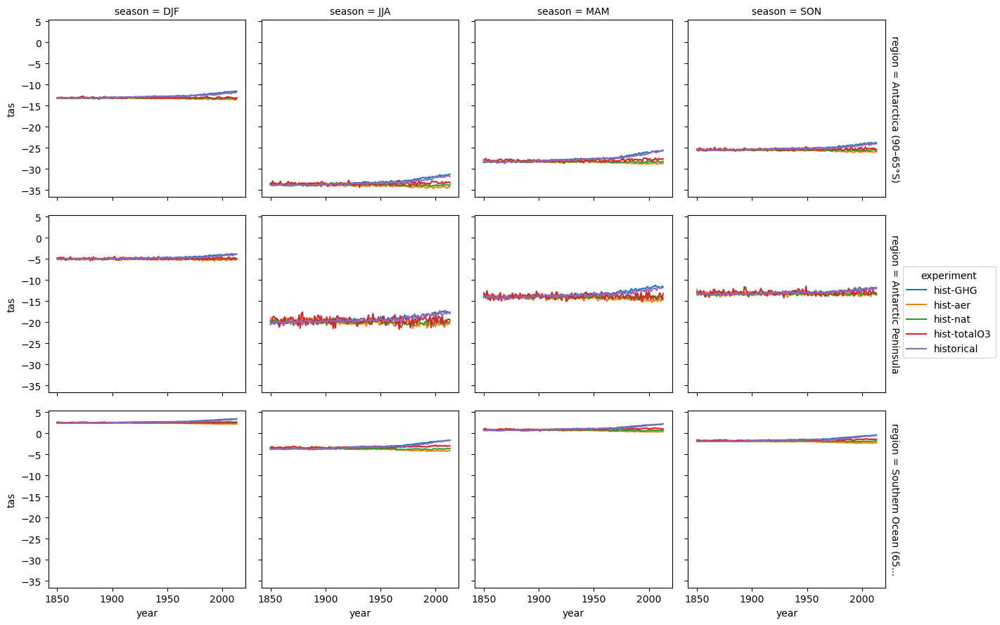

In [273]:
#(t): Quick look: DEMO_MODEL's ensemble means, one line per experiment, one panel per region and season
regional_demo_mean_ds = datatree.tree_to_dataset(regional_season_tree[DEMO_MODEL].mean('member'), dims=['experiment'])
regional_demo_mean_ds[VARIABLE.name].plot(x='year', hue='experiment', row='region', col='season');

In [274]:
#(t): The change in every 5th percentile (section 3), averaged over each region
regional_quantile_curve_da = oc.regional_means(quantile_change_da, REGIONS).rename('regional_quantile_curve')
regional_quantile_curve_da

<xarray.DataArray 'regional_quantile_curve' (region: 3, season: 4,
                                             quantile: 19, model: 6,
                                             experiment: 4)> Size: 44kB
1.54 -0.2366 0.1764 1.166 0.9853 ... 0.4739 0.2414 -0.2019 -0.02437 0.2095
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * quantile    (quantile) float64 152B 0.05 0.1 0.15 0.2 ... 0.8 0.85 0.9 0.95
  * region      (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean...

In [275]:
#(t): Saved for notebooks plot_03 to plot_06
regional_quantile_curve_path = RESULTS_DIR / 'regional_quantile_curve.zarr'
regional_quantile_curve_da.to_dataset(name='regional_quantile_curve').to_zarr(regional_quantile_curve_path, mode='w')
regional_quantile_curve_path

17:41:59 INFO    extant.storage | writing DataArray (region: 3, season: 4, quantile: 19, model: 6, experiment: 4) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/regional_quantile_curve.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `<U24` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported b

17:42:00 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/regional_quantile_curve.zarr


PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/regional_quantile_curve.zarr')

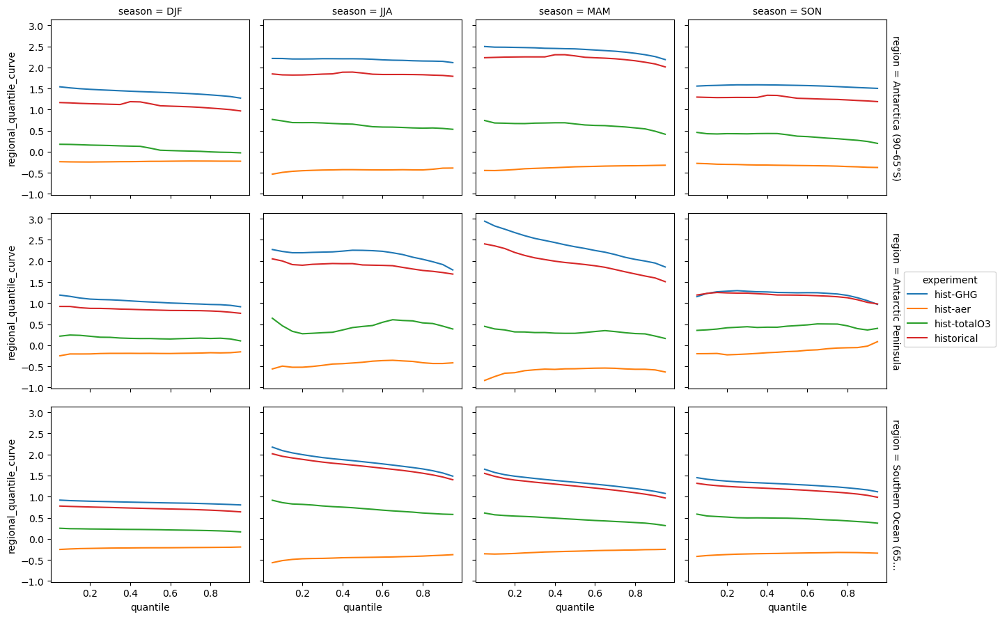

In [276]:
#(t): Quick look: DEMO_MODEL's regional quantile curves, one line per experiment
regional_quantile_curve_da.sel(model=DEMO_MODEL).plot.line(x='quantile', hue='experiment', row='region', col='season');

## 10. Probability Ratios

**The event.** A warm season is one warmer than hist-nat's 95th percentile, and a cold season one colder than its 5th percentile: seasons hist-nat itself has a 5% chance of. The percentiles come from hist-nat's final $L$ years, members and years pooled, the same years as the experiment's:

$$
T^{\mathrm{warm}} = Q_{1 - c}\left(x^{\mathrm{nat}}_{\text{final } L \text{ years}}\right), \qquad
T^{\mathrm{cold}} = Q_{c}\left(x^{\mathrm{nat}}_{\text{final } L \text{ years}}\right),
$$

with hist-nat's chance $c = 5\%$; $c = 10\%$ (its 90th and 10th percentiles) checks it (`CHANCES`). Rarer events are left out on purpose: with $P_{\mathrm{nat}}$ that small, the ratio rests on a handful of seasons.

**The ratio.** The chance of the event is the share of an ensemble's member-years beyond the threshold, member by member and then averaged, $P = \frac{1}{M}\sum_m \frac{1}{L}\sum_y \mathbb{1}\left[x_{m,y} > T^{\mathrm{warm}}\right]$ (below $T^{\mathrm{cold}}$ for a cold season), and

$$
\mathrm{PR} = \frac{P_{\mathrm{exp}}}{P_{\mathrm{nat}}},
$$

so PR = 2 means the forcing doubles the chance and PR = 1/2 halves it.

**Uncertainty.** A bootstrap of whole members: each trial draws as many members as each ensemble has, with replacement, and recalculates both chances against the *same* thresholds, so it asks how well the ensembles pin down the chance of one defined event. A ratio is significant where the central $1 - \alpha$ of its trials is clear of 1.

Section 11 then asks how much of the ratio the shift of the mean alone gives.

First the steps at the demonstration point, then everywhere, then for the regional means.

### At the demonstration point

In [277]:
#(t): The quantile each threshold sits at, on (tail, chance): 1 - chance for warm, the chance for cold
pr_levels_da = pr.threshold_levels(CHANCES)

<xarray.DataArray 'level' (tail: 2, chance: 2)> Size: 32B
0.95 0.9 0.05 0.1
Coordinates:
  * tail     (tail) <U4 32B 'warm' 'cold'
  * chance   (chance) float64 16B 0.05 0.1

In [278]:
#(t): hist-nat's thresholds at the demonstration point, from its final WINDOW years (section 4), members and years pooled
demo_thresholds_da = pr.thresholds(demo_histnat_final_da, pr_levels_da)

<xarray.DataArray 'tas' (tail: 2, chance: 2)> Size: 32B
-2.173 -2.678 -7.284 -6.903
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * tail     (tail) <U4 32B 'warm' 'cold'
  * chance   (chance) float64 16B 0.05 0.1

In [279]:
#(t): Each member's share of its years beyond them: DEMO_EXPERIMENT's
demo_experiment_exceedance_da = pr.member_exceedance(demo_experiment_final_da, demo_thresholds_da)

<xarray.DataArray (tail: 2, member: 65, chance: 2)> Size: 2kB
0.09524 0.1429 0.09524 0.1905 0.09524 0.1905 0.2381 ... 0.0 0.0 0.0 0.0 0.0 0.0
Coordinates:
  * tail     (tail) <U4 32B 'warm' 'cold'
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
  * chance   (chance) float64 16B 0.05 0.1

In [280]:
#(t): and hist-nat's
demo_histnat_exceedance_da = pr.member_exceedance(demo_histnat_final_da, demo_thresholds_da)

<xarray.DataArray (tail: 2, member: 50, chance: 2)> Size: 2kB
0.1429 0.1429 0.04762 0.09524 0.0 ... 0.04762 0.09524 0.09524 0.1905 0.1905
Coordinates:
  * tail     (tail) <U4 32B 'warm' 'cold'
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
  * chance   (chance) float64 16B 0.05 0.1

In [281]:
#(t): The chances, averaged over the members: DEMO_EXPERIMENT's
demo_p_experiment_da = demo_experiment_exceedance_da.mean('member')

<xarray.DataArray (tail: 2, chance: 2)> Size: 32B
0.1231 0.2037 0.001465 0.005861
Coordinates:
  * tail     (tail) <U4 32B 'warm' 'cold'
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * chance   (chance) float64 16B 0.05 0.1

In [282]:
#(t): and hist-nat's (about the chance, by construction)
demo_p_histnat_da = demo_histnat_exceedance_da.mean('member')

<xarray.DataArray (tail: 2, chance: 2)> Size: 32B
0.05048 0.1 0.05048 0.1
Coordinates:
  * tail     (tail) <U4 32B 'warm' 'cold'
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * chance   (chance) float64 16B 0.05 0.1

In [283]:
#(t): The probability ratio
demo_pr_da = demo_p_experiment_da / demo_p_histnat_da
demo_pr_da

<xarray.DataArray (tail: 2, chance: 2)> Size: 32B
2.438 2.037 0.02903 0.05861
Coordinates:
  * tail     (tail) <U4 32B 'warm' 'cold'
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * chance   (chance) float64 16B 0.05 0.1

In [284]:
#(t): The numbers side by side
pd.DataFrame({
    'threshold': demo_thresholds_da.to_series(),
    'P hist-nat': demo_p_histnat_da.to_series(),
    f'P {DEMO_EXPERIMENT}': demo_p_experiment_da.to_series(),
    'PR': demo_pr_da.to_series(),
}).round(3)

threshold  P hist-nat  P historical     PR
tail chance                                            
warm 0.05       -2.173        0.05         0.123  2.438
     0.10       -2.678        0.10         0.204  2.037
cold 0.05       -7.284        0.05         0.001  0.029
     0.10       -6.903        0.10         0.006  0.059

In [285]:
#(t): The bootstrap: the mean of DEMO_EXPERIMENT's members drawn with replacement, in each trial (seed 1)
demo_p_experiment_trials_da = pr.bootstrap_member_mean(demo_experiment_exceedance_da, n_trials=DEMO_TRIALS, seed=1)

<xarray.DataArray (trial: 10000, tail: 2, chance: 2)> Size: 320kB
0.1201 0.1905 0.001465 0.005861 0.1311 ... 0.1136 0.2015 0.001465 0.005128
Coordinates:
  * tail     (tail) <U4 32B 'warm' 'cold'
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * chance   (chance) float64 16B 0.05 0.1
  * trial    (trial) int64 80kB 0 1 2 3 4 5 6 ... 9994 9995 9996 9997 9998 9999

In [286]:
#(t): hist-nat's (seed 0)
demo_p_histnat_trials_da = pr.bootstrap_member_mean(demo_histnat_exceedance_da, n_trials=DEMO_TRIALS, seed=0)

In [287]:
#(t): Every trial's ratio
demo_pr_trials_da = demo_p_experiment_trials_da / demo_p_histnat_trials_da

<xarray.DataArray (trial: 10000, tail: 2, chance: 2)> Size: 320kB
2.103 1.754 0.03945 0.06547 2.869 2.276 ... 0.06294 1.955 1.872 0.03273 0.05551
Coordinates:
  * tail     (tail) <U4 32B 'warm' 'cold'
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * chance   (chance) float64 16B 0.05 0.1
  * trial    (trial) int64 80kB 0 1 2 3 4 5 6 ... 9994 9995 9996 9997 9998 9999

In [288]:
#(t): Its central 1 - ALPHA: the ratio is significant where it is clear of 1
demo_pr_bounds_da = demo_pr_trials_da.quantile([ALPHA / 2, 1 - ALPHA / 2], dim='trial')
demo_pr_bounds_da.to_series().unstack('quantile').round(2)

quantile     0.025  0.975
tail chance              
warm 0.05     1.83   3.38
     0.10     1.65   2.60
cold 0.05     0.00   0.08
     0.10     0.02   0.10

In [ ]:
#(t): The probability ratio of a warm and a cold season, step by step: a) the two ensembles' final years, hist-nat's
#(t): two percentiles (dashed) and how often each ensemble goes beyond them; b) the bootstrap's ratios, each tail
warm_percentile, cold_percentile = methods.percentile_words(CHANCES[0])
#(c): In the slides' big text, as the schematics are shown in talks too
with plt.rc_context(fr.SLIDES.rc):
    fig = plt.figure(figsize=(11, 8.5))
    ax_a, flow_axes, _, ax_b = methods.schematic_axes(fig, with_trials=False)
    methods.plot_thresholds(demo_experiment_final_da, demo_histnat_final_da, demo_thresholds_da.sel(chance=CHANCES[0]),
                            DEMO_EXPERIMENT, ax=ax_a)
    ax_a.set_title(f"a  Beyond hist-nat's {cold_percentile} and {warm_percentile} percentiles (dashed)", pad=10)
    ax_a.set_xlabel(VARIABLE.units)
    ax_a.set_ylabel('Density')
    methods.plot_flow(f"Resample whole members of each ensemble with replacement, "
                      f"{demo_pr_trials_da.sizes['trial']:,} times,\nand recalculate the ratio against the same "
                      f"thresholds", flow_axes[0])
    methods.plot_ratio_trials(demo_pr_trials_da.sel(chance=CHANCES[0]), 'probability ratio', ax=ax_b, alpha=0.45,
                              histtype='stepfilled')
    ax_b.set_title('b  Bootstrap of the ratio', pad=10)
    ax_b.set_xlabel('Probability ratio (log scale; 0 and beyond 64 at the ends)')
    ax_b.set_ylabel('Density');

### Everywhere

The same steps at every grid point. The thresholds come from hist-nat alone, so they are made once per model (one function mapped over the hist-nat nodes) and given to every experiment of that model.

In [291]:
#(t): hist-nat's final WINDOW years in every model (lesfmip_final_tree: section 3)
pr_hist_nat_final_tree = lesfmip_final_tree.match('*/hist-nat')

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/hist-nat
│           Dimensions:  (member: 50, lat: 20, lon: 144, year: 21, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│             * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 48MB dask.array<chunksize=(50, 4, 144, 21, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/hist-nat
│           Dimensions:  (member: 20, lat: 20, lon: 144, year: 21, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│             * member   (member) object 160B 'r10i1p1f3' 'r1i1p1f2' ... 'r9i1p1f3'
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 19MB dask.array<chunksize=(20, 4, 144, 21, 4), meta=np.ndarray>
├── Group: /NorESM2-LM
│   └── Group: /NorESM2-LM/hist-nat
│           Dimensions:  (member: 23, lat: 20, lon: 144, year: 21, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 22MB dask.array<chunksize=(23, 4, 144, 21, 4), meta=np.ndarray>
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/hist-nat
│           Dimensions:  (member: 60, lat: 20, lon: 144, year: 21, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * member   (member) object 480B 'r10i1p1f3' 'r11i1p1f3' ... 'r9i1p1f3'
│             * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 58MB dask.array<chunksize=(60, 4, 144, 21, 4), meta=np.ndarray>
├── Group: /MIROC6
│   └── Group: /MIROC6/hist-nat
│           Dimensions:  (member: 50, lat: 20, lon: 144, year: 21, season: 4)
│           Coordinates:
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * member   (member) object 400B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 48MB dask.array<chunksize=(50, 4, 144, 21, 4), meta=np.ndarray>
└── Group: /MPI-ESM1-2-LR
    └── Group: /MPI-ESM1-2-LR/hist-nat
            Dimensions:  (member: 30, lat: 20, lon: 144, year: 21, season: 4)
            Coordinates:
              * lon      (lon) float64 1kB -180.0 -177.5 -175.0

In [292]:
pr_levels_da

<xarray.DataArray 'level' (tail: 2, chance: 2)> Size: 32B
0.95 0.9 0.05 0.1
Coordinates:
  * tail     (tail) <U4 32B 'warm' 'cold'
  * chance   (chance) float64 16B 0.05 0.1

In [293]:
pr.thresholds?

Signature: pr.thresholds(counterfactual, levels, dims=('member', 'year'))
Docstring:
hist-nat's value at each level, its members and years pooled.

Args:
    counterfactual (xr.Dataset | xr.DataArray): hist-nat over the years compared, on (member, year, ...).
    levels (xr.DataArray): ``threshold_levels`` output, on (tail, chance).
    dims (Sequence[str]): The dims pooled (those present).

Returns:
    The same type, on (tail, chance, ...).
File:      ~/ExtAnt-initial/extant/probability_ratio.py
Type:      function

In [294]:
%%time
#(t): Its thresholds, members and years pooled, on (model, tail, chance, season, lat, lon)
pr_thresholds_ds = datatree.reduce_to_dataset(pr_hist_nat_final_tree, partial(pr.thresholds, levels=pr_levels_da))
pr_thresholds_ds = pr_thresholds_ds.sel(experiment='hist-nat', drop=True).compute()

CPU times: user 55.9 ms, sys: 4.21 ms, total: 60.1 ms
Wall time: 1.43 s


<xarray.Dataset> Size: 2MB
Dimensions:  (model: 6, lon: 144, lat: 20, season: 4, tail: 2, chance: 2)
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * tail     (tail) <U4 32B 'warm' 'cold'
  * chance   (chance) float64 16B 0.05 0.1
Data variables:
    tas      (lat, lon, season, tail, chance, model) float64 2MB -25.65 ... 1...

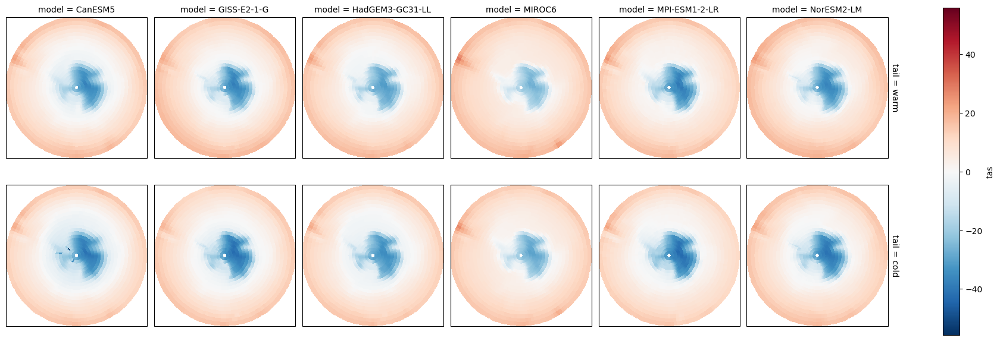

In [295]:
pr_thresholds_ds.tas.sel(chance=0.05, season='DJF').plot(row='tail', col='model',
                                             subplot_kws={'projection': ccrs.SouthPolarStereo()}, transform=ccrs.PlateCarree())

In [296]:
#(t): The same thresholds for every experiment of a model, as a tree shaped like lesfmip_final_tree
pr_thresholds_tree = datatree.dataset_to_tree(pr_thresholds_ds.expand_dims(experiment=config.MAIN_EXPERIMENTS),
                                              like=lesfmip_final_tree)

In [297]:
pr_thresholds_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (lon: 144, lat: 20, season: 4, tail: 2, chance: 2)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * tail     (tail) <U4 32B 'warm' 'cold'
│   │         * chance   (chance) float64 16B 0.05 0.1
│   │       Data variables:
│   │           tas      (lat, lon, season, tail, chance) float64 369kB -25.65 ... 12.8
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (lon: 144, lat: 20, season: 4, tail: 2, chance: 2)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * tail     (tail) <U4 32B 'warm' 'cold'
│   │         * chance   (chance) float64 16B 0.05 0.1
│   │       Data variables:
│   │           tas      (lat, lon, season, tail, chance) float64 369kB -25.65 ... 12.8
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (lon: 144, lat: 20, season: 4, tail: 2, chance: 2)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * tail     (tail) <U4 32B 'warm' 'cold'
│   │         * chance   (chance) float64 16B 0.05 0.1
│   │       Data variables:
│   │           tas      (lat, lon, season, tail, chance) float64 369kB -25.65 ... 12.8
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (lon: 144, lat: 20, season: 4, tail: 2, chance: 2)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * tail     (tail) <U4 32B 'warm' 'cold'
│   │         * chance   (chance) float64 16B 0.05 0.1
│   │       Data variables:
│   │           tas      (lat, lon, season, tail, chance) float64 369kB -25.65 ... 12.8
│   └── Group: /CanESM5/historical
│           Dimensions:  (lon: 144, lat: 20, season: 4, tail: 2, chance: 2)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * tail     (tail) <U4 32B 'warm' 'cold'
│             * chance   (chance) float64 16B 0.05 0.1
│           Data variables:
│               tas      (lat, lon, season, tail, chance) float64 369kB -25.65 ... 12.8
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (lon: 144, lat: 20, season: 4, tail: 2, chance: 2)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * tail     (tail) <U4 32B 'warm' 'cold'
│   │         * chance   (chance) float64 16B 0.05 0.1
│   │       Data variables:
│   │           tas      (lat, lon, season, tail, chance) float64 369kB -29.02 ... 11.29
│   ├── Group: /GISS-E2-1-G/hist-nat
│   │       Dimensions:  (lon: 144, lat: 20, season: 4, tail: 2, chance: 2)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat  

In [298]:
#(t): Each member's share of its years beyond them, every experiment (hist-nat's own gives the counterfactual)
pr_exceedance_tree = xr.map_over_datasets(pr.member_exceedance, lesfmip_final_tree, pr_thresholds_tree)

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (tail: 2, member: 50, lat: 20, lon: 144, season: 4, chance: 2)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * tail     (tail) <U4 32B 'warm' 'cold'
│   │         * chance   (chance) float64 16B 0.05 0.1
│   │       Data variables:
│   │           tas      (tail, member, lat, lon, season, chance) float64 18MB dask.array<chunksize=(2, 50, 4, 144, 4, 2), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (tail: 2, member: 30, lat: 20, lon: 144, season: 4, chance: 2)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * tail     (tail) <U4 32B 'warm' 'cold'
│   │         * chance   (chance) float64 16B 0.05 0.1
│   │       Data variables:
│   │           tas      (tail, member, lat, lon, season, chance) float64 11MB dask.array<chunksize=(2, 30, 4, 144, 4, 2), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (tail: 2, member: 50, lat: 20, lon: 144, season: 4, chance: 2)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * tail     (tail) <U4 32B 'warm' 'cold'
│   │         * chance   (chance) float64 16B 0.05 0.1
│   │       Data variables:
│   │           tas      (tail, member, lat, lon, season, chance) float64 18MB dask.array<chunksize=(2, 50, 4, 144, 4, 2), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (tail: 2, member: 10, lat: 20, lon: 144, season: 4, chance: 2)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * member   (member) object 80B 'r10i1p1f1' 'r1i1p1f1' ... 'r9i1p1f1'
│   │         * tail     (tail) <U4 32B 'warm' 'cold'
│   │         * chance   (chance) float64 16B 0.05 0.1
│   │       Data variables:
│   │           tas      (tail, member, lat, lon, season, chance) float64 4MB dask.array<chunksize=(2, 10, 4, 144, 4, 2), meta=np.ndarray>
│   └── Group: /CanESM5/historical
│           Dimensions:  (tail: 2, member: 65, lat: 20, lon: 144, season: 4, chance: 2)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * tail     (tail) <U4 32B 'warm' 'cold'
│             * chance   (chance) float64 16B 0.05 0.1
│           Data variables:
│               tas      (tail, member, lat, lon, season, chance) float64 24MB dask.array<chunksize=(2, 65, 4, 144, 4, 2), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (tail: 2, member: 45, lat: 20, lon: 144, season: 4, chance: 2)
│

In [299]:
%%time
#(t): The chances: every experiment's, averaged over its members
pr_p_ds = datatree.reduce_to_dataset(pr_exceedance_tree, lambda ds: ds.mean('member')).compute()

CPU times: user 110 ms, sys: 15.5 ms, total: 126 ms
Wall time: 7.4 s


<xarray.Dataset> Size: 11MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144,
                 tail: 2, chance: 2)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
Data variables:
    tas         (tail, lat, lon, season, chance, model, experiment) float64 11MB ...

In [300]:
pr_p_ds

<xarray.Dataset> Size: 11MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144,
                 tail: 2, chance: 2)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
Data variables:
    tas         (tail, lat, lon, season, chance, model, experiment) float64 11MB ...

In [301]:
#(t): hist-nat's own chance: the counterfactual
pr_p_counterfactual_ds = pr_p_ds.sel(experiment='hist-nat', drop=True)

<xarray.Dataset> Size: 2MB
Dimensions:  (model: 6, season: 4, lat: 20, lon: 144, tail: 2, chance: 2)
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * tail     (tail) <U4 32B 'warm' 'cold'
  * chance   (chance) float64 16B 0.05 0.1
Data variables:
    tas      (tail, lat, lon, season, chance, model) float64 2MB 0.05048 ... ...

In [302]:
#(t): The probability ratios (hist-nat against itself left out)
pr_ratio_ds = (pr_p_ds / pr_p_counterfactual_ds).drop_sel(experiment='hist-nat')

<xarray.Dataset> Size: 9MB
Dimensions:     (model: 6, experiment: 4, season: 4, lat: 20, lon: 144,
                 tail: 2, chance: 2)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
Data variables:
    tas         (tail, lat, lon, season, chance, model, experiment) float64 9MB ...

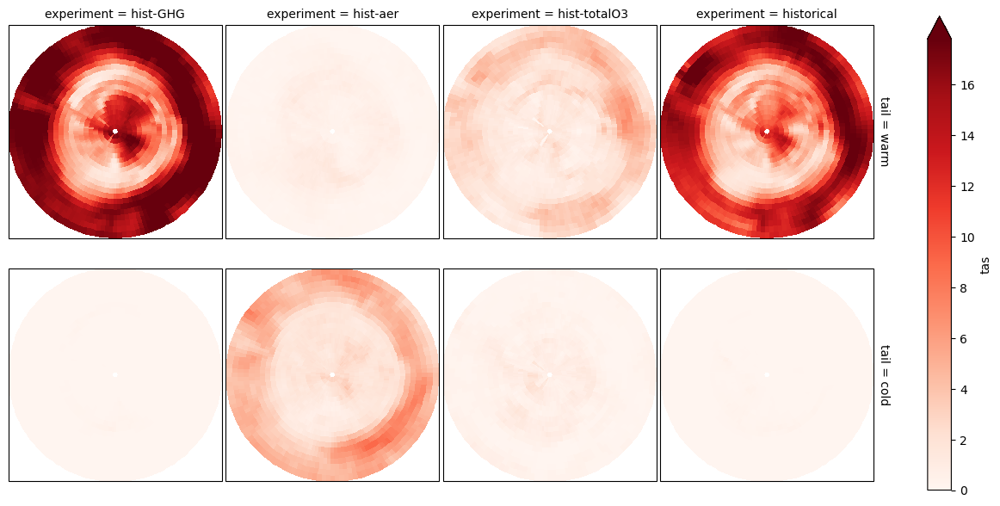

In [303]:
pr_ratio_ds.tas.sel(chance=0.05, season='DJF', model='CanESM5').plot(row='tail', col='experiment', robust=True, cmap='Reds',
                                             subplot_kws={'projection': ccrs.SouthPolarStereo()}, transform=ccrs.PlateCarree())

In [304]:
# .sel(chance=0.05, season='DJF').plot(row='tail', col='model',
#                                              subplot_kws={'projection': ccrs.SouthPolarStereo()}, transform=ccrs.PlateCarree())

In [305]:
#(t): The bootstrap: every experiment's members (seed 1), lazily, on (model, experiment, trial, ...)
pr_p_trials_tree = pr_exceedance_tree.map_over_datasets(partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=1))
pr_p_trials_ds = datatree.tree_to_dataset(pr_p_trials_tree, dims=['model', 'experiment'])

<xarray.Dataset> Size: 11GB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144,
                 tail: 2, chance: 2, trial: 1000)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
  * trial       (trial) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
Data variables:
    tas         (trial, tail, lat, lon, season, chance, model, experiment) float64 11GB dask.array<chunksize=(1000, 2, 4, 144, 4, 2, 1, 1), meta=np.ndarray>

In [306]:
#(t): hist-nat's members (seed 0): the counterfactual
pr_p_counterfactual_trials_ds = datatree.reduce_to_dataset(
    pr_exceedance_tree.match('*/hist-nat'), partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=0),
).sel(experiment='hist-nat', drop=True)

In [307]:
#(t): Every trial's ratio (lazy: only its quantiles are computed)
pr_trials_da = (pr_p_trials_ds / pr_p_counterfactual_trials_ds)[VARIABLE.name].drop_sel(experiment='hist-nat')

<xarray.DataArray 'tas' (trial: 1000, tail: 2, lat: 20, lon: 144, season: 4,
                         chance: 2, model: 6, experiment: 4)> Size: 9GB
dask.array<chunksize=(1000, 2, 4, 144, 4, 2, 1, 1), meta=np.ndarray>
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
  * trial       (trial) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999

In [308]:
%%time
#(t): Its central 1 - ALPHA
pr_bounds_da = nan_quantile(pr_trials_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial').compute()

CPU times: user 42 ms, sys: 28.8 ms, total: 70.9 ms
Wall time: 22.8 s


<xarray.DataArray 'tas' (tail: 2, lat: 20, lon: 144, season: 4, chance: 2,
                         model: 6, experiment: 4, quantile: 2)> Size: 18MB
12.04 24.39 0.06663 0.4488 0.9016 3.077 ... 1.632 0.9551 2.328 0.1208 0.3821
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
  * quantile    (quantile) float64 16B 0.025 0.975

In [309]:
#(t): The probability ratios in one Dataset, laid out as notebook plot_06 opens it
pr_ds = xr.Dataset({
    'threshold': pr_thresholds_ds[VARIABLE.name],
    'p_counterfactual': pr_p_counterfactual_ds[VARIABLE.name],
    'p_factual': pr_p_ds[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'pr': pr_ratio_ds[VARIABLE.name],
    'pr_lower': pr_bounds_da.isel(quantile=0, drop=True),
    'pr_upper': pr_bounds_da.isel(quantile=1, drop=True),
    'pr_significant': (pr_bounds_da.isel(quantile=0, drop=True) > 1) | (pr_bounds_da.isel(quantile=1, drop=True) < 1),
})
pr_ds

<xarray.Dataset> Size: 41MB
Dimensions:           (model: 6, lon: 144, lat: 20, season: 4, tail: 2,
                       chance: 2, experiment: 4)
Coordinates:
  * model             (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * lon               (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * lat               (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * tail              (tail) <U4 32B 'warm' 'cold'
  * chance            (chance) float64 16B 0.05 0.1
  * experiment        (experiment) object 32B 'hist-GHG' ... 'historical'
Data variables:
    threshold         (lat, lon, season, tail, chance, model) float64 2MB -25...
    p_counterfactual  (tail, lat, lon, season, chance, model) float64 2MB 0.0...
    p_factual         (tail, lat, lon, season, chance, model, experiment) float64 9MB ...
    pr                (tail, lat, lon, season, chance, model, experiment) float64 9MB ...
    pr_lower          (tail, lat, lon, season, chance, model, experiment) float64 9MB ...
    pr_upper          (tail, lat, lon, season, chance, model, experiment) float64 9MB ...
    pr_significant    (tail, lat, lon, season, chance, model, experiment) bool 1MB ...

In [310]:
#(t): Saved for notebooks plot_03 to plot_06
probability_ratio_path = RESULTS_DIR / 'probability_ratio.zarr'
pr_ds.to_zarr(probability_ratio_path, mode='w')
probability_ratio_path

17:42:38 INFO    extant.storage | writing Dataset (model: 6, lon: 144, lat: 20, season: 4, tail: 2, chance: 2, experiment: 4) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/probability_ratio.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `<U4` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by

17:42:41 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/probability_ratio.zarr


PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/probability_ratio.zarr')

In [311]:
#(t): Its value at the demonstration point: the same ratios as step by step above (the bounds from fewer trials)
pr_ds[['pr', 'pr_lower', 'pr_upper']].sel(**DEMO_SEL, experiment=DEMO_EXPERIMENT).sel(**DEMO_LATLON).to_dataframe().round(2)

pr  pr_lower  pr_upper    model    lon   lat season  experiment
tail chance                                                                   
warm 0.05    2.44      1.81      3.40  CanESM5 -180.0 -75.0    DJF  historical
     0.10    2.04      1.65      2.61  CanESM5 -180.0 -75.0    DJF  historical
cold 0.05    0.03      0.00      0.08  CanESM5 -180.0 -75.0    DJF  historical
     0.10    0.06      0.03      0.10  CanESM5 -180.0 -75.0    DJF  historical

/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/xarray/computation/apply_ufunc.py:813: RuntimeWarning: divide by zero encountered in log2
  result_data = func(*input_data)


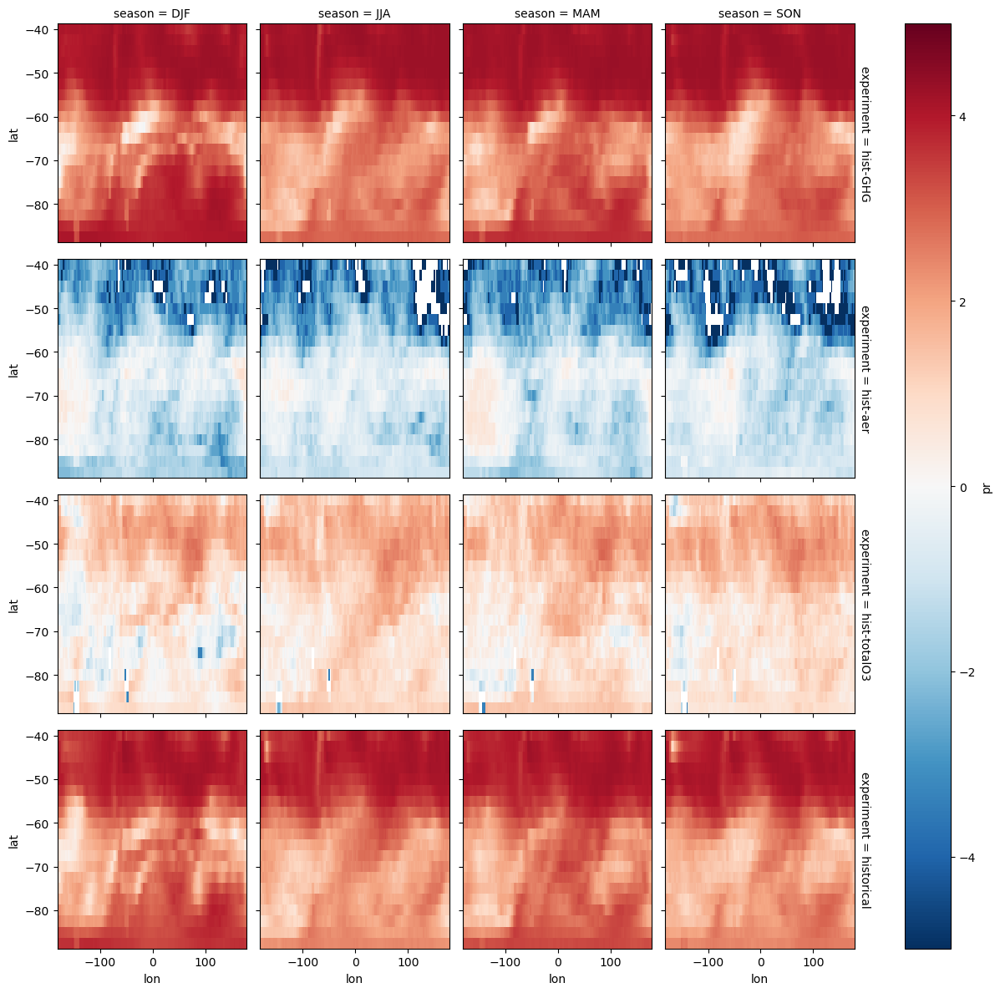

In [312]:
#(t): Quick look: DEMO_MODEL's warm ratio, log2 (1 doubles the chance), experiments down and seasons across
np.log2(pr_ds['pr'].sel(model=DEMO_MODEL, tail='warm', chance=CHANCES[0])).plot(
    x='lon', y='lat', row='experiment', col='season', cmap='RdBu_r', center=0);

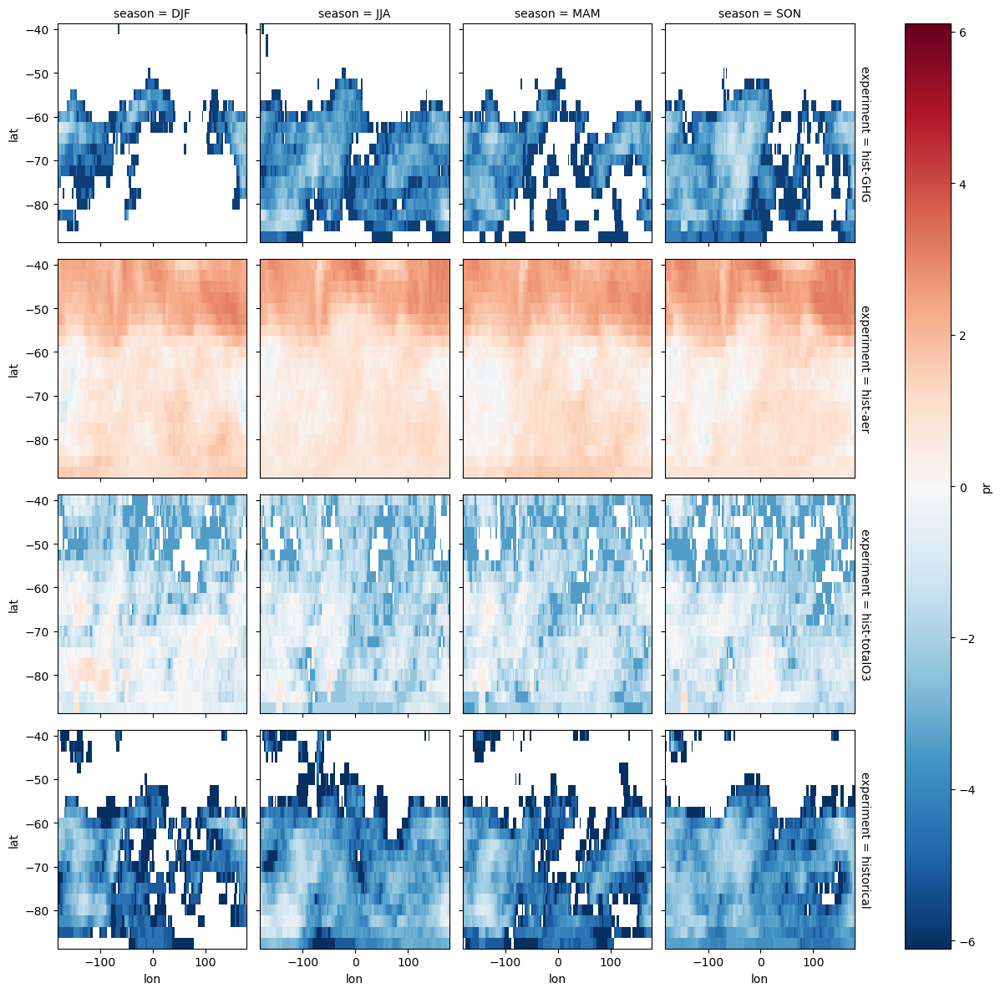

In [313]:
#(t): and the cold one
np.log2(pr_ds['pr'].sel(model=DEMO_MODEL, tail='cold', chance=CHANCES[0])).plot(
    x='lon', y='lat', row='experiment', col='season', cmap='RdBu_r', center=0);

### For the regional means

The same steps on the regional means of section 9: the thresholds are hist-nat's regional percentiles, so these are the ratios for a warm or cold season *of the region as a whole*, not the regional average of the local ratios.

In [314]:
#(t): The final WINDOW years of the regional means (section 9)
regional_final_tree = regional_season_tree.isel(year=slice(-WINDOW, None))

In [315]:
#(t): hist-nat's regional thresholds, on (model, tail, chance, region, season)
regional_thresholds_ds = datatree.reduce_to_dataset(regional_final_tree.match('*/hist-nat'),
                                                    partial(pr.thresholds, levels=pr_levels_da))
regional_thresholds_ds = regional_thresholds_ds.sel(experiment='hist-nat', drop=True)

<xarray.Dataset> Size: 3kB
Dimensions:  (model: 6, region: 3, season: 4, tail: 2, chance: 2)
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * region   (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean (6...
  * tail     (tail) <U4 32B 'warm' 'cold'
  * chance   (chance) float64 16B 0.05 0.1
Data variables:
    tas      (region, season, tail, chance, model) float64 2kB -12.45 ... 1.492

In [316]:
#(t): The same thresholds for every experiment of a model
regional_thresholds_tree = datatree.dataset_to_tree(
    regional_thresholds_ds.expand_dims(experiment=config.MAIN_EXPERIMENTS), like=regional_final_tree)

In [317]:
#(t): Each member's share of its years beyond them
regional_exceedance_tree = xr.map_over_datasets(pr.member_exceedance, regional_final_tree, regional_thresholds_tree)

In [318]:
#(t): The chances
regional_p_ds = datatree.reduce_to_dataset(regional_exceedance_tree, lambda ds: ds.mean('member'))

<xarray.Dataset> Size: 12kB
Dimensions:     (model: 6, experiment: 5, tail: 2, region: 3, season: 4,
                 chance: 2)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * region      (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean...
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
Data variables:
    tas         (tail, region, season, chance, model, experiment) float64 12kB ...

In [319]:
regional_p_counterfactual_ds = regional_p_ds.sel(experiment='hist-nat', drop=True)
regional_p_counterfactual_ds

In [320]:
#(t): The bootstrap: every experiment's members (seed 1)
regional_p_trials_ds = datatree.reduce_to_dataset(
    regional_exceedance_tree, partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=1))

In [321]:
#(t): hist-nat's (seed 0)
regional_p_counterfactual_trials_ds = datatree.reduce_to_dataset(
    regional_exceedance_tree.match('*/hist-nat'), partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=0),
).sel(experiment='hist-nat', drop=True)

In [322]:
#(t): Every trial's ratio
regional_pr_trials_ds = regional_p_trials_ds / regional_p_counterfactual_trials_ds
regional_pr_trials_da = regional_pr_trials_ds[VARIABLE.name].drop_sel(experiment='hist-nat')

<xarray.DataArray 'tas' (trial: 1000, tail: 2, region: 3, season: 4, chance: 2,
                         model: 6, experiment: 4)> Size: 9MB
14.89 0.101 0.9091 11.35 10.22 1.13 1.146 ... 0.1186 0.0 0.04651 5.814 1.364 0.0
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * region      (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean...
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
  * trial       (trial) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999

In [323]:
#(t): Its central 1 - ALPHA
regional_pr_bounds_da = nan_quantile(regional_pr_trials_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial')

In [324]:
#(t): The regional probability ratios in one Dataset, laid out as notebook plot_06 opens it
regional_pr_ds = xr.Dataset({
    'threshold': regional_thresholds_ds[VARIABLE.name],
    'p_counterfactual': regional_p_counterfactual_ds[VARIABLE.name],
    'p_factual': regional_p_ds[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'pr': (regional_p_ds / regional_p_counterfactual_ds)[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'pr_lower': regional_pr_bounds_da.isel(quantile=0, drop=True),
    'pr_upper': regional_pr_bounds_da.isel(quantile=1, drop=True),
    'pr_significant': (regional_pr_bounds_da.isel(quantile=0, drop=True) > 1)
                      | (regional_pr_bounds_da.isel(quantile=1, drop=True) < 1),
})
regional_pr_ds

<xarray.Dataset> Size: 43kB
Dimensions:           (model: 6, season: 4, region: 3, tail: 2, chance: 2,
                       experiment: 4)
Coordinates:
  * model             (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * region            (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern...
  * tail              (tail) <U4 32B 'warm' 'cold'
  * chance            (chance) float64 16B 0.05 0.1
  * experiment        (experiment) object 32B 'hist-GHG' ... 'historical'
Data variables:
    threshold         (region, season, tail, chance, model) float64 2kB -12.4...
    p_counterfactual  (tail, region, season, chance, model) float64 2kB 0.050...
    p_factual         (tail, region, season, chance, model, experiment) float64 9kB ...
    pr                (tail, region, season, chance, model, experiment) float64 9kB ...
    pr_lower          (tail, region, season, chance, model, experiment) float64 9kB ...
    pr_upper          (tail, region, season, chance, model, experiment) float64 9kB ...
    pr_significant    (tail, region, season, chance, model, experiment) bool 1kB ...

In [325]:
#(t): Saved for notebooks plot_03 to plot_06
probability_ratio_regional_path = RESULTS_DIR / 'probability_ratio_regional.zarr'
regional_pr_ds.to_zarr(probability_ratio_regional_path, mode='w')
probability_ratio_regional_path

17:42:44 INFO    extant.storage | writing Dataset (model: 6, season: 4, region: 3, tail: 2, chance: 2, experiment: 4) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/probability_ratio_regional.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:42:45 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/probability_ratio_regional.zarr


PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/probability_ratio_regional.zarr')

In [326]:
#(t): The numbers for the first region, hist-nat's chance CHANCES[0]: every model, experiment, tail and season
regional_pr_ds[['pr', 'pr_lower', 'pr_upper']].sel(
    region=list(REGIONS)[0], chance=CHANCES[0]).to_dataframe().unstack('season').round(2)

pr                      pr_lower         \
season                               DJF    JJA    MAM    SON      DJF    JJA   
tail model           experiment                                                 
warm CanESM5         hist-GHG      18.38  14.87  18.51  14.74    14.12  10.86   
                     hist-aer       0.13   0.25   0.50   0.28     0.03   0.08   
                     hist-totalO3   1.13   2.74   3.58   2.55     0.53   1.55   
                     historical    14.57  11.97  17.39  11.29    11.23   8.76   
     GISS-E2-1-G     hist-GHG      11.17  10.75  11.81  10.16     8.26   7.63   
                     hist-aer       1.21   1.21   1.48   1.35     0.77   0.69   
                     hist-totalO3   1.31   3.43   1.81   2.81     0.84   2.20   
                     historical     5.17   6.05   6.67   6.50     3.50   4.02   
     HadGEM3-GC31-LL hist-GHG      11.38  11.43  14.42  10.63     6.37   6.00   
                     hist-aer       2.75   4.74   4.62   4.43     1.34   2.28   
                     hist-totalO3   0.59   0.93   1.07   1.31     0.26   0.32   
                     historical     3.90   3.36   5.09   4.71     2.12   1.67   
     MIROC6          hist-GHG       6.13   4.83   4.58   3.42     4.62   3.62   
                     hist-aer       0.28   0.09   0.47   0.85     0.07   0.00   
                     hist-totalO3   0.09   0.57   0.28   0.47     0.00   0.26   
                     historical     4.75   4.23   4.45   3.58     3.65   3.25   
     MPI-ESM1-2-LR   hist-GHG      12.19   9.56  13.28   9.50     8.69   6.73   
                     hist-aer       0.97   0.69   1.03   0.91     0.59   0.39   
                     hist-totalO3   1.97   2.47   2.06   3.03     1.28   1.55   
                     historical    10.07  10.00  11.12   9.76     7.15   7.13   
     NorESM2-LM      hist-GHG       3.40   2.68   4.40   3.32     2.40   1.82   
                     hist-aer       0.64   0.24   0.04   0.28     0.30   0.06   
                     hist-totalO3   0.32   1.20   0.87   0.64     0.12   0.72   
                     historical     2.01   3.25   3.57   3.57     1.39   2.29   
cold CanESM5         hist-GHG       0.00   0.00   0.00   0.00     0.00   0.00   
                     hist-aer       2.92   2.20   2.58   2.67     2.18   1.48   
                     hist-totalO3   0.47   0.00   0.00   0.19     0.17   0.00   
                     historical     0.00   0.03   0.00   0.00     0.00   0.00   
     GISS-E2-1-G     hist-GHG       0.00   0.02   0.00   0.00     0.00   0.00   
                     hist-aer       1.88   1.97   1.80   1.16     1.25   1.18   
                     hist-totalO3   1.19   0.36   0.67   0.17     0.79   0.18   
                     historical     5.71   5.73   5.74   5.74     3.21   3.01   
     HadGEM3-GC31-LL hist-GHG       0.00   0.00   0.00   0.00     0.00   0.00   
                     hist-aer       1.37   1.16   1.00   0.81     0.83   0.60   
                     hist-totalO3   1.85   1.18   1.18   0.59     1.26   0.74   
                     historical     0.07   0.07   0.00   0.00     0.00   0.00   
     MIROC6          hist-GHG       0.04   0.21   0.04   0.34     0.00   0.07   
                     hist-aer       2.36   2.26   1.60   1.89     1.51   1.62   
                     hist-totalO3   3.30   0.85   1.42   2.17     2.37   0.26   
                     historical     0.13   0.21   0.23   0.26     0.04   0.09   
     MPI-ESM1-2-LR   hist-GHG       0.00   0.00   0.00   0.00     0.00   0.00   
                     hist-aer       1.06   1.53   1.03   0.91     0.66   1.00   
                     hist-totalO3   0.22   0.34   0.41   0.19     0.09   0.16   
                     historical     0.00   0.00   0.02   0.00     0.00   0.00   
     NorESM2-LM      hist-GHG       0.00   0.24   0.04   0.08     0.00   0.04   
                     hist-aer       2.96   3.48   4.72   3.08     2.00   2.18   
                     hist-totalO3   2.62   0.87   1.38   1.01     1.7

### By SAM phase

The same events, a season warmer than hist-nat's 95th percentile or colder than its 5th over all its seasons (`pr_thresholds_ds`), and their chance among the seasons of one SAM phase: how much more often a forcing gives a warm or a cold season when the SAM is in that phase. hist-nat's own chance differs between the phases (a warm season is likelier in one phase than in another), so each ratio is against hist-nat's chance in the same phase.

Members have different numbers of seasons in a phase, so the chance is pooled, every season counted once: the seasons beyond the threshold over all the seasons in the phase,

$$
P = \frac{\sum_m \#\{y \in \text{phase} : x_{m,y} > T\}}{\sum_m \#\{y \in \text{phase}\}}.
$$

The bootstrap resamples whole members, as above, and draws the same members for both counts (the same seed), so each trial's chance is pooled the same way.

In [327]:
#(t): hist-nat's thresholds (above) on the nodes with an index
pr_sam_thresholds_tree = pr_thresholds_tree.filter(lambda node: node.relative_to(pr_thresholds_tree) in sam_both_paths)

In [328]:
#(t): How many of each member's seasons in each phase are beyond them (lesfmip_phase_tree: section 4, by SAM phase)
pr_phase_beyond_tree = xr.map_over_datasets(pr.member_beyond, lesfmip_phase_tree, pr_sam_thresholds_tree)

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (tail: 2, member: 50, lat: 20, lon: 144, season: 4, phase: 3,
│   │                     chance: 2)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'
│   │         * tail     (tail) <U4 32B 'warm' 'cold'
│   │         * chance   (chance) float64 16B 0.05 0.1
│   │       Data variables:
│   │           tas      (tail, member, lat, lon, season, phase, chance) float64 55MB dask.array<chunksize=(2, 50, 4, 144, 4, 3, 2), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (tail: 2, member: 30, lat: 20, lon: 144, season: 4, phase: 3,
│   │                     chance: 2)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'
│   │         * tail     (tail) <U4 32B 'warm' 'cold'
│   │         * chance   (chance) float64 16B 0.05 0.1
│   │       Data variables:
│   │           tas      (tail, member, lat, lon, season, phase, chance) float64 33MB dask.array<chunksize=(2, 30, 4, 144, 4, 3, 2), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (tail: 2, member: 50, lat: 20, lon: 144, season: 4, phase: 3,
│   │                     chance: 2)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'
│   │         * tail     (tail) <U4 32B 'warm' 'cold'
│   │         * chance   (chance) float64 16B 0.05 0.1
│   │       Data variables:
│   │           tas      (tail, member, lat, lon, season, phase, chance) float64 55MB dask.array<chunksize=(2, 50, 4, 144, 4, 3, 2), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (tail: 2, member: 10, lat: 20, lon: 144, season: 4, phase: 3,
│   │                     chance: 2)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * member   (member) object 80B 'r10i1p1f1' 'r1i1p1f1' ... 'r9i1p1f1'
│   │         * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'
│   │         * tail     (tail) <U4 32B 'warm' 'cold'
│   │         * chance   (chance) float64 16B 0.05 0.1
│   │       Data variables:
│   │           tas      (tail, member, lat, lon, season, phase, chance) float64 11MB dask.array<chunksize=(2, 10, 4, 144, 4, 3, 2), meta=np.ndarray>
│   └── Group: /CanESM5/historical
│           Dimensions:  (tail: 2, member: 65, lat: 20, lon: 144, season: 4, phase: 3,
│                         chance: 2)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'

In [329]:
#(t): and how many seasons each member has in each phase
pr_phase_count_tree = lesfmip_phase_tree.count('year')

In [330]:
%%time
#(t): The seasons beyond the thresholds, added up over the members, every experiment
pr_phase_beyond_ds = datatree.reduce_to_dataset(pr_phase_beyond_tree, lambda ds: ds.sum('member')).compute()

CPU times: user 209 ms, sys: 37.3 ms, total: 247 ms
Wall time: 5.94 s


<xarray.Dataset> Size: 33MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144,
                 phase: 3, tail: 2, chance: 2)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
Data variables:
    tas         (tail, lat, lon, season, phase, chance, model, experiment) float64 33MB ...

In [331]:
%%time
#(t): and the seasons in each phase
pr_phase_count_ds = datatree.reduce_to_dataset(pr_phase_count_tree, lambda ds: ds.sum('member')).compute()

CPU times: user 98.5 ms, sys: 11.6 ms, total: 110 ms
Wall time: 819 ms


<xarray.Dataset> Size: 8MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144, phase: 3)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
Data variables:
    tas         (lat, lon, season, phase, model, experiment) int64 8MB 250 .....

In [332]:
#(t): The chances: the one over the other
pr_phase_p_ds = pr_phase_beyond_ds / pr_phase_count_ds

<xarray.Dataset> Size: 33MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144,
                 phase: 3, tail: 2, chance: 2)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
Data variables:
    tas         (tail, lat, lon, season, phase, chance, model, experiment) float64 33MB ...

In [333]:
#(t): hist-nat's own chance in each phase: the counterfactual
pr_phase_p_counterfactual_ds = pr_phase_p_ds.sel(experiment='hist-nat', drop=True)

<xarray.Dataset> Size: 7MB
Dimensions:  (model: 6, season: 4, lat: 20, lon: 144, phase: 3, tail: 2,
              chance: 2)
Coordinates:
  * model    (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'
  * tail     (tail) <U4 32B 'warm' 'cold'
  * chance   (chance) float64 16B 0.05 0.1
Data variables:
    tas      (tail, lat, lon, season, phase, chance, model) float64 7MB 0.105...

In [334]:
#(t): The probability ratios in each phase (hist-nat against itself left out)
pr_phase_ratio_ds = (pr_phase_p_ds / pr_phase_p_counterfactual_ds).drop_sel(experiment='hist-nat')

<xarray.Dataset> Size: 27MB
Dimensions:     (model: 6, experiment: 4, season: 4, lat: 20, lon: 144,
                 phase: 3, tail: 2, chance: 2)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
Data variables:
    tas         (tail, lat, lon, season, phase, chance, model, experiment) float64 27MB ...

In [335]:
#(t): The bootstrap: every experiment's members (seed 1), their counts beyond the thresholds, lazily
pr_phase_beyond_trials_tree = pr_phase_beyond_tree.map_over_datasets(
    partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=1))
pr_phase_beyond_trials_ds = datatree.tree_to_dataset(pr_phase_beyond_trials_tree, dims=['model', 'experiment'])

In [336]:
#(t): and their counts of seasons, with the same draws (seed 1)
pr_phase_count_trials_tree = pr_phase_count_tree.map_over_datasets(
    partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=1))
pr_phase_count_trials_ds = datatree.tree_to_dataset(pr_phase_count_trials_tree, dims=['model', 'experiment'])

In [337]:
#(t): Every trial's chance
pr_phase_p_trials_ds = pr_phase_beyond_trials_ds / pr_phase_count_trials_ds

In [338]:
#(t): hist-nat's members (seed 0): their counts beyond the thresholds
pr_phase_beyond_counterfactual_trials_ds = datatree.reduce_to_dataset(
    pr_phase_beyond_tree.match('*/hist-nat'), partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=0),
).sel(experiment='hist-nat', drop=True)

In [339]:
#(t): and their counts of seasons (seed 0; the shift-only ratio, section 11, uses these too)
pr_phase_count_counterfactual_trials_ds = datatree.reduce_to_dataset(
    pr_phase_count_tree.match('*/hist-nat'), partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=0),
).sel(experiment='hist-nat', drop=True)

In [340]:
#(t): Every trial's counterfactual chance
pr_phase_p_counterfactual_trials_ds = pr_phase_beyond_counterfactual_trials_ds / pr_phase_count_counterfactual_trials_ds

In [341]:
#(t): Every trial's ratio (lazy: only its quantiles are computed)
pr_phase_trials_da = ((pr_phase_p_trials_ds / pr_phase_p_counterfactual_trials_ds)[VARIABLE.name]
                      .drop_sel(experiment='hist-nat'))

<xarray.DataArray 'tas' (trial: 1000, tail: 2, lat: 20, lon: 144, season: 4,
                         phase: 3, chance: 2, model: 6, experiment: 4)> Size: 27GB
dask.array<chunksize=(1000, 2, 4, 144, 4, 3, 2, 1, 1), meta=np.ndarray>
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
  * trial       (trial) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999

In [342]:
%%time
#(t): Its central 1 - ALPHA
pr_phase_bounds_da = nan_quantile(pr_phase_trials_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial').compute()

CPU times: user 81 ms, sys: 52.1 ms, total: 133 ms
Wall time: 24 s


<xarray.DataArray 'tas' (tail: 2, lat: 20, lon: 144, season: 4, phase: 3,
                         chance: 2, model: 6, experiment: 4, quantile: 2)> Size: 53MB
6.511 13.94 0.09442 0.6471 0.4782 3.354 ... 0.9558 0.4383 2.536 0.02608 0.3421
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
  * quantile    (quantile) float64 16B 0.025 0.975

In [343]:
#(t): The probability ratios by SAM phase in one Dataset, laid out as pr_ds with a phase dim
sam_pr_ds = xr.Dataset({
    'threshold': pr_thresholds_ds[VARIABLE.name],
    'p_counterfactual': pr_phase_p_counterfactual_ds[VARIABLE.name],
    'p_factual': pr_phase_p_ds[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'pr': pr_phase_ratio_ds[VARIABLE.name],
    'pr_lower': pr_phase_bounds_da.isel(quantile=0, drop=True),
    'pr_upper': pr_phase_bounds_da.isel(quantile=1, drop=True),
    'pr_significant': (pr_phase_bounds_da.isel(quantile=0, drop=True) > 1)
                      | (pr_phase_bounds_da.isel(quantile=1, drop=True) < 1),
})
sam_pr_ds

<xarray.Dataset> Size: 118MB
Dimensions:           (model: 6, lon: 144, lat: 20, season: 4, tail: 2,
                       chance: 2, phase: 3, experiment: 4)
Coordinates:
  * model             (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * lon               (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * lat               (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * tail              (tail) <U4 32B 'warm' 'cold'
  * chance            (chance) float64 16B 0.05 0.1
  * phase             (phase) <U8 96B 'negative' 'neutral' 'positive'
  * experiment        (experiment) object 32B 'hist-GHG' ... 'historical'
Data variables:
    threshold         (lat, lon, season, tail, chance, model) float64 2MB -25...
    p_counterfactual  (tail, lat, lon, season, phase, chance, model) float64 7MB ...
    p_factual         (tail, lat, lon, season, phase, chance, model, experiment) float64 27MB ...
    pr                (tail, lat, lon, season, phase, chance, model, experiment) float64 27MB ...
    pr_lower          (tail, lat, lon, season, phase, chance, model, experiment) float64 27MB ...
    pr_upper          (tail, lat, lon, season, phase, chance, model, experiment) float64 27MB ...
    pr_significant    (tail, lat, lon, season, phase, chance, model, experiment) bool 3MB ...

In [344]:
#(t): Saved for notebooks plot_03 to plot_06
sam_probability_ratio_path = RESULTS_DIR / 'sam_probability_ratio.zarr'
sam_pr_ds.to_zarr(sam_probability_ratio_path, mode='w')
sam_probability_ratio_path

17:43:20 INFO    extant.storage | writing Dataset (model: 6, lon: 144, lat: 20, season: 4, tail: 2, chance: 2, phase: 3, experiment: 4) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_probability_ratio.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `<U4` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by

17:43:24 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_probability_ratio.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_probability_ratio.zarr')

In [345]:
#(t): Its value at the demonstration point, every phase
sam_pr_ds[['p_counterfactual', 'p_factual', 'pr', 'pr_lower', 'pr_upper']].sel(
    **DEMO_SEL, experiment=DEMO_EXPERIMENT, chance=CHANCES[0]).sel(**DEMO_LATLON).to_dataframe().round(2)

p_counterfactual  p_factual    pr  pr_lower  pr_upper    model  \
tail phase                                                                      
warm negative              0.05       0.06  1.22      0.47      2.89  CanESM5   
     neutral               0.06       0.11  1.77      1.17      2.81  CanESM5   
     positive              0.04       0.14  3.22      1.99      5.96  CanESM5   
cold negative              0.05       0.01  0.13      0.00      0.46  CanESM5   
     neutral               0.03       0.00  0.00      0.00      0.00  CanESM5   
     positive              0.07       0.00  0.02      0.00      0.06  CanESM5   

                 lon   lat season  chance  experiment  
tail phase                                             
warm negative -180.0 -75.0    DJF    0.05  historical  
     neutral  -180.0 -75.0    DJF    0.05  historical  
     positive -180.0 -75.0    DJF    0.05  historical  
cold negative -180.0 -75.0    DJF    0.05  historical  
     neutral  -180.0 -75.0    DJF    0.05  historical  
     positive -180.0 -75.0    DJF    0.05  historical

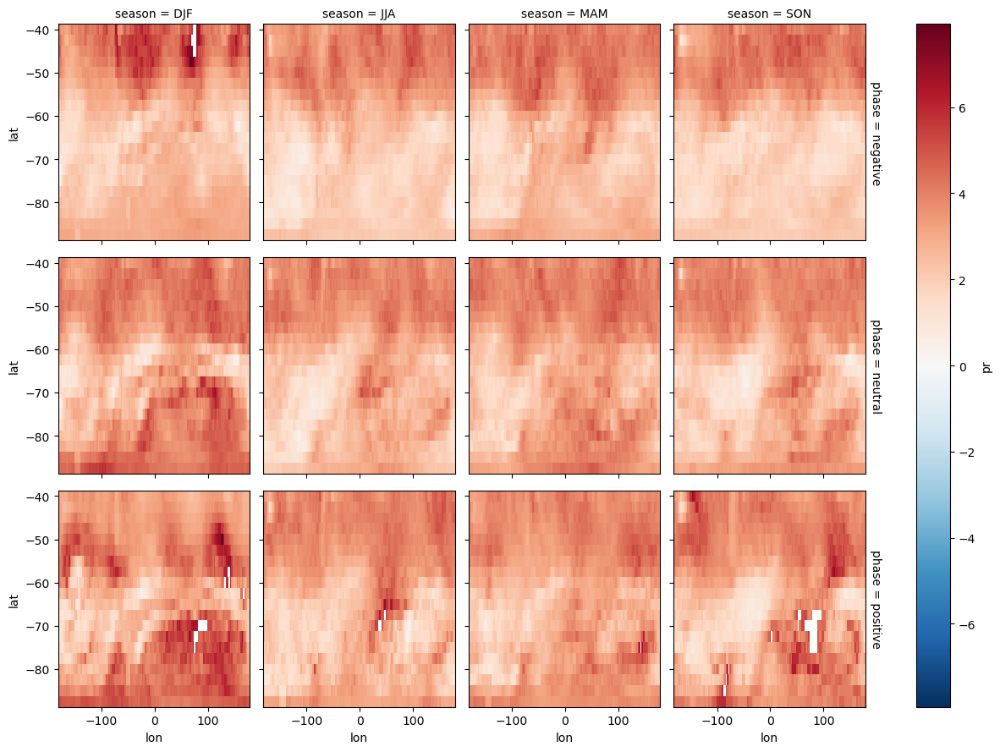

In [346]:
#(t): Quick look: DEMO_MODEL's warm ratio in each phase, log2, DEMO_EXPERIMENT
np.log2(sam_pr_ds['pr'].sel(model=DEMO_MODEL, experiment=DEMO_EXPERIMENT, tail='warm', chance=CHANCES[0])).plot(
    x='lon', y='lat', row='phase', col='season', cmap='RdBu_r', center=0);

## 11. Shift-Only Ratio

A probability ratio above 1 can come from the whole distribution moving warmer (the mean shifting), from it getting wider or narrower, or from both. The **shift-only ratio** is the ratio the shift alone would give. hist-nat's own seasons are each moved by the experiment's change in the mean, $\Delta = \bar{x}^{\mathrm{exp}} - \bar{x}^{\mathrm{nat}}$ (both over the final $L$ years), and counted against section 10's thresholds:

$$
P^{\text{shift only}}_{\mathrm{exp}} = P\left(x^{\mathrm{nat}} + \Delta > T\right) = P\left(x^{\mathrm{nat}} > T - \Delta\right),
\qquad
\mathrm{PR}^{\text{shift only}} = \frac{P^{\text{shift only}}_{\mathrm{exp}}}{P_{\mathrm{nat}}}.
$$

Moving every season up by $\Delta$ is the same as moving the threshold down by $\Delta$, and that is how it is calculated: hist-nat's seasons against the **moved thresholds** $T - \Delta$ (`pr_shift_only_thresholds_ds`), one set for each experiment.

**An example.** hist-nat goes above its warm threshold 5% of the time and hist-GHG 15%, so PR = 3. hist-nat's seasons moved up by hist-GHG's warming go above it 12% of the time, so the shift-only ratio is 2.4. The warming alone gives most of the 3; the rest comes from hist-GHG's distribution also getting wider. A ratio below its shift-only ratio means a narrowing held it back, which matters most for cold seasons.

**Uncertainty.** The bootstrap of section 10. The shift-only chance and hist-nat's own chance are both made from hist-nat's members, so they are resampled with the same draws (the same seed, 0), and their ratio keeps its pairing.

### At the demonstration point

In [347]:
#(t): The change in the mean at the point: the experiment's final-years mean minus hist-nat's
demo_shift_da = demo_experiment_final_da.mean() - demo_histnat_final_da.mean()

<xarray.DataArray 'tas' ()> Size: 4B
0.9505
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

In [348]:
#(t): hist-nat's thresholds moved down by it: hist-nat's seasons beyond these are the seasons the experiment
#(t): would have beyond the real thresholds, had its distribution only shifted
demo_shift_only_thresholds_da = demo_thresholds_da - demo_shift_da

<xarray.DataArray 'tas' (tail: 2, chance: 2)> Size: 32B
-3.123 -3.629 -8.234 -7.853
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * tail     (tail) <U4 32B 'warm' 'cold'
  * chance   (chance) float64 16B 0.05 0.1

In [349]:
#(t): The share of each hist-nat member's years beyond the moved thresholds
demo_shift_only_exceedance_da = pr.member_exceedance(demo_histnat_final_da, demo_shift_only_thresholds_da)

<xarray.DataArray (tail: 2, member: 50, chance: 2)> Size: 2kB
0.1905 0.2857 0.2381 0.2381 0.09524 0.09524 ... 0.0 0.0 0.0 0.09524 0.0 0.04762
Coordinates:
  * tail     (tail) <U4 32B 'warm' 'cold'
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
  * chance   (chance) float64 16B 0.05 0.1

In [350]:
#(t): averaged over the members: the shift-only chance
demo_p_shift_only_da = demo_shift_only_exceedance_da.mean('member')

<xarray.DataArray (tail: 2, chance: 2)> Size: 32B
0.1495 0.2057 0.002857 0.01333
Coordinates:
  * tail     (tail) <U4 32B 'warm' 'cold'
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * chance   (chance) float64 16B 0.05 0.1

In [351]:
#(t): The shift-only ratio: against hist-nat's own chance (section 10)
demo_pr_shift_only_da = demo_p_shift_only_da / demo_p_histnat_da
demo_pr_shift_only_da

<xarray.DataArray (tail: 2, chance: 2)> Size: 32B
2.962 2.057 0.0566 0.1333
Coordinates:
  * tail     (tail) <U4 32B 'warm' 'cold'
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * chance   (chance) float64 16B 0.05 0.1

In [352]:
#(t): The numbers side by side, with section 10's
pd.DataFrame({
    'P hist-nat': demo_p_histnat_da.to_series(),
    'P hist-nat, shifted': demo_p_shift_only_da.to_series(),
    f'P {DEMO_EXPERIMENT}': demo_p_experiment_da.to_series(),
    'PR, shift only': demo_pr_shift_only_da.to_series(),
    'PR': demo_pr_da.to_series(),
}).round(3)

P hist-nat  P hist-nat, shifted  P historical  PR, shift only  \
tail chance                                                                  
warm 0.05          0.05                0.150         0.123           2.962   
     0.10          0.10                0.206         0.204           2.057   
cold 0.05          0.05                0.003         0.001           0.057   
     0.10          0.10                0.013         0.006           0.133   

                PR  
tail chance         
warm 0.05    2.438  
     0.10    2.037  
cold 0.05    0.029  
     0.10    0.059

In [353]:
#(t): The bootstrap: hist-nat's shift-only shares, with the same draws of hist-nat's members as its own chance
#(t): (seed 0)
demo_p_shift_only_trials_da = pr.bootstrap_member_mean(demo_shift_only_exceedance_da, n_trials=DEMO_TRIALS, seed=0)

In [354]:
#(t): Every trial's shift-only ratio
demo_shift_only_trials_da = demo_p_shift_only_trials_da / demo_p_histnat_trials_da

<xarray.DataArray (trial: 10000, tail: 2, chance: 2)> Size: 320kB
2.967 2.167 0.1282 0.117 3.083 2.292 ... 0.04 0.1364 2.639 1.867 0.1064 0.1546
Coordinates:
  * tail     (tail) <U4 32B 'warm' 'cold'
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * chance   (chance) float64 16B 0.05 0.1
  * trial    (trial) int64 80kB 0 1 2 3 4 5 6 ... 9994 9995 9996 9997 9998 9999

In [355]:
#(t): Its central 1 - ALPHA
demo_shift_only_bounds_da = demo_shift_only_trials_da.quantile([ALPHA / 2, 1 - ALPHA / 2], dim='trial')
demo_shift_only_bounds_da.to_series().unstack('quantile').round(2)

quantile     0.025  0.975
tail chance              
warm 0.05     2.41   3.78
     0.10     1.80   2.40
cold 0.05     0.00   0.12
     0.10     0.07   0.20

In [356]:
#(t): hist-nat's seasons, every one moved by the shift: what the moved thresholds stand in for
demo_histnat_shifted_da = demo_histnat_final_da + demo_shift_da
demo_histnat_shifted_da

In [ ]:
#(t): The shift-only ratio, step by step: a) hist-nat's seasons, every one moved by the change in the mean, against
#(t): the experiment itself and hist-nat's thresholds; b) the bootstrap's ratios, both, each tail
warm_percentile, cold_percentile = methods.percentile_words(CHANCES[0])
#(c): In the slides' big text, as the schematics are shown in talks too
with plt.rc_context(fr.SLIDES.rc):
    fig = plt.figure(figsize=(11, 8.5))
    ax_a, flow_axes, _, ax_b = methods.schematic_axes(fig, with_trials=False)
    methods.plot_shift_only(demo_experiment_final_da, demo_histnat_final_da, demo_thresholds_da.sel(chance=CHANCES[0]),
                            demo_shift_da, DEMO_EXPERIMENT, units=VARIABLE.units, ax=ax_a)
    ax_a.set_title(f"a  The shift of the mean alone, and everything (dashed: hist-nat's {cold_percentile} and "
                   f"{warm_percentile} percentiles)", pad=10)
    ax_a.set_xlabel(VARIABLE.units)
    ax_a.set_ylabel('Density')
    methods.plot_flow(f"Resample whole members with replacement, {demo_shift_only_trials_da.sizes['trial']:,} times\n"
                      "(hist-nat's own and its moved seasons with the same draws), and recalculate both ratios",
                      flow_axes[0])
    methods.plot_ratio_trials(demo_pr_trials_da.sel(chance=CHANCES[0]), 'probability ratio', ax=ax_b, alpha=0.45,
                              histtype='stepfilled')
    methods.plot_ratio_trials(demo_shift_only_trials_da.sel(chance=CHANCES[0]), 'shift only', ax=ax_b,
                              histtype='step', lw=1.6, ls='--')
    ax_b.set_title('b  Bootstrap of the two ratios', pad=10)
    ax_b.set_xlabel('Probability ratio (log scale; 0 and beyond 64 at the ends)')
    ax_b.set_ylabel('Density');

### Everywhere

The same steps at every grid point, against section 10's thresholds (`pr_thresholds_ds`) and hist-nat's own chances and bootstrap (`pr_p_counterfactual_ds`, `pr_p_counterfactual_trials_ds`).

In [359]:
#(t): The change in the mean of every experiment, from section 4's final-years means (0 for hist-nat)
pr_shift_ds = final_mean_ds - final_mean_ds.sel(experiment='hist-nat')

<xarray.Dataset> Size: 1MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
Data variables:
    tas         (lat, lon, season, model, experiment) float32 1MB 2.339 ... 0...

In [360]:
#(t): hist-nat's thresholds moved down by it, one set per experiment
pr_shift_only_thresholds_ds = pr_thresholds_ds - pr_shift_ds

<xarray.Dataset> Size: 11MB
Dimensions:     (model: 6, lon: 144, lat: 20, season: 4, tail: 2, chance: 2,
                 experiment: 5)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
Data variables:
    tas         (lat, lon, season, tail, chance, model, experiment) float64 11MB ...

In [361]:
#(t): As a tree shaped like lesfmip_final_tree
pr_shift_only_thresholds_tree = datatree.dataset_to_tree(pr_shift_only_thresholds_ds, like=lesfmip_final_tree)

In [362]:
#(t): hist-nat's members (hist_nat_final_tree: section 4) against each experiment's moved thresholds
pr_shift_only_exceedance_tree = xr.map_over_datasets(pr.member_exceedance, hist_nat_final_tree,
                                                     pr_shift_only_thresholds_tree)

In [363]:
%%time
#(t): The shift-only chances, averaged over hist-nat's members
pr_p_shift_only_ds = datatree.reduce_to_dataset(pr_shift_only_exceedance_tree, lambda ds: ds.mean('member')).compute()

CPU times: user 111 ms, sys: 13.9 ms, total: 125 ms
Wall time: 2.43 s


<xarray.Dataset> Size: 11MB
Dimensions:     (model: 6, experiment: 5, lon: 144, lat: 20, season: 4,
                 tail: 2, chance: 2)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
Data variables:
    tas         (tail, lat, lon, season, chance, model, experiment) float64 11MB ...

In [364]:
#(t): The shift-only ratios: against hist-nat's own chance (section 10)
pr_ratio_shift_only_ds = (pr_p_shift_only_ds / pr_p_counterfactual_ds).drop_sel(experiment='hist-nat')

<xarray.Dataset> Size: 9MB
Dimensions:     (model: 6, experiment: 4, lon: 144, lat: 20, season: 4,
                 tail: 2, chance: 2)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
Data variables:
    tas         (tail, lat, lon, season, chance, model, experiment) float64 9MB ...

In [365]:
#(t): The bootstrap: hist-nat's shift-only shares, with the same draws as its own chance (seed 0)
pr_p_shift_only_trials_ds = datatree.reduce_to_dataset(
    pr_shift_only_exceedance_tree, partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=0),
)

In [366]:
#(t): Every trial's shift-only ratio (lazy: only its quantiles are computed)
pr_shift_only_trials_ds = pr_p_shift_only_trials_ds / pr_p_counterfactual_trials_ds
pr_shift_only_trials_da = pr_shift_only_trials_ds[VARIABLE.name].drop_sel(experiment='hist-nat')

<xarray.DataArray 'tas' (trial: 1000, tail: 2, lat: 20, lon: 144, season: 4,
                         chance: 2, model: 6, experiment: 4)> Size: 9GB
dask.array<chunksize=(1000, 2, 4, 144, 4, 2, 1, 1), meta=np.ndarray>
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
  * trial       (trial) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999

In [367]:
%%time
#(t): Its central 1 - ALPHA
pr_shift_only_bounds_da = nan_quantile(pr_shift_only_trials_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial').compute()

CPU times: user 42.7 ms, sys: 15.7 ms, total: 58.4 ms
Wall time: 7.24 s


<xarray.DataArray 'tas' (tail: 2, lat: 20, lon: 144, season: 4, chance: 2,
                         model: 6, experiment: 4, quantile: 2)> Size: 18MB
12.4 24.33 0.2092 0.3913 1.268 1.706 ... 1.063 1.362 1.262 1.742 0.09373 0.2632
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
  * quantile    (quantile) float64 16B 0.025 0.975

In [368]:
#(t): The shift-only ratios in one Dataset, laid out as notebook plot_06 opens it
pr_shift_only_ds = xr.Dataset({
    'shift': pr_shift_ds[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'p_shift_only': pr_p_shift_only_ds[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'pr_shift_only': pr_ratio_shift_only_ds[VARIABLE.name],
    'pr_shift_only_lower': pr_shift_only_bounds_da.isel(quantile=0, drop=True),
    'pr_shift_only_upper': pr_shift_only_bounds_da.isel(quantile=1, drop=True),
})
pr_shift_only_ds

<xarray.Dataset> Size: 36MB
Dimensions:              (model: 6, experiment: 4, season: 4, lat: 20,
                          lon: 144, tail: 2, chance: 2)
Coordinates:
  * model                (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * experiment           (experiment) object 32B 'hist-GHG' ... 'historical'
  * season               (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat                  (lat) float64 160B -87.5 -85.0 -82.5 ... -42.5 -40.0
  * lon                  (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * tail                 (tail) <U4 32B 'warm' 'cold'
  * chance               (chance) float64 16B 0.05 0.1
Data variables:
    shift                (lat, lon, season, model, experiment) float32 1MB 2....
    p_shift_only         (tail, lat, lon, season, chance, model, experiment) float64 9MB ...
    pr_shift_only        (tail, lat, lon, season, chance, model, experiment) float64 9MB ...
    pr_shift_only_lower  (tail, lat, lon, season, chance, model, experiment) float64 9MB ...
    pr_shift_only_upper  (tail, lat, lon, season, chance, model, experiment) float64 9MB ...

In [369]:
#(t): Saved for notebooks plot_03 to plot_06
probability_ratio_shift_only_path = RESULTS_DIR / 'probability_ratio_shift_only.zarr'
pr_shift_only_ds.to_zarr(probability_ratio_shift_only_path, mode='w')
probability_ratio_shift_only_path

17:43:38 INFO    extant.storage | writing Dataset (model: 6, experiment: 4, season: 4, lat: 20, lon: 144, tail: 2, chance: 2) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/probability_ratio_shift_only.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `<U4` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by

17:43:41 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/probability_ratio_shift_only.zarr


PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/probability_ratio_shift_only.zarr')

In [370]:
#(t): Its value at the demonstration point: the same ratios as step by step above (the bounds from fewer trials)
pr_shift_only_ds[['pr_shift_only', 'pr_shift_only_lower', 'pr_shift_only_upper']].sel(
    **DEMO_SEL, experiment=DEMO_EXPERIMENT).sel(**DEMO_LATLON).to_dataframe().round(2)

pr_shift_only  pr_shift_only_lower  pr_shift_only_upper    model  \
tail chance                                                                     
warm 0.05             2.96                 2.40                 3.79  CanESM5   
     0.10             2.06                 1.81                 2.41  CanESM5   
cold 0.05             0.06                 0.00                 0.13  CanESM5   
     0.10             0.13                 0.07                 0.20  CanESM5   

             experiment season   lat    lon  
tail chance                                  
warm 0.05    historical    DJF -75.0 -180.0  
     0.10    historical    DJF -75.0 -180.0  
cold 0.05    historical    DJF -75.0 -180.0  
     0.10    historical    DJF -75.0 -180.0

/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/xarray/computation/apply_ufunc.py:813: RuntimeWarning: divide by zero encountered in log2
  result_data = func(*input_data)


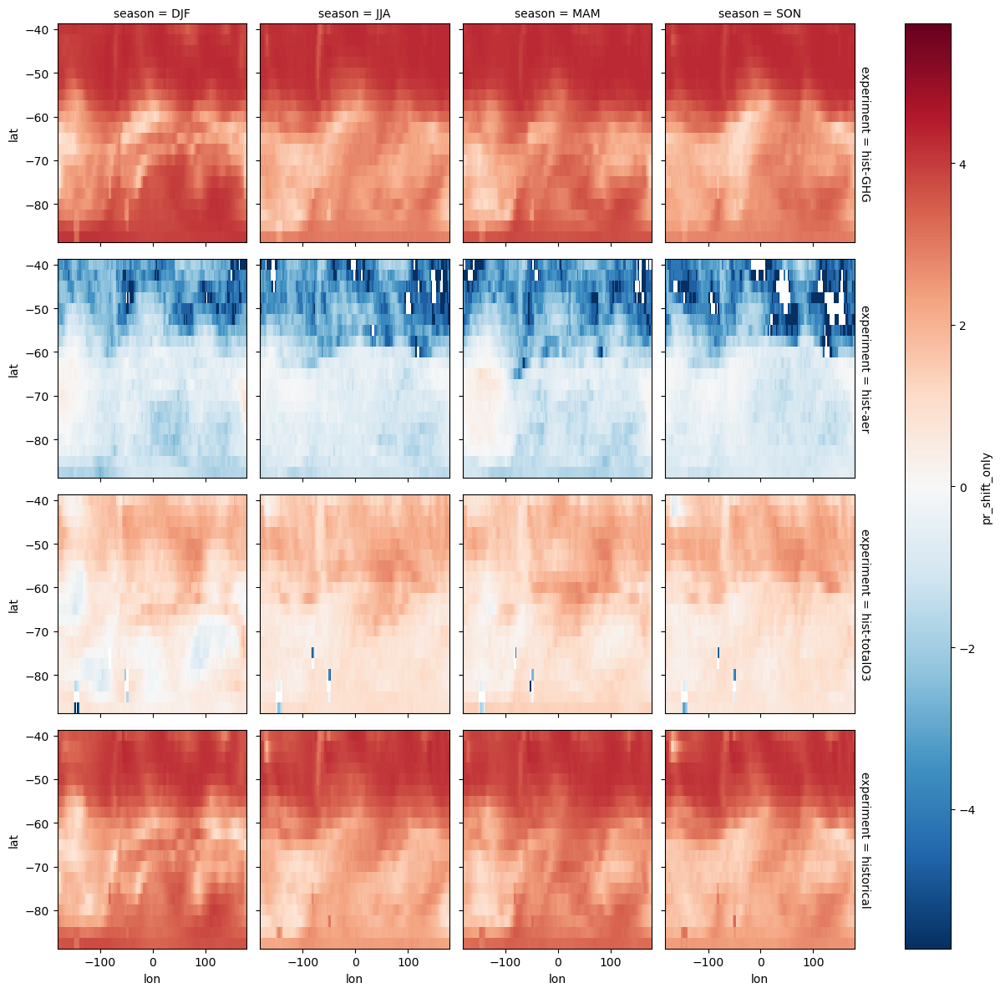

In [371]:
#(t): Quick look: DEMO_MODEL's warm shift-only ratio, log2, experiments down and seasons across
np.log2(pr_shift_only_ds['pr_shift_only'].sel(model=DEMO_MODEL, tail='warm', chance=CHANCES[0])).plot(
    x='lon', y='lat', row='experiment', col='season', cmap='RdBu_r', center=0);

### For the regional means

The same steps on the regional means, against section 10's regional thresholds (`regional_thresholds_ds`).

In [372]:
#(t): Every experiment's final-years ensemble mean in each region
regional_final_mean_ds = datatree.reduce_to_dataset(regional_final_tree, lambda ds: ds.mean(['member', 'year']))

<xarray.Dataset> Size: 3kB
Dimensions:     (model: 6, experiment: 5, region: 3, season: 4)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * region      (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean...
Data variables:
    tas         (region, season, model, experiment) float64 3kB -11.83 ... 1.895

In [373]:
#(t): The change in each region's mean (0 for hist-nat)
regional_shift_ds = regional_final_mean_ds - regional_final_mean_ds.sel(experiment='hist-nat')

In [374]:
#(t): The regional thresholds (section 10) moved down by it
regional_shift_only_thresholds_ds = regional_thresholds_ds - regional_shift_ds

In [375]:
#(t): As a tree shaped like regional_final_tree
regional_shift_only_thresholds_tree = datatree.dataset_to_tree(regional_shift_only_thresholds_ds,
                                                               like=regional_final_tree)

In [376]:
#(t): Each experiment's model's hist-nat, in a tree shaped like regional_final_tree
regional_hist_nat_final_tree = datatree.hist_nat_like(regional_final_tree)

In [377]:
#(t): hist-nat's members against each experiment's moved thresholds: the shift-only shares
regional_shift_only_exceedance_tree = xr.map_over_datasets(pr.member_exceedance, regional_hist_nat_final_tree,
                                                           regional_shift_only_thresholds_tree)

In [378]:
#(t): The shift-only chances
regional_p_shift_only_ds = datatree.reduce_to_dataset(regional_shift_only_exceedance_tree,
                                                      lambda ds: ds.mean('member'))

In [379]:
#(t): The shift-only ratios: against hist-nat's own chance (section 10)
regional_pr_shift_only_ds = (regional_p_shift_only_ds / regional_p_counterfactual_ds).drop_sel(
    experiment='hist-nat')

In [380]:
#(t): The bootstrap: hist-nat's shift-only shares with the same draws as its own chance (seed 0)
regional_p_shift_only_trials_ds = datatree.reduce_to_dataset(
    regional_shift_only_exceedance_tree, partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=0))

In [381]:
#(t): Every trial's shift-only ratio
regional_shift_only_trials_ds = regional_p_shift_only_trials_ds / regional_p_counterfactual_trials_ds
regional_shift_only_trials_da = regional_shift_only_trials_ds[VARIABLE.name].drop_sel(experiment='hist-nat')

<xarray.DataArray 'tas' (trial: 1000, tail: 2, region: 3, season: 4, chance: 2,
                         model: 6, experiment: 4)> Size: 9MB
14.55 0.303 1.182 11.89 9.333 1.125 ... 0.1356 0.0 0.04651 7.209 1.116 0.04651
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * region      (region) <U24 288B 'Antarctica (90–65°S)' ... 'Southern Ocean...
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
  * trial       (trial) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999

In [382]:
#(t): Its central 1 - ALPHA
regional_shift_only_bounds_da = nan_quantile(regional_shift_only_trials_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial')

In [383]:
#(t): The regional shift-only ratios in one Dataset, laid out as notebook plot_06 opens it
regional_shift_only_ds = xr.Dataset({
    'shift': regional_shift_ds[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'p_shift_only': regional_p_shift_only_ds[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'pr_shift_only': regional_pr_shift_only_ds[VARIABLE.name],
    'pr_shift_only_lower': regional_shift_only_bounds_da.isel(quantile=0, drop=True),
    'pr_shift_only_upper': regional_shift_only_bounds_da.isel(quantile=1, drop=True),
})
regional_shift_only_ds

<xarray.Dataset> Size: 40kB
Dimensions:              (model: 6, experiment: 4, season: 4, region: 3,
                          tail: 2, chance: 2)
Coordinates:
  * model                (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * experiment           (experiment) object 32B 'hist-GHG' ... 'historical'
  * season               (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * region               (region) <U24 288B 'Antarctica (90–65°S)' ... 'South...
  * tail                 (tail) <U4 32B 'warm' 'cold'
  * chance               (chance) float64 16B 0.05 0.1
Data variables:
    shift                (region, season, model, experiment) float64 2kB 1.41...
    p_shift_only         (tail, region, season, chance, model, experiment) float64 9kB ...
    pr_shift_only        (tail, region, season, chance, model, experiment) float64 9kB ...
    pr_shift_only_lower  (tail, region, season, chance, model, experiment) float64 9kB ...
    pr_shift_only_upper  (tail, region, season, chance, model, experiment) float64 9kB ...

In [384]:
#(t): Saved for notebooks plot_03 to plot_06
probability_ratio_shift_only_regional_path = RESULTS_DIR / 'probability_ratio_shift_only_regional.zarr'
regional_shift_only_ds.to_zarr(probability_ratio_shift_only_regional_path, mode='w')
probability_ratio_shift_only_regional_path

17:43:43 INFO    extant.storage | writing Dataset (model: 6, experiment: 4, season: 4, region: 3, tail: 2, chance: 2) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/probability_ratio_shift_only_regional.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:43:44 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/probability_ratio_shift_only_regional.zarr


PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/probability_ratio_shift_only_regional.zarr')

In [385]:
#(t): The numbers for the first region, hist-nat's chance CHANCES[0], next to section 10's ratios
xr.merge([regional_pr_ds[['pr']], regional_shift_only_ds[['pr_shift_only']]]).sel(
    region=list(REGIONS)[0], chance=CHANCES[0]).to_dataframe().unstack('season').round(2)

pr                       \
season                               DJF    JJA    MAM    SON   
tail model           experiment                                 
warm CanESM5         hist-GHG      18.38  14.87  18.51  14.74   
                     hist-aer       0.13   0.25   0.50   0.28   
                     hist-totalO3   1.13   2.74   3.58   2.55   
                     historical    14.57  11.97  17.39  11.29   
     GISS-E2-1-G     hist-GHG      11.17  10.75  11.81  10.16   
                     hist-aer       1.21   1.21   1.48   1.35   
                     hist-totalO3   1.31   3.43   1.81   2.81   
                     historical     5.17   6.05   6.67   6.50   
     HadGEM3-GC31-LL hist-GHG      11.38  11.43  14.42  10.63   
                     hist-aer       2.75   4.74   4.62   4.43   
                     hist-totalO3   0.59   0.93   1.07   1.31   
                     historical     3.90   3.36   5.09   4.71   
     MIROC6          hist-GHG       6.13   4.83   4.58   3.42   
                     hist-aer       0.28   0.09   0.47   0.85   
                     hist-totalO3   0.09   0.57   0.28   0.47   
                     historical     4.75   4.23   4.45   3.58   
     MPI-ESM1-2-LR   hist-GHG      12.19   9.56  13.28   9.50   
                     hist-aer       0.97   0.69   1.03   0.91   
                     hist-totalO3   1.97   2.47   2.06   3.03   
                     historical    10.07  10.00  11.12   9.76   
     NorESM2-LM      hist-GHG       3.40   2.68   4.40   3.32   
                     hist-aer       0.64   0.24   0.04   0.28   
                     hist-totalO3   0.32   1.20   0.87   0.64   
                     historical     2.01   3.25   3.57   3.57   
cold CanESM5         hist-GHG       0.00   0.00   0.00   0.00   
                     hist-aer       2.92   2.20   2.58   2.67   
                     hist-totalO3   0.47   0.00   0.00   0.19   
                     historical     0.00   0.03   0.00   0.00   
     GISS-E2-1-G     hist-GHG       0.00   0.02   0.00   0.00   
                     hist-aer       1.88   1.97   1.80   1.16   
                     hist-totalO3   1.19   0.36   0.67   0.17   
                     historical     5.71   5.73   5.74   5.74   
     HadGEM3-GC31-LL hist-GHG       0.00   0.00   0.00   0.00   
                     hist-aer       1.37   1.16   1.00   0.81   
                     hist-totalO3   1.85   1.18   1.18   0.59   
                     historical     0.07   0.07   0.00   0.00   
     MIROC6          hist-GHG       0.04   0.21   0.04   0.34   
                     hist-aer       2.36   2.26   1.60   1.89   
                     hist-totalO3   3.30   0.85   1.42   2.17   
                     historical     0.13   0.21   0.23   0.26   
     MPI-ESM1-2-LR   hist-GHG       0.00   0.00   0.00   0.00   
                     hist-aer       1.06   1.53   1.03   0.91   
                     hist-totalO3   0.22   0.34   0.41   0.19   
                     historical     0.00   0.00   0.02   0.00   
     NorESM2-LM      hist-GHG       0.00   0.24   0.04   0.08   
                     hist-aer       2.96   3.48   4.72   3.08   
                     hist-totalO3   2.62   0.87   1.38   1.01   
                     historical     0.09   0.06   0.02   0.09   

                                                 region                        \
season                                              DJF                   JJA   
tail model           experiment                                                 
warm CanESM5         hist-GHG      Antarctica (90–65°S)  Antarctica (90–65°S)   
                     hist-aer      Antarctica (90–65°S)  Antarctica (90–65°S)   
                     hist-totalO3  Antarctica (90–65°S)  Antarctica (90–65°S)   
                     historical    Antarctica (90–65°S)  Antarctica (90–65°S)   
     GISS-E2-1-G     hist-GHG      Antarctica (90–65°S)  Antarctica (90–65°S)   
                     hist-aer      Antarctica (90–65°S)  Antarctica (90–65

### By SAM phase

The shift-only ratio in each SAM phase: hist-nat's seasons in the phase, each moved by the change in the mean in that phase (section 4, *By SAM phase*), against the same thresholds, pooled as in section 10's SAM subsection and over hist-nat's own chance in the phase. Where the probability ratio in a phase is bigger than its shift-only ratio, the width or shape in that phase has made the event more likely still.

In [386]:
#(t): The change in the mean in each phase (section 4, by SAM phase), 0 for hist-nat
pr_phase_shift_ds = phase_mean_ds - phase_mean_ds.sel(experiment='hist-nat')

<xarray.Dataset> Size: 4MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144, phase: 3)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
Data variables:
    tas         (lat, lon, season, phase, model, experiment) float32 4MB 2.42...

In [387]:
#(t): hist-nat's thresholds moved down by it, one set per experiment and phase
pr_phase_shift_only_thresholds_ds = pr_thresholds_ds - pr_phase_shift_ds

<xarray.Dataset> Size: 33MB
Dimensions:     (model: 6, lon: 144, lat: 20, season: 4, tail: 2, chance: 2,
                 experiment: 5, phase: 3)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
Data variables:
    tas         (lat, lon, season, tail, chance, model, phase, experiment) float64 33MB ...

In [388]:
#(t): As a tree shaped like lesfmip_phase_tree
pr_phase_shift_only_thresholds_tree = datatree.dataset_to_tree(pr_phase_shift_only_thresholds_ds,
                                                               like=lesfmip_phase_tree)

In [389]:
#(t): Each experiment's model's hist-nat in each phase, in a tree shaped like lesfmip_phase_tree
hist_nat_phase_tree = datatree.hist_nat_like(lesfmip_phase_tree)

In [390]:
#(t): How many of hist-nat's seasons in each phase are beyond each experiment's moved thresholds, member by member
pr_phase_shift_only_beyond_tree = xr.map_over_datasets(pr.member_beyond, hist_nat_phase_tree,
                                                       pr_phase_shift_only_thresholds_tree)

In [391]:
%%time
#(t): Added up over hist-nat's members
pr_phase_shift_only_beyond_ds = datatree.reduce_to_dataset(pr_phase_shift_only_beyond_tree,
                                                           lambda ds: ds.sum('member')).compute()

CPU times: user 208 ms, sys: 112 ms, total: 320 ms
Wall time: 9.33 s


<xarray.Dataset> Size: 33MB
Dimensions:     (model: 6, experiment: 5, lon: 144, lat: 20, season: 4,
                 phase: 3, tail: 2, chance: 2)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
Data variables:
    tas         (tail, lat, lon, season, phase, chance, model, experiment) float64 33MB ...

In [392]:
#(t): The shift-only chances: over all of hist-nat's seasons in the phase (section 10, by SAM phase)
pr_phase_p_shift_only_ds = pr_phase_shift_only_beyond_ds / pr_phase_count_ds.sel(experiment='hist-nat', drop=True)

<xarray.Dataset> Size: 33MB
Dimensions:     (model: 6, experiment: 5, lon: 144, lat: 20, season: 4,
                 phase: 3, tail: 2, chance: 2)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
Data variables:
    tas         (tail, lat, lon, season, phase, chance, model, experiment) float64 33MB ...

In [393]:
#(t): The shift-only ratios: against hist-nat's own chance in the phase
pr_phase_ratio_shift_only_ds = (pr_phase_p_shift_only_ds / pr_phase_p_counterfactual_ds).drop_sel(experiment='hist-nat')

<xarray.Dataset> Size: 27MB
Dimensions:     (model: 6, experiment: 4, lon: 144, lat: 20, season: 4,
                 phase: 3, tail: 2, chance: 2)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
Data variables:
    tas         (tail, lat, lon, season, phase, chance, model, experiment) float64 27MB ...

In [394]:
#(t): The bootstrap: hist-nat's counts beyond the moved thresholds, with the same draws as its own chance (seed 0)
pr_phase_shift_only_beyond_trials_ds = datatree.reduce_to_dataset(
    pr_phase_shift_only_beyond_tree, partial(pr.bootstrap_member_mean, n_trials=PR_TRIALS, seed=0),
)

In [395]:
#(t): Every trial's shift-only chance, over the same trial's count of hist-nat's seasons in the phase
pr_phase_p_shift_only_trials_ds = pr_phase_shift_only_beyond_trials_ds / pr_phase_count_counterfactual_trials_ds

In [396]:
#(t): Every trial's shift-only ratio (lazy: only its quantiles are computed)
pr_phase_shift_only_trials_ds = pr_phase_p_shift_only_trials_ds / pr_phase_p_counterfactual_trials_ds
pr_phase_shift_only_trials_da = pr_phase_shift_only_trials_ds[VARIABLE.name].drop_sel(experiment='hist-nat')

<xarray.DataArray 'tas' (trial: 1000, tail: 2, lat: 20, lon: 144, season: 4,
                         phase: 3, chance: 2, model: 6, experiment: 4)> Size: 27GB
dask.array<chunksize=(1000, 2, 4, 144, 4, 3, 2, 1, 1), meta=np.ndarray>
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
  * trial       (trial) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999

In [397]:
%%time
#(t): Its central 1 - ALPHA
pr_phase_shift_only_bounds_da = nan_quantile(pr_phase_shift_only_trials_da, [ALPHA / 2, 1 - ALPHA / 2],
                                             'trial').compute()

CPU times: user 68.3 ms, sys: 157 ms, total: 225 ms
Wall time: 20.3 s


<xarray.DataArray 'tas' (tail: 2, lat: 20, lon: 144, season: 4, phase: 3,
                         chance: 2, model: 6, experiment: 4, quantile: 2)> Size: 53MB
6.481 13.96 0.2 0.5 1.325 2.091 5.792 ... 0.0 1.0 1.5 1.19 2.111 0.0 0.2857
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
  * tail        (tail) <U4 32B 'warm' 'cold'
  * chance      (chance) float64 16B 0.05 0.1
  * quantile    (quantile) float64 16B 0.025 0.975

In [398]:
#(t): The shift-only ratios by SAM phase in one Dataset, laid out as pr_shift_only_ds with a phase dim
sam_pr_shift_only_ds = xr.Dataset({
    'shift': pr_phase_shift_ds[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'p_shift_only': pr_phase_p_shift_only_ds[VARIABLE.name].drop_sel(experiment='hist-nat'),
    'pr_shift_only': pr_phase_ratio_shift_only_ds[VARIABLE.name],
    'pr_shift_only_lower': pr_phase_shift_only_bounds_da.isel(quantile=0, drop=True),
    'pr_shift_only_upper': pr_phase_shift_only_bounds_da.isel(quantile=1, drop=True),
})
sam_pr_shift_only_ds

<xarray.Dataset> Size: 109MB
Dimensions:              (model: 6, experiment: 4, season: 4, lat: 20,
                          lon: 144, phase: 3, tail: 2, chance: 2)
Coordinates:
  * model                (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * experiment           (experiment) object 32B 'hist-GHG' ... 'historical'
  * season               (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat                  (lat) float64 160B -87.5 -85.0 -82.5 ... -42.5 -40.0
  * lon                  (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * phase                (phase) <U8 96B 'negative' 'neutral' 'positive'
  * tail                 (tail) <U4 32B 'warm' 'cold'
  * chance               (chance) float64 16B 0.05 0.1
Data variables:
    shift                (lat, lon, season, phase, model, experiment) float32 3MB ...
    p_shift_only         (tail, lat, lon, season, phase, chance, model, experiment) float64 27MB ...
    pr_shift_only        (tail, lat, lon, season, phase, chance, model, experiment) float64 27MB ...
    pr_shift_only_lower  (tail, lat, lon, season, phase, chance, model, experiment) float64 27MB ...
    pr_shift_only_upper  (tail, lat, lon, season, phase, chance, model, experiment) float64 27MB ...

In [399]:
#(t): Saved for notebooks plot_03 to plot_06
sam_probability_ratio_shift_only_path = RESULTS_DIR / 'sam_probability_ratio_shift_only.zarr'
sam_pr_shift_only_ds.to_zarr(sam_probability_ratio_shift_only_path, mode='w')
sam_probability_ratio_shift_only_path

17:44:18 INFO    extant.storage | writing Dataset (model: 6, experiment: 4, season: 4, lat: 20, lon: 144, phase: 3, tail: 2, chance: 2) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_probability_ratio_shift_only.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `<U4` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by

17:44:21 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_probability_ratio_shift_only.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_probability_ratio_shift_only.zarr')

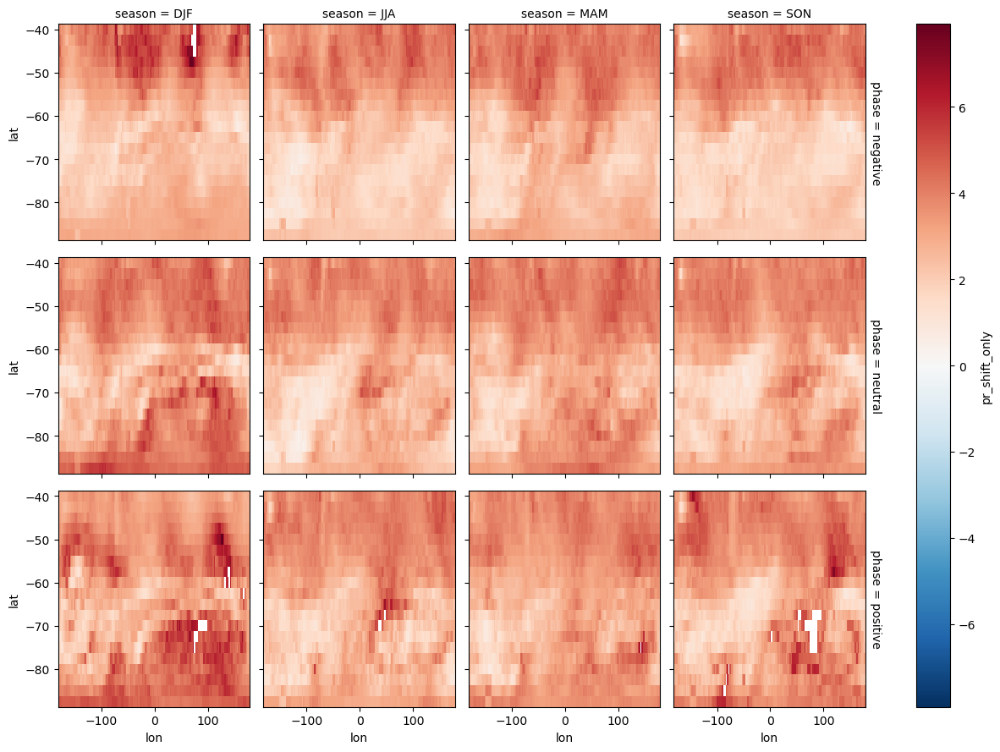

In [400]:
#(t): Quick look: DEMO_MODEL's warm shift-only ratio in each phase, log2, DEMO_EXPERIMENT
np.log2(sam_pr_shift_only_ds['pr_shift_only'].sel(model=DEMO_MODEL, experiment=DEMO_EXPERIMENT, tail='warm',
                                                  chance=CHANCES[0])).plot(
    x='lon', y='lat', row='phase', col='season', cmap='RdBu_r', center=0);

## 12. Additivity of the Width (on the Variance)

Section 6 checks whether the single forcings' changes in the mean add up to historical's. Widths do not add up, but variances do, if the forcings' contributions are independent: the variance of a sum of independent parts is the sum of their variances. So the additivity of the variability is tested on the variance of the internal variability (`qrange_tree`, section 2), each experiment's change from its own 1850–1900 baseline as in section 6, members and years pooled:

$$
\Delta\sigma^2_e = \sigma^2\left(x'^{\,e}_{\text{final } L \text{ years}}\right) - \sigma^2\left(x'^{\,e}_{1850\text{–}1900}\right),
\qquad
\text{residual} = \Delta\sigma^2_{\mathrm{historical}} - \left(\Delta\sigma^2_{\mathrm{nat}} + \Delta\sigma^2_{\mathrm{GHG}} + \Delta\sigma^2_{\mathrm{aer}} + \Delta\sigma^2_{\mathrm{O_3}}\right).
$$

The residual mixes three things: interaction between the forcings, forcings the four leave out (land use), and sampling noise from the ensembles' sizes.

In [401]:
#(t): The internal variability of every experiment over its own 1850-1900 baseline (qrange_tree: section 2)
internal_baseline_tree = qrange_tree.sel(year=slice(1850, 1900))

In [402]:
%%time
#(t): Its variance, members and years pooled
baseline_variance_ds = datatree.reduce_to_dataset(internal_baseline_tree,
                                                  lambda ds: ds.var(['member', 'year'], ddof=1)).compute()

CPU times: user 89.3 ms, sys: 5.56 ms, total: 94.9 ms
Wall time: 4.53 s


<xarray.Dataset> Size: 3MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
Data variables:
    tas         (lat, lon, season, model, experiment) float64 3MB 0.7226 ... ...

In [403]:
%%time
#(t): The variance over the final WINDOW years (qrange_final_tree: section 2)
final_variance_ds = datatree.reduce_to_dataset(qrange_final_tree,
                                               lambda ds: ds.var(['member', 'year'], ddof=1)).compute()

CPU times: user 85 ms, sys: 10.3 ms, total: 95.3 ms
Wall time: 3.08 s


<xarray.Dataset> Size: 3MB
Dimensions:     (model: 6, experiment: 5, season: 4, lat: 20, lon: 144)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
Data variables:
    tas         (lat, lon, season, model, experiment) float64 3MB 0.7298 ... ...

In [404]:
#(t): Each experiment's change in variance from its own baseline
own_variance_changes_da = (final_variance_ds - baseline_variance_ds)[VARIABLE.name].rename('own_variance_change')
own_variance_changes_da

<xarray.DataArray 'own_variance_change' (lat: 20, lon: 144, season: 4,
                                         model: 6, experiment: 5)> Size: 3MB
0.007232 -0.042 -0.01318 0.01376 ... -0.01057 -0.002323 -0.005957 0.01239
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5

In [405]:
#(t): Saved for notebooks plot_03 to plot_06
own_variance_changes_path = RESULTS_DIR / 'own_variance_changes.zarr'
own_variance_changes_da.to_dataset(name='own_variance_change').to_zarr(own_variance_changes_path, mode='w')
own_variance_changes_path

17:44:29 INFO    extant.storage | writing DataArray (lat: 20, lon: 144, season: 4, model: 6, experiment: 5) to /work/scratch-pw4/aborow/ExtAnt/results/tas/full/own_variance_changes.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/core/array.py:4275: UserWarning: The dtype `StringDType()` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be su

17:44:30 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/results/tas/full/own_variance_changes.zarr


PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/own_variance_changes.zarr')

In [406]:
#(t): Does historical's change in variance equal the sum of the single forcings'? (rc.additivity, as in section 6)
variance_additivity_ds = rc.additivity(own_variance_changes_da)
variance_additivity_ds

<xarray.Dataset> Size: 8MB
Dimensions:   (model: 6, season: 4, lat: 20, lon: 144, term: 7)
Coordinates:
  * model     (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat       (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon       (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * term      (term) <U12 336B 'hist-nat' 'hist-GHG' ... 'historical' 'residual'
Data variables:
    response  (term, lat, lon, season, model) float64 4MB -0.01318 ... 0.0268
    fraction  (term, lat, lon, season, model) float64 4MB nan -0.0007484 ... nan
Attributes: (1)

In [407]:
#(t): Quick look: DEMO_MODEL's terms as area means south of 60°S (°C²)
sig.area_mean(variance_additivity_ds['response'].sel(model=DEMO_MODEL, lat=slice(None, -60))).to_pandas().round(3)

season,DJF,JJA,MAM,SON
term,,,,
hist-nat,0.001,-0.038,-0.131,-0.032
hist-GHG,-0.122,-0.775,-0.918,-0.186
hist-aer,0.028,0.212,0.241,0.000
hist-totalO3,-0.018,-0.113,-0.247,-0.102
sum of parts,-0.112,-0.715,-1.055,-0.321
historical,-0.102,-0.636,-0.973,-0.187
residual,0.010,0.079,0.082,0.133


## Saved Results

Everything notebooks plot_03, plot_05 and plot_06 need, in `RESULTS_DIR`:

In [408]:
#(t): Everything this notebook saved in RESULTS_DIR
RESULTS_DIR, sorted(path.name for path in RESULTS_DIR.glob('*.zarr'))

,path
q_histnat_base,/work/scratch-pw4/aborow/ExtAnt/results/tas/fu...
rolling_quantiles,/work/scratch-pw4/aborow/ExtAnt/results/tas/fu...
smooth_quantiles,/work/scratch-pw4/aborow/ExtAnt/results/tas/fu...
qrange_change,/work/scratch-pw4/aborow/ExtAnt/results/tas/fu...
width_quantiles,/work/scratch-pw4/aborow/ExtAnt/results/tas/fu...
quantile_response,/work/scratch-pw4/aborow/ExtAnt/results/tas/fu...
quantile_curve,/work/scratch-pw4/aborow/ExtAnt/results/tas/fu...
final_quantiles,/work/scratch-pw4/aborow/ExtAnt/results/tas/fu...
hist_nat_final_quantiles,/work/scratch-pw4/aborow/ExtAnt/results/tas/fu...
ttest,/work/scratch-pw4/aborow/ExtAnt/results/tas/fu...
